# GPU-Accelerated Detector-Event Preprocessing

This notebook evaluates whether GPU acceleration can improve the preprocessing of detector-event data generated by circuit-level quantum error-correction (QEC) simulations.

### Preprocessing Pipeline
Stim generates detector samples in host (CPU) memory. The preprocessing pipeline then computes downstream metrics useful prior to or alongside decoding:
* Per-shot detection-event counts and overall event density;
* Zero-syndrome filtering (identifying shots with no detection events);
* Bit-packed detector representations;
* Workload features for decoder-performance profiling.

**NumPy** provides the host CPU baseline, while **CuPy** executes equivalent vectorised kernels on an NVIDIA GPU, and can leverage CUDA for optimal performance.

### Timing Breakdown
To isolate compute gains from PCIe data-movement overhead, the benchmark separates execution into five stages:
1. **CPU processing time:** Baseline host execution via NumPy.
2. **Host-to-device (H2D) transfer time:** Copying sampled detector arrays from host RAM to GPU memory. GPUs need to have the necessary data passed onto them by the CPU, and we can isolate this time for better analysis of performance bottlenecks and limitations.
3. **Resident GPU kernel time:** Pure device-side execution once detector data resides in GPU memory. This is wholely dependent on the GPU.
4. **Device-to-host (D2H) transfer time:** Returning computed results from GPU memory to the host. Similar to H2D transfer.
5. **End-to-end GPU time:** Combined H2D transfer, kernel execution, and D2H transfer time. The total time for GPU execution, from start of data transfer, to receiving the data back.

While resident GPU timing measures peak kernel throughput for data already on the device, end-to-end GPU time provides the fair comparison for a CPU-bound Stim workflow. It is also a more realistic analysis, as the GPU will have to receive and transfer back data to the CPU in any conventional system.


## Research Questions

This experiment addresses the following questions:

1. At what workload size does end-to-end GPU detector preprocessing become faster than the equivalent NumPy implementation?
2. How does the CPU–GPU crossover depend on surface-code distance, detector count, batch size, and total detector-matrix size?
3. How do host-to-device transfer, GPU kernel execution, and device-to-host result transfer contribute to the total GPU processing time?
4. Does bit packing reduce host-to-device transfer sufficiently to accelerate the complete pipeline after including CPU packing and GPU population-count overhead?
5. Can zero-event filtering reduce the number of detector samples passed to the CPU-based PyMatching decoder without changing its predictions?
6. Does the complete hybrid GPU-preprocessing and CPU-decoding pipeline outperform full CPU decoding after including transfer, filtering, row selection, decoding, and reconstruction?

### Speedup Metrics

For dense event counting, the primary metric is the **measured end-to-end speedup**:

$$
S_{\mathrm{end\text{-}to\text{-}end}}
=
\frac{T_{\mathrm{CPU,count}}}
     {T_{\mathrm{GPU,total}}},
$$

where $T_{\mathrm{GPU,total}}$ is measured directly around the complete GPU operation:

1. transfer the dense detector matrix from host to device;
2. launch and execute the GPU event-counting operation;
3. transfer the per-shot event counts back to host memory;
4. synchronise the CUDA stream.

The complete measurement may also contain allocation, launch, runtime, and memory-pool overhead. It is therefore more representative of the current Stim-to-CuPy workflow than kernel time alone.

The **resident-data speedup** isolates device computation:

$$
S_{\mathrm{resident}}
=
\frac{T_{\mathrm{CPU,count}}}
     {T_{\mathrm{GPU,kernel}}},
$$

where the detector matrix is already resident in GPU memory.

A GPU kernel may therefore achieve a large resident-data speedup while the complete GPU pipeline remains slower, or achieves a much smaller speedup, because of data transfer, allocation, kernel-launch, and synchronisation overhead.

Host-to-device, kernel, device-to-host, and end-to-end times are measured independently. Their median values are not expected to sum exactly to the independently measured median end-to-end time.

### Packed-Transfer Metric

For the packed representation, the transfer-inclusive GPU time is:

$$
T_{\mathrm{packed,total}}
=
T_{\mathrm{CPU,pack}}
+
T_{\mathrm{H2D,packed}}
+
T_{\mathrm{GPU,popcount}}
+
T_{\mathrm{D2H}},
$$

with the complete path also measured directly.

The packed-pipeline speedup relative to dense GPU processing is:

$$
S_{\mathrm{packed/dense}}
=
\frac{T_{\mathrm{dense,GPU,total}}}
     {T_{\mathrm{packed,GPU,total}}}.
$$

This comparison determines whether the reduced transfer payload compensates for CPU-side packing and the different GPU counting operation.

### Hybrid-Decoder Metric

For zero-event filtering, the relevant comparison is:

$$
S_{\mathrm{hybrid}}
=
\frac{T_{\mathrm{full\,CPU\,decode}}}
     {T_{\mathrm{hybrid,total}}},
$$

where:

$$
T_{\mathrm{hybrid,total}}
=
T_{\mathrm{GPU,filter}}
+
T_{\mathrm{CPU,selection}}
+
T_{\mathrm{filtered\,decode}}
+
T_{\mathrm{reconstruction}}.
$$

The hybrid path is considered valid only when its reconstructed logical predictions exactly match those produced by full-batch PyMatching decoding.

### Architectural Scope

The current experiments use a discrete NVIDIA GPU, so detector samples generated by Stim in host memory are transferred over the host–device interconnect before GPU processing. This is representative of a conventional CPU plus discrete-GPU system, but it is not the only possible heterogeneous architecture.

Alternative systems can reduce or avoid explicit software-managed copies. NVIDIA GH200 provides a coherent CPU–GPU memory model over NVLink-C2C, while AMD Instinct MI300A integrates CPU and GPU compute around a shared HBM3 address space. Consumer and workstation systems such as Apple silicon also use unified memory. GPUDirect RDMA can permit a compatible peer device, such as an FPGA or network adapter, to transfer data directly into GPU memory without staging it through an additional host-memory buffer. CXL and shared-memory FPGA–CPU systems provide other approaches to coherent or closely coupled heterogeneous processing.

These alternatives do not eliminate the physical cost of data movement. Data must still traverse a memory hierarchy or interconnect, and access location, bandwidth, latency, cache coherence, synchronisation, and contention remain important. They primarily reduce explicit copying, duplicate buffers, and CPU-mediated staging.

The present results should therefore be interpreted as measurements of one specific architecture: Stim generates dense detector arrays in CPU memory and CuPy transfers them to an RTX 5090. They do not establish the performance of coherent CPU–GPU systems, direct FPGA-to-GPU DMA, or FPGA-resident decoding.



In [1]:
from __future__ import annotations

import platform
import sys
from pathlib import Path

# Core GPU acceleration, plotting, and QEC libraries
import cupy as cp
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymatching
import stim

# Project-specific QEC simulation, decoding, and CPU/GPU benchmarking helpers
from quantum_qec import (
    CircuitNoiseModel,
    benchmark_event_counting,
    build_detector_error_model,
    choose_safe_gpu_batch_size,
    compile_detector_sampler,
    cpu_event_counts,
    cpu_event_density,
    cpu_pack_detector_bits,
    cpu_zero_event_mask,
    create_matching_decoder,
    create_rotated_surface_code_circuit,
    get_gpu_device_information,
    gpu_event_counts,
    gpu_event_density,
    gpu_pack_detector_bits,
    gpu_zero_event_mask,
    sample_detection_events,
)

# File handling
PROJECT_DIR = Path.cwd().resolve()

if PROJECT_DIR.name.lower() == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent

FIGURE_DIR = PROJECT_DIR / "figures"
RESULTS_DIR = PROJECT_DIR / "results"

FIGURE_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

SEED = 42

print(f"Project directory: {PROJECT_DIR}")
print(f"Figure directory: {FIGURE_DIR}")
print(f"Results directory: {RESULTS_DIR}")
print(f"Random seed: {SEED}")

Project directory: C:\Users\Karthi\Qauntum
Figure directory: C:\Users\Karthi\Qauntum\figures
Results directory: C:\Users\Karthi\Qauntum\results
Random seed: 42


In [2]:
# Record the software environment
# Useful when working with GPU libraries that I do not use often
environment_information = {
    "python_version": sys.version.split()[0],
    "operating_system": platform.platform(),
    "numpy_version": np.__version__,
    "cupy_version": cp.__version__,
    "stim_version": stim.__version__,
    "pymatching_version": getattr(
        pymatching,
        "__version__",
        "unknown",
    ),
}

pd.Series(
    environment_information,
    name="value",
)

python_version                           3.14.6
operating_system      Windows-11-10.0.26200-SP0
numpy_version                             2.5.5
cupy_version                             14.2.0
stim_version                             1.16.0
pymatching_version                        2.4.0
Name: value, dtype: str

In [3]:
# Inspect the GPU
gpu_information = get_gpu_device_information()

if not gpu_information.available:
    raise RuntimeError(
        "No working CUDA device was detected."
    )

gpu_information_df = pd.DataFrame(
    [
        {
            "device_id": gpu_information.device_id,
            "name": gpu_information.name,
            "compute_capability": (
                gpu_information.compute_capability
            ),
            "device_count": (
                gpu_information.device_count
            ),
            "total_memory_gib": (
                gpu_information.total_memory_bytes
                / 1024**3
            ),
            "free_memory_gib": (
                gpu_information.free_memory_bytes
                / 1024**3
            ),
            "cuda_runtime_version": (
                gpu_information.runtime_version
            ),
            "cuda_driver_version": (
                gpu_information.driver_version
            ),
        }
    ]
)

gpu_information_df

,device_id,name,compute_capability,device_count,total_memory_gib,free_memory_gib,cuda_runtime_version,cuda_driver_version
0,0,NVIDIA GeForce RTX 5090,12.0,1,31.816162,30.264648,13020,13050


In [4]:
# Save the reproducibility metadata
environment_results = {
    **environment_information,
    "gpu_name": gpu_information.name,
    "gpu_compute_capability": (
        gpu_information.compute_capability
    ),
    "gpu_total_memory_gib": (
        gpu_information.total_memory_bytes
        / 1024**3
    ),
    "gpu_free_memory_gib_at_start": (
        gpu_information.free_memory_bytes
        / 1024**3
    ),
    "cuda_runtime_version": (
        gpu_information.runtime_version
    ),
    "cuda_driver_version": (
        gpu_information.driver_version
    ),
    "seed": SEED,
}

environment_results_df = pd.DataFrame(
    [environment_results]
)

gpu_environment_path = (
    RESULTS_DIR
    / "gpu_notebook_environment.csv"
)

environment_results_df.to_csv(
    gpu_environment_path,
    index=False,
)

print(
    f"Saved GPU environment to: "
    f"{gpu_environment_path}"
)

environment_results_df


Saved GPU environment to: C:\Users\Karthi\Qauntum\results\gpu_notebook_environment.csv


,python_version,operating_system,numpy_version,cupy_version,stim_version,pymatching_version,gpu_name,gpu_compute_capability,gpu_total_memory_gib,gpu_free_memory_gib_at_start,cuda_runtime_version,cuda_driver_version,seed
0,3.14.6,Windows-11-10.0.26200-SP0,2.5.5,14.2.0,1.16.0,2.4.0,NVIDIA GeForce RTX 5090,12.0,31.816162,30.264648,13020,13050,42


In [5]:
# Small correctness check to ensure all is well
rng = np.random.default_rng(
    SEED
)

validation_events = (
    rng.random(
        size=(
            10_000,
            257,
        )
    )
    < 0.01
)

cpu_counts = cpu_event_counts(
    validation_events
)

gpu_counts = gpu_event_counts(
    validation_events
)

cpu_density = cpu_event_density(
    validation_events
)

gpu_density = gpu_event_density(
    validation_events
)

cpu_zero_mask = cpu_zero_event_mask(
    validation_events
)

gpu_zero_mask = gpu_zero_event_mask(
    validation_events
)

cpu_packed = cpu_pack_detector_bits(
    validation_events
)

gpu_packed = gpu_pack_detector_bits(
    validation_events
)

assert np.array_equal(
    cpu_counts,
    gpu_counts,
)

assert np.allclose(
    cpu_density,
    gpu_density,
)

assert np.array_equal(
    cpu_zero_mask,
    gpu_zero_mask,
)

assert np.array_equal(
    cpu_packed,
    gpu_packed,
)

print("CPU and GPU preprocessing results agree.")
print(
    f"Validation matrix: "
    f"{validation_events.shape}"
)
print(
    f"Packed matrix: "
    f"{cpu_packed.shape}"
)

CPU and GPU preprocessing results agree.
Validation matrix: (10000, 257)
Packed matrix: (10000, 33)


## Synthetic Preprocessing Baseline

A synthetic Boolean detector matrix provides a controlled performance baseline before benchmarking circuit-level detector data generated by Stim.

- **Matrix dimensions and footprint:** The matrix contains $100{,}000$ independent samples and $1{,}000$ detector values per sample, giving $10^8$ Boolean entries. NumPy stores each Boolean value in one byte, so the dense matrix occupies:

  $$
  \frac{10^8\ \mathrm{bytes}}{2^{20}}
  \approx 95.4\ \mathrm{MiB}.
  $$

- **Event distribution:** Each detector value is sampled independently from a Bernoulli distribution with event probability:

  $$
  p_{\mathrm{event}} = 0.01.
  $$

  The number of detector events in each sample therefore follows:

  $$
  K \sim \operatorname{Binomial}(1000, 0.01),
  $$

  with expected value and standard deviation:

  $$
  \mathbb{E}[K] = 1000(0.01) = 10,
  $$

  $$
  \sigma_K
  =
  \sqrt{1000(0.01)(0.99)}
  \approx 3.15.
  $$

  The complete matrix is therefore expected to contain approximately $10^6$ active detector entries.

- **Zero-event probability:** Under the independent Bernoulli model, the probability that a sample contains no detector events is:

  $$
  P(K = 0)
  =
  (1 - 0.01)^{1000}
  \approx 4.3 \times 10^{-5}.
  $$

  Only approximately four of the $100{,}000$ samples are therefore expected to contain no events. This workload is not intended to assess zero-event filtering.

- **Dense memory layout:** Although only approximately $1\%$ of the entries are active, the matrix is stored as a dense, contiguous Boolean array using one byte per detector value. No sparse or bit-packed representation is used in this baseline.

- **Output size:** Event counting produces one integer count per sample. With 64-bit output values, the returned result contains $100{,}000$ integers and occupies approximately $0.76\ \mathrm{MiB}$. Host-to-device input transfer is therefore much larger than device-to-host result transfer.

- **Benchmark scope:** The benchmark measures NumPy event counting against the equivalent CuPy reduction. GPU timing is separated into host-to-device transfer, resident kernel execution, device-to-host result transfer, and directly measured end-to-end processing.

- **Excluded work:** Random matrix generation is performed before timing begins. The benchmark does not include Stim sampling, detector-error-model construction, PyMatching decoding, file input/output, or plotting.

This controlled workload isolates dense reduction and memory-transfer performance. It establishes an upper-throughput baseline but does not reproduce the spatial correlations, detector geometry, varying detector counts, or event distributions of circuit-level quantum-error-correction data. Those properties are examined separately using real Stim-generated detector matrices.



In [6]:
# Established synthetic benchmark
SYNTHETIC_SHOTS = 100_000
SYNTHETIC_DETECTORS = 1_000
SYNTHETIC_EVENT_PROBABILITY = 0.01
TIMING_REPEATS = 10

synthetic_events = (
    rng.random(
        size=(
            SYNTHETIC_SHOTS,
            SYNTHETIC_DETECTORS,
        )
    )
    < SYNTHETIC_EVENT_PROBABILITY
)

synthetic_timing = benchmark_event_counting(
    synthetic_events,
    repeats=TIMING_REPEATS,
)

synthetic_benchmark_df = pd.DataFrame(
    [
        {
            "gpu": gpu_information.name,
            "compute_capability": (
                gpu_information.compute_capability
            ),
            "shots": synthetic_timing.shots,
            "detectors": synthetic_timing.detectors,
            "event_probability": (
                SYNTHETIC_EVENT_PROBABILITY
            ),
            "input_mib": (
                synthetic_timing.input_bytes
                / 1024**2
            ),
            "cpu_ms": (
                synthetic_timing.cpu_seconds
                * 1_000
            ),
            "host_to_device_ms": (
                synthetic_timing
                .host_to_device_seconds
                * 1_000
            ),
            "gpu_kernel_ms": (
                synthetic_timing
                .gpu_kernel_seconds
                * 1_000
            ),
            "device_to_host_ms": (
                synthetic_timing
                .device_to_host_seconds
                * 1_000
            ),
            "gpu_end_to_end_ms": (
                synthetic_timing
                .gpu_end_to_end_seconds
                * 1_000
            ),
            "resident_speedup": (
                synthetic_timing
                .resident_gpu_speedup
            ),
            "end_to_end_speedup": (
                synthetic_timing
                .end_to_end_gpu_speedup
            ),
            "cpu_shots_per_second": (
                synthetic_timing
                .cpu_shots_per_second
            ),
            "gpu_kernel_shots_per_second": (
                synthetic_timing
                .gpu_kernel_shots_per_second
            ),
            "gpu_end_to_end_shots_per_second": (
                synthetic_timing
                .gpu_end_to_end_shots_per_second
            ),
        }
    ]
)

synthetic_benchmark_df

,gpu,compute_capability,shots,detectors,event_probability,input_mib,cpu_ms,host_to_device_ms,gpu_kernel_ms,device_to_host_ms,gpu_end_to_end_ms,resident_speedup,end_to_end_speedup,cpu_shots_per_second,gpu_kernel_shots_per_second,gpu_end_to_end_shots_per_second
0,NVIDIA GeForce RTX 5090,12.0,100000,1000,0.01,95.367432,49.61045,5.02795,0.08445,0.0742,5.56125,587.453099,8.920737,2.015704e+06,1.184132e+09,1.798157e+07


In [7]:
# Save results
synthetic_benchmark_path = (
    RESULTS_DIR
    / "gpu_preprocessing_smoke_benchmark.csv"
)

synthetic_benchmark_df.to_csv(
    synthetic_benchmark_path,
    index=False,
)

print(
    f"Saved synthetic benchmark to: "
    f"{synthetic_benchmark_path}"
)

Saved synthetic benchmark to: C:\Users\Karthi\Qauntum\results\gpu_preprocessing_smoke_benchmark.csv


## Surface-Code Detector Workloads

The primary experiment benchmarks detector matrices sampled from Stim rotated surface-code logical $X$-memory circuits:

* **Code Distances & Rounds:** Circuits are evaluated across code distances

  $$
  d \in \{3, 5, 7, 9, 11\},
  $$

  with the number of syndrome-extraction rounds set equal to the code distance ($n_{\mathrm{rounds}} = d$).
* **Noise Regime:** A symmetric circuit-level physical error probability of $p = 0.3\%$ is used, placing the system below the code's preliminary threshold region while maintaining nonzero detection-event activity.
* **Batching & Memory Management:** Each code distance is benchmarked across multiple batch sizes. Detector matrices are generated, processed, and explicitly deallocated one configuration at a time to prevent simultaneous accumulation in host RAM and GPU VRAM.


In [8]:
# Definitions
DISTANCES = [
    3,
    5,
    7,
    9,
    11,
]

PHYSICAL_ERROR_PROBABILITY = 0.003

REQUESTED_BATCH_SIZES = [
    1_000,
    10_000,
    100_000,
    500_000,
    1_000_000,
]

BENCHMARK_REPEATS = 10

print(
    f"Distances: {DISTANCES}"
)

print(
    "Requested batch sizes:",
    REQUESTED_BATCH_SIZES,
)

print(
    "Physical error probability:",
    PHYSICAL_ERROR_PROBABILITY,
)

Distances: [3, 5, 7, 9, 11]
Requested batch sizes: [1000, 10000, 100000, 500000, 1000000]
Physical error probability: 0.003


In [9]:
# Inspect detector counts before allocating large arrays
workload_structure_results = []

noise_model = CircuitNoiseModel.symmetric(
    PHYSICAL_ERROR_PROBABILITY
)

for distance in DISTANCES:
    circuit = create_rotated_surface_code_circuit(
        distance=distance,
        rounds=distance,
        noise_model=noise_model,
        memory_basis="x",
    )

    safe_batch_size = (
        choose_safe_gpu_batch_size(
            detectors=circuit.num_detectors,
            memory_fraction=0.40,
            working_array_multiplier=3.0,
        )
    )

    workload_structure_results.append(
        {
            "distance": distance,
            "rounds": distance,
            "qubits": circuit.num_qubits,
            "measurements": (
                circuit.num_measurements
            ),
            "detectors": (
                circuit.num_detectors
            ),
            "safe_gpu_batch_estimate": (
                safe_batch_size
            ),
        }
    )

workload_structure_df = pd.DataFrame(
    workload_structure_results
)

workload_structure_df

,distance,rounds,qubits,measurements,detectors,safe_gpu_batch_estimate
0,3,3,26,33,24,179277368
1,5,5,64,145,120,35855473
2,7,7,118,385,336,12805526
3,9,9,188,801,720,5975912
4,11,11,274,1441,1320,3259588


In [10]:
# Memory management helpers
import gc

# Release unused CuPy memory-pool allocations
def release_gpu_memory() -> None:

    cp.cuda.Stream.null.synchronize()

    cp.get_default_memory_pool().free_all_blocks()
    cp.get_default_pinned_memory_pool().free_all_blocks()

    gc.collect()

# Return currently available GPU memory in GiB
def available_gpu_memory_gib() -> float:

    free_bytes, _ = cp.cuda.runtime.memGetInfo()

    return free_bytes / 1024**3


print(
    "Free GPU memory:",
    f"{available_gpu_memory_gib():.2f} GiB",
)

Free GPU memory: 30.05 GiB


In [11]:
# Checkpoint file
GPU_SWEEP_PATH = (
    RESULTS_DIR
    / "gpu_detector_preprocessing.csv"
)

print(
    f"Checkpoint file: {GPU_SWEEP_PATH}"
)

Checkpoint file: C:\Users\Karthi\Qauntum\results\gpu_detector_preprocessing.csv


In [12]:
# Initial batch list
# Small to start
BATCH_SIZES = [
    1_000,
    10_000,
    100_000,
    500_000,
]

BENCHMARK_REPEATS = 10

In [13]:
# Workload benchmark function
# Generate one Stim detector matrix and benchmark CPU/GPU detector-event counting
def benchmark_stim_detector_workload(
    distance,
    batch_size,
    physical_error_probability,
    seed,
):

    noise_model = CircuitNoiseModel.symmetric(
        physical_error_probability
    )

    circuit = create_rotated_surface_code_circuit(
        distance=distance,
        rounds=distance,
        noise_model=noise_model,
        memory_basis="x",
    )

    estimated_input_bytes = (
        batch_size
        * circuit.num_detectors
    )

    print(
        f"d={distance}, "
        f"shots={batch_size:,}, "
        f"detectors={circuit.num_detectors:,}, "
        f"estimated input="
        f"{estimated_input_bytes / 1024**2:.2f} MiB"
    )

    sampler = compile_detector_sampler(
        circuit,
        seed=seed,
    )

    samples = sample_detection_events(
        sampler,
        number_of_shots=batch_size,
    )

    detection_events = (
        samples.detection_events
    )

    actual_input_bytes = (
        detection_events.nbytes
    )

    mean_event_count = float(
        detection_events.sum(
            axis=1
        ).mean()
    )

    zero_event_fraction = float(
        cpu_zero_event_mask(
            detection_events
        ).mean()
    )

    timing = benchmark_event_counting(
        detection_events,
        repeats=BENCHMARK_REPEATS,
        warm_up_repeats=3,
    )

    packed_width = int(
        np.ceil(
            circuit.num_detectors / 8
        )
    )

    packed_bytes = (
        batch_size
        * packed_width
    )

    result = {
        "distance": distance,
        "rounds": distance,
        "physical_error_probability": (
            physical_error_probability
        ),
        "shots": batch_size,
        "qubits": circuit.num_qubits,
        "measurements": (
            circuit.num_measurements
        ),
        "detectors": (
            circuit.num_detectors
        ),
        "input_bytes": (
            actual_input_bytes
        ),
        "input_mib": (
            actual_input_bytes
            / 1024**2
        ),
        "packed_bytes": packed_bytes,
        "packed_mib": (
            packed_bytes
            / 1024**2
        ),
        "packing_compression_ratio": (
            actual_input_bytes
            / packed_bytes
        ),
        "mean_detection_events": (
            mean_event_count
        ),
        "zero_event_fraction": (
            zero_event_fraction
        ),
        "cpu_ms": (
            timing.cpu_seconds
            * 1_000
        ),
        "host_to_device_ms": (
            timing.host_to_device_seconds
            * 1_000
        ),
        "gpu_kernel_ms": (
            timing.gpu_kernel_seconds
            * 1_000
        ),
        "device_to_host_ms": (
            timing.device_to_host_seconds
            * 1_000
        ),
        "gpu_end_to_end_ms": (
            timing.gpu_end_to_end_seconds
            * 1_000
        ),
        "resident_speedup": (
            timing.resident_gpu_speedup
        ),
        "end_to_end_speedup": (
            timing.end_to_end_gpu_speedup
        ),
        "cpu_shots_per_second": (
            timing.cpu_shots_per_second
        ),
        "gpu_kernel_shots_per_second": (
            timing
            .gpu_kernel_shots_per_second
        ),
        "gpu_end_to_end_shots_per_second": (
            timing
            .gpu_end_to_end_shots_per_second
        ),
    }

    del samples
    del detection_events
    del sampler
    del circuit

    release_gpu_memory()

    return result

In [14]:
# Small real workload
test_result = benchmark_stim_detector_workload(
    distance=3,
    batch_size=1_000,
    physical_error_probability=(
        PHYSICAL_ERROR_PROBABILITY
    ),
    seed=SEED,
)

pd.Series(
    test_result
)

d=3, shots=1,000, detectors=24, estimated input=0.02 MiB


distance                           3.000000e+00
rounds                             3.000000e+00
physical_error_probability         3.000000e-03
shots                              1.000000e+03
qubits                             2.600000e+01
measurements                       3.300000e+01
detectors                          2.400000e+01
input_bytes                        2.400000e+04
input_mib                          2.288818e-02
packed_bytes                       3.000000e+03
packed_mib                         2.861023e-03
packing_compression_ratio          8.000000e+00
mean_detection_events              8.790000e-01
zero_event_fraction                6.130000e-01
cpu_ms                             1.470000e-02
host_to_device_ms                  2.610002e-02
gpu_kernel_ms                      1.535000e-02
device_to_host_ms                  1.920003e-02
gpu_end_to_end_ms                  7.755001e-02
resident_speedup                   9.576544e-01
end_to_end_speedup                 1.895

In [15]:
# Validation
assert test_result["distance"] == 3
assert test_result["shots"] == 1_000
assert test_result["detectors"] > 0
assert test_result["cpu_ms"] > 0.0
assert test_result["gpu_kernel_ms"] > 0.0
assert test_result["gpu_end_to_end_ms"] > 0.0

print(
    "Real Stim detector-workload test passed."
)

Real Stim detector-workload test passed.


In [16]:
# GPU Sweep
if GPU_SWEEP_PATH.exists():
    existing_gpu_results_df = pd.read_csv(
        GPU_SWEEP_PATH
    )

    completed_configurations = {
        (
            int(row["distance"]),
            int(row["shots"]),
        )
        for row in (
            existing_gpu_results_df
            .to_dict(
                orient="records"
            )
        )
    }

    gpu_sweep_results = (
        existing_gpu_results_df
        .to_dict(
            orient="records"
        )
    )

    print(
        f"Loaded "
        f"{len(completed_configurations)} "
        "completed configurations."
    )
else:
    completed_configurations = set()
    gpu_sweep_results = []

    print(
        "Starting a new GPU sweep."
    )

Starting a new GPU sweep.


In [17]:
# Run
configuration_index = 0

total_configurations = (
    len(DISTANCES)
    * len(BATCH_SIZES)
)

for distance in DISTANCES:
    for batch_size in BATCH_SIZES:
        configuration_index += 1

        configuration_key = (
            distance,
            batch_size,
        )

        if (
            configuration_key
            in completed_configurations
        ):
            print(
                f"Skipping completed "
                f"{configuration_index}/"
                f"{total_configurations}: "
                f"d={distance}, "
                f"shots={batch_size:,}"
            )

            continue

        print()
        print(
            f"Running "
            f"{configuration_index}/"
            f"{total_configurations}: "
            f"d={distance}, "
            f"shots={batch_size:,}"
        )

        result = (
            benchmark_stim_detector_workload(
                distance=distance,
                batch_size=batch_size,
                physical_error_probability=(
                    PHYSICAL_ERROR_PROBABILITY
                ),
                seed=(
                    SEED
                    + configuration_index
                ),
            )
        )

        gpu_sweep_results.append(
            result
        )

        completed_configurations.add(
            configuration_key
        )

        pd.DataFrame(
            gpu_sweep_results
        ).sort_values(
            [
                "distance",
                "shots",
            ]
        ).to_csv(
            GPU_SWEEP_PATH,
            index=False,
        )

        print(
            f"  CPU: "
            f"{result['cpu_ms']:.4f} ms"
        )

        print(
            f"  GPU kernel: "
            f"{result['gpu_kernel_ms']:.4f} ms"
        )

        print(
            f"  GPU total: "
            f"{result['gpu_end_to_end_ms']:.4f} ms"
        )

        print(
            f"  End-to-end speedup: "
            f"{result['end_to_end_speedup']:.3f}x"
        )

        print(
            f"  Free GPU memory: "
            f"{available_gpu_memory_gib():.2f} GiB"
        )


Running 1/20: d=3, shots=1,000
d=3, shots=1,000, detectors=24, estimated input=0.02 MiB
  CPU: 0.0156 ms
  GPU kernel: 0.0204 ms
  GPU total: 0.0605 ms
  End-to-end speedup: 0.258x
  Free GPU memory: 30.26 GiB

Running 2/20: d=3, shots=10,000
d=3, shots=10,000, detectors=24, estimated input=0.23 MiB
  CPU: 0.1414 ms
  GPU kernel: 0.0172 ms
  GPU total: 0.0949 ms
  End-to-end speedup: 1.491x
  Free GPU memory: 30.26 GiB

Running 3/20: d=3, shots=100,000
d=3, shots=100,000, detectors=24, estimated input=2.29 MiB
  CPU: 1.3827 ms
  GPU kernel: 0.0258 ms
  GPU total: 0.2899 ms
  End-to-end speedup: 4.770x
  Free GPU memory: 30.26 GiB

Running 4/20: d=3, shots=500,000
d=3, shots=500,000, detectors=24, estimated input=11.44 MiB
  CPU: 7.4475 ms
  GPU kernel: 0.0696 ms
  GPU total: 1.5313 ms
  End-to-end speedup: 4.864x
  Free GPU memory: 30.26 GiB

Running 5/20: d=5, shots=1,000
d=5, shots=1,000, detectors=120, estimated input=0.11 MiB
  CPU: 0.0519 ms
  GPU kernel: 0.0163 ms
  GPU total: 0

In [18]:
# Load the completed sweep
gpu_preprocessing_df = pd.read_csv(
    GPU_SWEEP_PATH
).sort_values(
    [
        "distance",
        "shots",
    ]
).reset_index(
    drop=True
)

gpu_preprocessing_df

,distance,rounds,physical_error_probability,shots,qubits,measurements,detectors,input_bytes,input_mib,packed_bytes,...,cpu_ms,host_to_device_ms,gpu_kernel_ms,device_to_host_ms,gpu_end_to_end_ms,resident_speedup,end_to_end_speedup,cpu_shots_per_second,gpu_kernel_shots_per_second,gpu_end_to_end_shots_per_second
0,3,3,0.003,1000,26,33,24,24000,0.022888,3000,...,0.01560,0.03050,0.02040,0.02635,0.06045,0.764707,0.258064,6.410255e+07,4.901965e+07,1.654258e+07
1,3,3,0.003,10000,26,33,24,240000,0.228882,30000,...,0.14140,0.04600,0.01725,0.02785,0.09485,8.197124,1.490775,7.072134e+07,5.797116e+08,1.054296e+08
2,3,3,0.003,100000,26,33,24,2400000,2.288818,300000,...,1.38275,0.18160,0.02580,0.08360,0.28990,53.594916,4.769748,7.231965e+07,3.875966e+09,3.449465e+08
3,3,3,0.003,500000,26,33,24,12000000,11.444092,1500000,...,7.44750,0.58590,0.06955,0.55235,1.53130,107.081228,4.863515,6.713662e+07,7.189072e+09,3.265199e+08
4,5,5,0.003,1000,64,145,120,120000,0.114441,15000,...,0.05190,0.03840,0.01630,0.01255,0.08585,3.184050,0.604544,1.926781e+07,6.134966e+07,1.164823e+07
5,5,5,0.003,10000,64,145,120,1200000,1.144409,150000,...,0.52655,0.13470,0.01975,0.02930,0.14490,26.660713,3.633887,1.899155e+07,5.063282e+08,6.901314e+07
6,5,5,0.003,100000,64,145,120,12000000,11.444092,1500000,...,8.88650,0.67970,0.11005,0.08755,0.92785,80.749685,9.577518,1.125302e+07,9.086782e+08,1.077760e+08
7,5,5,0.003,500000,64,145,120,60000000,57.220459,7500000,...,25.34015,3.18970,0.31270,0.97710,7.85795,81.036618,3.224779,1.973153e+07,1.598977e+09,6.362983e+07
8,7,7,0.003,1000,118,385,336,336000,0.320435,42000,...,0.24070,0.05475,0.01320,0.01630,0.12350,18.234792,1.948988,4.154549e+06,7.575733e+07,8.097165e+06
9,7,7,0.003,10000,118,385,336,3360000,3.204346,420000,...,2.41990,0.20805,0.02370,0.03230,0.26930,102.105712,8.985889,4.132402e+06,4.219419e+08,3.713331e+07


In [19]:
# Validate the completed sweep
expected_configuration_count = (
    len(DISTANCES)
    * len(BATCH_SIZES)
)

assert (
    len(gpu_preprocessing_df)
    == expected_configuration_count
)

assert (
    gpu_preprocessing_df[
        "cpu_ms"
    ] > 0.0
).all()

assert (
    gpu_preprocessing_df[
        "gpu_kernel_ms"
    ] > 0.0
).all()

assert (
    gpu_preprocessing_df[
        "gpu_end_to_end_ms"
    ] > 0.0
).all()

print(
    f"Validated "
    f"{len(gpu_preprocessing_df)} "
    "GPU benchmark configurations."
)

Validated 20 GPU benchmark configurations.


In [20]:
# CPU–GPU crossover point identification
crossover_results = []

for distance in DISTANCES:
    subset = gpu_preprocessing_df[
        gpu_preprocessing_df[
            "distance"
        ] == distance
    ].sort_values(
        "shots"
    )

    faster_on_gpu = subset[
        subset[
            "end_to_end_speedup"
        ] > 1.0
    ]

    if faster_on_gpu.empty:
        crossover_batch_size = np.nan
        crossover_speedup = np.nan
    else:
        first_gpu_win = (
            faster_on_gpu.iloc[0]
        )

        crossover_batch_size = int(
            first_gpu_win["shots"]
        )

        crossover_speedup = float(
            first_gpu_win[
                "end_to_end_speedup"
            ]
        )

    crossover_results.append(
        {
            "distance": distance,
            "detectors": int(
                subset[
                    "detectors"
                ].iloc[0]
            ),
            "first_tested_gpu_faster_batch": (
                crossover_batch_size
            ),
            "speedup_at_first_gpu_win": (
                crossover_speedup
            ),
        }
    )

gpu_crossover_df = pd.DataFrame(
    crossover_results
)

gpu_crossover_df

,distance,detectors,first_tested_gpu_faster_batch,speedup_at_first_gpu_win
0,3,24,10000,1.490775
1,5,120,10000,3.633887
2,7,336,1000,1.948988
3,9,720,1000,2.253816
4,11,1320,1000,3.370356


In [21]:
# Save
gpu_crossover_path = (
    RESULTS_DIR
    / "gpu_preprocessing_crossover.csv"
)

gpu_crossover_df.to_csv(
    gpu_crossover_path,
    index=False,
)

print(
    f"Saved crossover table to: "
    f"{gpu_crossover_path}"
)

Saved crossover table to: C:\Users\Karthi\Qauntum\results\gpu_preprocessing_crossover.csv


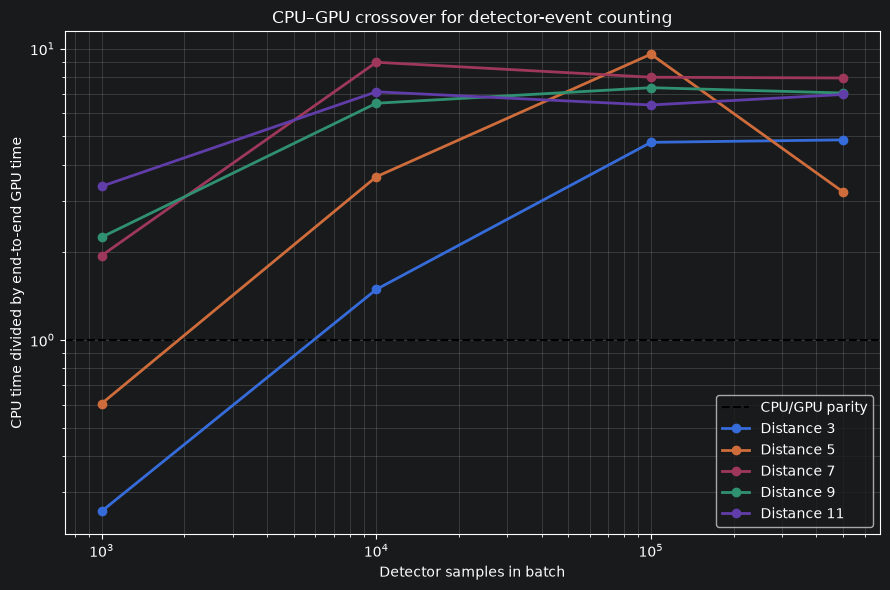

In [22]:
# Plot end-to-end speedup
figure, axis = plt.subplots(
    figsize=(9, 6)
)

axis.axhline(
    1.0,
    color="black",
    linestyle="--",
    linewidth=1.5,
    label="CPU/GPU parity",
)

for distance in DISTANCES:
    subset = gpu_preprocessing_df[
        gpu_preprocessing_df[
            "distance"
        ] == distance
    ].sort_values(
        "shots"
    )

    axis.plot(
        subset["shots"],
        subset[
            "end_to_end_speedup"
        ],
        marker="o",
        linewidth=2,
        label=f"Distance {distance}",
    )

axis.set_xscale("log")
axis.set_yscale("log")

axis.set_xlabel(
    "Detector samples in batch"
)

axis.set_ylabel(
    "CPU time divided by "
    "end-to-end GPU time"
)

axis.set_title(
    "CPU–GPU crossover for detector-event counting"
)

axis.grid(
    True,
    which="both",
    alpha=0.3,
)

axis.legend()

figure.tight_layout()

gpu_crossover_figure_path = (
    FIGURE_DIR
    / "gpu_event_count_crossover.png"
)

figure.savefig(
    gpu_crossover_figure_path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

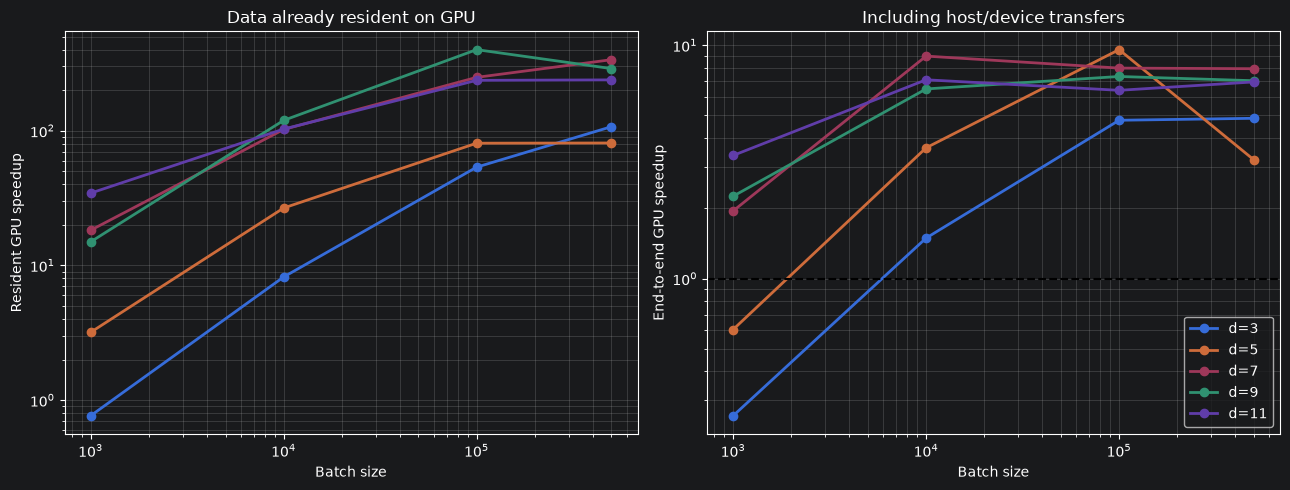

In [23]:
# Plot resident and end-to-end speedup
figure, axes = plt.subplots(
    1,
    2,
    figsize=(13, 5),
)

for distance in DISTANCES:
    subset = gpu_preprocessing_df[
        gpu_preprocessing_df[
            "distance"
        ] == distance
    ].sort_values(
        "shots"
    )

    axes[0].plot(
        subset["shots"],
        subset[
            "resident_speedup"
        ],
        marker="o",
        linewidth=2,
        label=f"d={distance}",
    )

    axes[1].plot(
        subset["shots"],
        subset[
            "end_to_end_speedup"
        ],
        marker="o",
        linewidth=2,
        label=f"d={distance}",
    )

axes[0].set_xscale("log")
axes[0].set_yscale("log")
axes[0].set_xlabel("Batch size")
axes[0].set_ylabel("Resident GPU speedup")
axes[0].set_title(
    "Data already resident on GPU"
)
axes[0].grid(
    True,
    which="both",
    alpha=0.3,
)

axes[1].axhline(
    1.0,
    color="black",
    linestyle="--",
    linewidth=1.5,
)

axes[1].set_xscale("log")
axes[1].set_yscale("log")
axes[1].set_xlabel("Batch size")
axes[1].set_ylabel(
    "End-to-end GPU speedup"
)
axes[1].set_title(
    "Including host/device transfers"
)
axes[1].grid(
    True,
    which="both",
    alpha=0.3,
)

axes[1].legend()

figure.tight_layout()

gpu_speedup_figure_path = (
    FIGURE_DIR
    / "gpu_speedup_by_distance.png"
)

figure.savefig(
    gpu_speedup_figure_path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

In [24]:
# GPU timing breakdown
largest_batch_rows = (
    gpu_preprocessing_df
    .sort_values(
        "shots"
    )
    .groupby(
        "distance",
        as_index=False,
    )
    .tail(1)
    .sort_values(
        "distance"
    )
)

largest_batch_rows[
    [
        "distance",
        "shots",
        "detectors",
        "host_to_device_ms",
        "gpu_kernel_ms",
        "device_to_host_ms",
        "gpu_end_to_end_ms",
    ]
]

,distance,shots,detectors,host_to_device_ms,gpu_kernel_ms,device_to_host_ms,gpu_end_to_end_ms
3,3,500000,24,0.58590,0.06955,0.55235,1.53130
7,5,500000,120,3.18970,0.31270,0.97710,7.85795
11,7,500000,336,9.48195,0.24350,0.70980,10.33010
15,9,500000,720,20.50720,0.51860,0.69125,21.27625
19,11,500000,1320,35.09365,1.07965,0.63965,36.95325


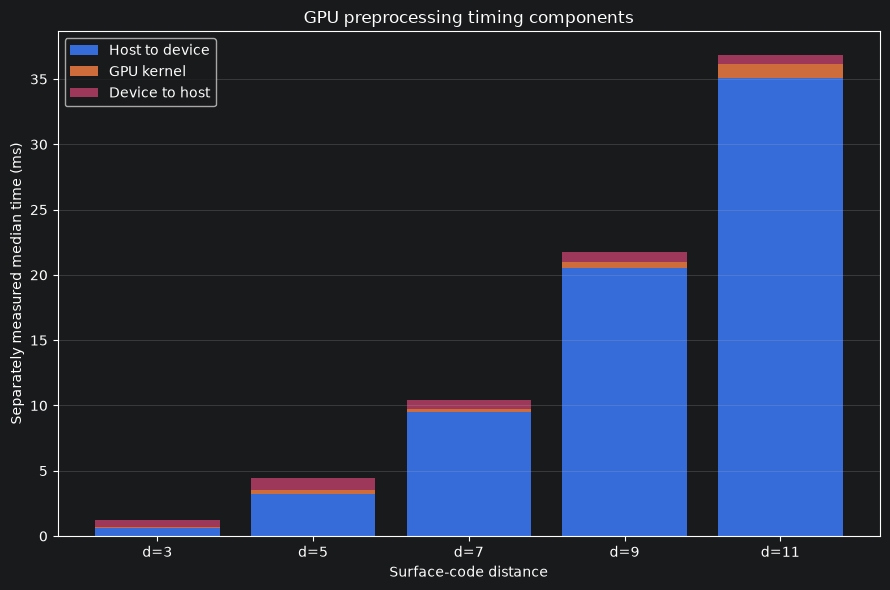

In [25]:
# Plot
figure, axis = plt.subplots(
    figsize=(9, 6)
)

x_positions = np.arange(
    len(
        largest_batch_rows
    )
)

host_to_device = (
    largest_batch_rows[
        "host_to_device_ms"
    ].to_numpy()
)

gpu_kernel = (
    largest_batch_rows[
        "gpu_kernel_ms"
    ].to_numpy()
)

device_to_host = (
    largest_batch_rows[
        "device_to_host_ms"
    ].to_numpy()
)

axis.bar(
    x_positions,
    host_to_device,
    label="Host to device",
)

axis.bar(
    x_positions,
    gpu_kernel,
    bottom=host_to_device,
    label="GPU kernel",
)

axis.bar(
    x_positions,
    device_to_host,
    bottom=(
        host_to_device
        + gpu_kernel
    ),
    label="Device to host",
)

axis.set_xticks(
    x_positions
)

axis.set_xticklabels(
    [
        f"d={distance}"
        for distance in (
            largest_batch_rows[
                "distance"
            ]
        )
    ]
)

axis.set_xlabel(
    "Surface-code distance"
)

axis.set_ylabel(
    "Separately measured median time (ms)"
)

axis.set_title(
    "GPU preprocessing timing components"
)

axis.grid(
    axis="y",
    alpha=0.3,
)

axis.legend()

figure.tight_layout()

gpu_breakdown_figure_path = (
    FIGURE_DIR
    / "gpu_transfer_breakdown.png"
)

figure.savefig(
    gpu_breakdown_figure_path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

Note: Individual pipeline stages (H2D transfer, resident kernel execution, and D2H transfer) were benchmarked independently. Because medians are non-linear statistics, their sum does not equal the independently measured end-to-end median.

## Bit-Packed Detector Transfers

Stim detector samples are returned as dense Boolean NumPy arrays (`bool` / `uint8`), meaning each detector outcome occupies $1\text{ byte}$ in host memory despite carrying only $1\text{ bit}$ of information.

Packing eight detector outcomes into a single byte reduces the host-to-device (H2D) PCIe transfer payload by roughly $8\times$:

$$
B_{\mathrm{packed}} = N_{\mathrm{shots}} \left\lceil \frac{N_{\mathrm{detectors}}}{8} \right\rceil.
$$

However, a bit-packed GPU pipeline introduces additional host and device computation across four stages:

1. **Host Bit Packing:** Pack the unpacked Boolean matrix into byte-aligned bitfields on the CPU.
2. **H2D Transfer:** Copy the compressed $B_{\mathrm{packed}}$ payload across PCIe to GPU memory.
3. **Device Execution:** Unpack or directly reduce (e.g., via population count) the bit-packed representation on the GPU.
4. **D2H Transfer:** Return the resulting per-shot event counts to host memory.

A fair end-to-end comparison must therefore account for both CPU packing overhead and GPU reduction/unpacking time, rather than reporting the reduced PCIe copy latency alone.


In [26]:
# Add packed-byte event counting

from time import perf_counter

POPCOUNT_LOOKUP_CPU = np.array(
    [
        int(value).bit_count()
        for value in range(256)
    ],
    dtype=np.uint8,
)

POPCOUNT_LOOKUP_GPU = cp.asarray(
    POPCOUNT_LOOKUP_CPU
)

# Count detector events from a CuPy uint8 packed matrix using a 256-entry population-count table
def gpu_counts_from_packed_bytes(
    packed_events,
):

    if not isinstance(
        packed_events,
        cp.ndarray,
    ):
        raise TypeError(
            "packed_events must be a CuPy array."
        )

    if packed_events.ndim != 2:
        raise ValueError(
            "packed_events must be two-dimensional."
        )

    if packed_events.dtype != cp.uint8:
        raise TypeError(
            "packed_events must have dtype uint8."
        )

    byte_counts = POPCOUNT_LOOKUP_GPU[
        packed_events
    ]

    return byte_counts.sum(
        axis=1,
        dtype=cp.int64,
    )

In [27]:
# Validate packed GPU counting
validation_packed_cpu = (
    cpu_pack_detector_bits(
        validation_events
    )
)

validation_packed_gpu = cp.asarray(
    validation_packed_cpu
)

validation_packed_counts_gpu = (
    gpu_counts_from_packed_bytes(
        validation_packed_gpu
    )
)

validation_packed_counts_cpu = cp.asnumpy(
    validation_packed_counts_gpu
)

cp.cuda.Stream.null.synchronize()

assert np.array_equal(
    validation_packed_counts_cpu,
    cpu_counts,
)

print(
    "Packed GPU population counting agrees with dense CPU counting."
)

print(
    "Dense input MiB:",
    validation_events.nbytes / 1024**2,
)

print(
    "Packed input MiB:",
    validation_packed_cpu.nbytes / 1024**2,
)

print(
    "Compression ratio:",
    validation_events.nbytes
    / validation_packed_cpu.nbytes,
)

Packed GPU population counting agrees with dense CPU counting.
Dense input MiB: 2.4509429931640625
Packed input MiB: 0.3147125244140625
Compression ratio: 7.787878787878788


In [28]:
# Create synchronised timing helper
# Return median wall-clock execution time
def median_seconds(
    function,
    repeats=10,
):

    elapsed_times = []

    for _ in range(repeats):
        start_time = perf_counter()

        function()

        end_time = perf_counter()

        elapsed_times.append(
            end_time - start_time
        )

    return float(
        np.median(
            elapsed_times
        )
    )

In [29]:
# Create the packed-pipeline benchmark
# Compare dense and packed GPU event-counting pipelines

# The packed end-to-end measurement includes:
# CPU packing, packed host-to-device transfer, GPU population counting, result transfer to the CPU
def benchmark_packed_event_counting(
    detection_events,
    repeats=10,
    warm_up_repeats=3,
):

    events = np.asarray(
        detection_events,
        dtype=np.bool_,
    )

    if events.ndim != 2:
        raise ValueError(
            "detection_events must be two-dimensional."
        )

    shots, detectors = events.shape

    # Warm up NumPy packing.
    for _ in range(warm_up_repeats):
        np.packbits(
            events,
            axis=1,
            bitorder="little",
        )

    cpu_pack_seconds = median_seconds(
        lambda: np.packbits(
            events,
            axis=1,
            bitorder="little",
        ),
        repeats=repeats,
    )

    packed_cpu = np.packbits(
        events,
        axis=1,
        bitorder="little",
    )

    # Prepare a resident packed GPU matrix.
    packed_gpu = cp.asarray(
        packed_cpu
    )

    for _ in range(warm_up_repeats):
        gpu_counts_from_packed_bytes(
            packed_gpu
        )

        cp.cuda.Stream.null.synchronize()

    def packed_h2d_operation():
        cp.asarray(
            packed_cpu
        )

        cp.cuda.Stream.null.synchronize()

    packed_h2d_seconds = median_seconds(
        packed_h2d_operation,
        repeats=repeats,
    )

    def packed_kernel_operation():
        gpu_counts_from_packed_bytes(
            packed_gpu
        )

        cp.cuda.Stream.null.synchronize()

    packed_kernel_seconds = median_seconds(
        packed_kernel_operation,
        repeats=repeats,
    )

    packed_gpu_counts = (
        gpu_counts_from_packed_bytes(
            packed_gpu
        )
    )

    cp.cuda.Stream.null.synchronize()

    def packed_d2h_operation():
        cp.asnumpy(
            packed_gpu_counts
        )

        cp.cuda.Stream.null.synchronize()

    packed_d2h_seconds = median_seconds(
        packed_d2h_operation,
        repeats=repeats,
    )

    # Complete pipeline, including CPU-side packing.
    def packed_end_to_end_operation():
        local_packed_cpu = np.packbits(
            events,
            axis=1,
            bitorder="little",
        )

        local_packed_gpu = cp.asarray(
            local_packed_cpu
        )

        local_gpu_counts = (
            gpu_counts_from_packed_bytes(
                local_packed_gpu
            )
        )

        cp.asnumpy(
            local_gpu_counts
        )

        cp.cuda.Stream.null.synchronize()

    packed_end_to_end_seconds = (
        median_seconds(
            packed_end_to_end_operation,
            repeats=repeats,
        )
    )

    # Resident path assumes data is already packed
    # and present on the GPU.
    packed_resident_seconds = (
        packed_kernel_seconds
        + packed_d2h_seconds
    )

    dense_timing = benchmark_event_counting(
        events,
        repeats=repeats,
        warm_up_repeats=warm_up_repeats,
    )

    result = {
        "shots": shots,
        "detectors": detectors,
        "dense_bytes": events.nbytes,
        "packed_bytes": packed_cpu.nbytes,
        "compression_ratio": (
            events.nbytes
            / packed_cpu.nbytes
        ),
        "cpu_dense_count_ms": (
            dense_timing.cpu_seconds
            * 1_000
        ),
        "cpu_pack_ms": (
            cpu_pack_seconds
            * 1_000
        ),
        "dense_h2d_ms": (
            dense_timing
            .host_to_device_seconds
            * 1_000
        ),
        "packed_h2d_ms": (
            packed_h2d_seconds
            * 1_000
        ),
        "dense_gpu_kernel_ms": (
            dense_timing
            .gpu_kernel_seconds
            * 1_000
        ),
        "packed_gpu_kernel_ms": (
            packed_kernel_seconds
            * 1_000
        ),
        "packed_d2h_ms": (
            packed_d2h_seconds
            * 1_000
        ),
        "dense_end_to_end_ms": (
            dense_timing
            .gpu_end_to_end_seconds
            * 1_000
        ),
        "packed_end_to_end_ms": (
            packed_end_to_end_seconds
            * 1_000
        ),
        "packed_resident_ms": (
            packed_resident_seconds
            * 1_000
        ),
        "packed_vs_dense_transfer_speedup": (
            dense_timing
            .host_to_device_seconds
            / packed_h2d_seconds
        ),
        "packed_vs_dense_pipeline_speedup": (
            dense_timing
            .gpu_end_to_end_seconds
            / packed_end_to_end_seconds
        ),
        "packed_vs_cpu_speedup": (
            dense_timing.cpu_seconds
            / packed_end_to_end_seconds
        ),
    }

    del packed_gpu
    del packed_gpu_counts

    release_gpu_memory()

    return result

In [30]:
# Test packed benchmark on the synthetic matrix
packed_smoke_result = (
    benchmark_packed_event_counting(
        synthetic_events,
        repeats=10,
        warm_up_repeats=3,
    )
)

pd.Series(
    packed_smoke_result
)

shots                               1.000000e+05
detectors                           1.000000e+03
dense_bytes                         1.000000e+08
packed_bytes                        1.250000e+07
compression_ratio                   8.000000e+00
cpu_dense_count_ms                  4.074090e+01
cpu_pack_ms                         5.489300e+00
dense_h2d_ms                        5.027350e+00
packed_h2d_ms                       6.944000e-01
dense_gpu_kernel_ms                 9.354996e-02
packed_gpu_kernel_ms                1.165000e-01
packed_d2h_ms                       6.625004e-02
dense_end_to_end_ms                 4.787150e+00
packed_end_to_end_ms                6.409600e+00
packed_resident_ms                  1.827500e-01
packed_vs_dense_transfer_speedup    7.239848e+00
packed_vs_dense_pipeline_speedup    7.468719e-01
packed_vs_cpu_speedup               6.356231e+00
dtype: float64

In [31]:
# Validation
assert (
    packed_smoke_result[
        "compression_ratio"
    ] > 7.0
)

assert (
    packed_smoke_result[
        "packed_h2d_ms"
    ] > 0.0
)

assert (
    packed_smoke_result[
        "packed_gpu_kernel_ms"
    ] > 0.0
)

assert (
    packed_smoke_result[
        "packed_end_to_end_ms"
    ] > 0.0
)

print(
    "Packed detector benchmark passed."
)

Packed detector benchmark passed.


In [32]:
# Save
packed_smoke_path = (
    RESULTS_DIR
    / "gpu_packed_smoke_benchmark.csv"
)

pd.DataFrame(
    [packed_smoke_result]
).to_csv(
    packed_smoke_path,
    index=False,
)

print(
    f"Saved packed smoke benchmark to: "
    f"{packed_smoke_path}"
)

Saved packed smoke benchmark to: C:\Users\Karthi\Qauntum\results\gpu_packed_smoke_benchmark.csv


In [33]:
# Run packed benchmarks on real Stim workloads
PACKED_SWEEP_PATH = (
    RESULTS_DIR
    / "gpu_packed_detector_preprocessing.csv"
)

if PACKED_SWEEP_PATH.exists():
    existing_packed_df = pd.read_csv(
        PACKED_SWEEP_PATH
    )

    completed_packed_configurations = {
        (
            int(row["distance"]),
            int(row["shots"]),
        )
        for row in existing_packed_df.to_dict(
            orient="records"
        )
    }

    packed_sweep_results = (
        existing_packed_df.to_dict(
            orient="records"
        )
    )

    print(
        f"Loaded "
        f"{len(completed_packed_configurations)} "
        "completed packed configurations."
    )
else:
    completed_packed_configurations = set()
    packed_sweep_results = []

    print(
        "Starting a new packed-data sweep."
    )

Starting a new packed-data sweep.


In [34]:
# Run
configuration_index = 0

for distance in DISTANCES:
    for batch_size in BATCH_SIZES:
        configuration_index += 1

        configuration_key = (
            distance,
            batch_size,
        )

        if (
            configuration_key
            in completed_packed_configurations
        ):
            print(
                f"Skipping completed packed "
                f"configuration: "
                f"d={distance}, "
                f"shots={batch_size:,}"
            )

            continue

        print()
        print(
            f"Packed benchmark: "
            f"d={distance}, "
            f"shots={batch_size:,}"
        )

        noise_model = (
            CircuitNoiseModel.symmetric(
                PHYSICAL_ERROR_PROBABILITY
            )
        )

        circuit = (
            create_rotated_surface_code_circuit(
                distance=distance,
                rounds=distance,
                noise_model=noise_model,
                memory_basis="x",
            )
        )

        sampler = compile_detector_sampler(
            circuit,
            seed=(
                SEED
                + 20_000
                + configuration_index
            ),
        )

        samples = sample_detection_events(
            sampler,
            number_of_shots=batch_size,
        )

        detection_events = (
            samples.detection_events
        )

        benchmark_result = (
            benchmark_packed_event_counting(
                detection_events,
                repeats=BENCHMARK_REPEATS,
                warm_up_repeats=3,
            )
        )

        benchmark_result.update(
            {
                "distance": distance,
                "rounds": distance,
                "physical_error_probability": (
                    PHYSICAL_ERROR_PROBABILITY
                ),
                "qubits": circuit.num_qubits,
                "measurements": (
                    circuit.num_measurements
                ),
                "mean_detection_events": float(
                    detection_events.sum(
                        axis=1
                    ).mean()
                ),
                "zero_event_fraction": float(
                    cpu_zero_event_mask(
                        detection_events
                    ).mean()
                ),
            }
        )

        packed_sweep_results.append(
            benchmark_result
        )

        completed_packed_configurations.add(
            configuration_key
        )

        pd.DataFrame(
            packed_sweep_results
        ).sort_values(
            [
                "distance",
                "shots",
            ]
        ).to_csv(
            PACKED_SWEEP_PATH,
            index=False,
        )

        print(
            f"  Dense H2D: "
            f"{benchmark_result['dense_h2d_ms']:.4f} ms"
        )

        print(
            f"  Packed H2D: "
            f"{benchmark_result['packed_h2d_ms']:.4f} ms"
        )

        print(
            f"  CPU packing: "
            f"{benchmark_result['cpu_pack_ms']:.4f} ms"
        )

        print(
            f"  Dense total: "
            f"{benchmark_result['dense_end_to_end_ms']:.4f} ms"
        )

        print(
            f"  Packed total: "
            f"{benchmark_result['packed_end_to_end_ms']:.4f} ms"
        )

        print(
            f"  Packed versus dense total: "
            f"{benchmark_result['packed_vs_dense_pipeline_speedup']:.3f}x"
        )

        del samples
        del detection_events
        del sampler
        del circuit

        release_gpu_memory()


Packed benchmark: d=3, shots=1,000
  Dense H2D: 0.0226 ms
  Packed H2D: 0.0564 ms
  CPU packing: 0.0091 ms
  Dense total: 0.0922 ms
  Packed total: 0.1371 ms
  Packed versus dense total: 0.672x

Packed benchmark: d=3, shots=10,000
  Dense H2D: 0.0414 ms
  Packed H2D: 0.0297 ms
  CPU packing: 0.0841 ms
  Dense total: 0.0885 ms
  Packed total: 0.1813 ms
  Packed versus dense total: 0.488x

Packed benchmark: d=3, shots=100,000
  Dense H2D: 0.1370 ms
  Packed H2D: 0.0460 ms
  CPU packing: 0.8543 ms
  Dense total: 0.2679 ms
  Packed total: 1.1018 ms
  Packed versus dense total: 0.243x

Packed benchmark: d=3, shots=500,000
  Dense H2D: 0.5242 ms
  Packed H2D: 0.1132 ms
  CPU packing: 4.4689 ms
  Dense total: 1.3449 ms
  Packed total: 5.2658 ms
  Packed versus dense total: 0.255x

Packed benchmark: d=5, shots=1,000
  Dense H2D: 0.0407 ms
  Packed H2D: 0.0297 ms
  CPU packing: 0.0125 ms
  Dense total: 0.0850 ms
  Packed total: 0.1443 ms
  Packed versus dense total: 0.589x

Packed benchmark: d

In [35]:
# Load and validate packed result
packed_preprocessing_df = pd.read_csv(
    PACKED_SWEEP_PATH
).sort_values(
    [
        "distance",
        "shots",
    ]
).reset_index(
    drop=True
)

assert (
    len(packed_preprocessing_df)
    == len(DISTANCES) * len(BATCH_SIZES)
)

assert (
    packed_preprocessing_df[
        "compression_ratio"
    ] > 1.0
).all()

assert (
    packed_preprocessing_df[
        "packed_end_to_end_ms"
    ] > 0.0
).all()

print(
    f"Validated "
    f"{len(packed_preprocessing_df)} "
    "packed-data configurations."
)

packed_preprocessing_df.head()

Validated 20 packed-data configurations.


,shots,detectors,dense_bytes,packed_bytes,compression_ratio,cpu_dense_count_ms,cpu_pack_ms,dense_h2d_ms,packed_h2d_ms,dense_gpu_kernel_ms,...,packed_vs_dense_transfer_speedup,packed_vs_dense_pipeline_speedup,packed_vs_cpu_speedup,distance,rounds,physical_error_probability,qubits,measurements,mean_detection_events,zero_event_fraction
0,1000,24,24000,3000,8.0,0.01465,0.0091,0.02265,0.05645,0.01470,...,0.401239,0.672137,0.106856,3,3,0.003,26,33,0.979000,0.560000
1,10000,24,240000,30000,8.0,0.13055,0.0841,0.04140,0.02970,0.01660,...,1.393941,0.487731,0.719878,3,3,0.003,26,33,0.888900,0.594600
2,100000,24,2400000,300000,8.0,1.30570,0.8543,0.13700,0.04595,0.02530,...,2.981501,0.243148,1.185061,3,3,0.003,26,33,0.896810,0.597420
3,500000,24,12000000,1500000,8.0,7.06020,4.4689,0.52420,0.11325,0.06955,...,4.628698,0.255405,1.340778,3,3,0.003,26,33,0.890702,0.599412
4,1000,120,120000,15000,8.0,0.05065,0.0125,0.04070,0.02965,0.01430,...,1.372680,0.589051,0.351005,5,5,0.003,64,145,5.286000,0.076000


In [36]:
packed_column_aliases = {
    "packed_vs_dense_pipeline_speedup": (
        "packed_vs_dense_speedup"
    ),
    "packed_vs_dense_transfer_speedup": (
        "packed_transfer_speedup"
    ),
}

for old_name, canonical_name in (
    packed_column_aliases.items()
):
    if (
        old_name
        in packed_preprocessing_df.columns
        and canonical_name
        not in packed_preprocessing_df.columns
    ):
        packed_preprocessing_df[
            canonical_name
        ] = packed_preprocessing_df[
            old_name
        ]

if (
    "packed_transfer_speedup"
    not in packed_preprocessing_df.columns
):
    packed_preprocessing_df[
        "packed_transfer_speedup"
    ] = (
        packed_preprocessing_df[
            "dense_h2d_ms"
        ]
        / packed_preprocessing_df[
            "packed_h2d_ms"
        ]
    )

if (
    "packed_vs_dense_speedup"
    not in packed_preprocessing_df.columns
):
    packed_preprocessing_df[
        "packed_vs_dense_speedup"
    ] = (
        packed_preprocessing_df[
            "dense_end_to_end_ms"
        ]
        / packed_preprocessing_df[
            "packed_end_to_end_ms"
        ]
    )

if (
    "packed_vs_cpu_speedup"
    not in packed_preprocessing_df.columns
):
    packed_preprocessing_df[
        "packed_vs_cpu_speedup"
    ] = (
        packed_preprocessing_df[
            "cpu_dense_count_ms"
        ]
        / packed_preprocessing_df[
            "packed_end_to_end_ms"
        ]
    )

required_speedup_columns = [
    "packed_transfer_speedup",
    "packed_vs_dense_speedup",
    "packed_vs_cpu_speedup",
]

missing_speedup_columns = [
    column_name
    for column_name in required_speedup_columns
    if column_name not in packed_preprocessing_df.columns
]

assert not missing_speedup_columns, (
    "Missing packed speedup columns: "
    f"{missing_speedup_columns}"
)

print(
    "Packed result schema is ready:",
    required_speedup_columns,
)

Packed result schema is ready: ['packed_transfer_speedup', 'packed_vs_dense_speedup', 'packed_vs_cpu_speedup']


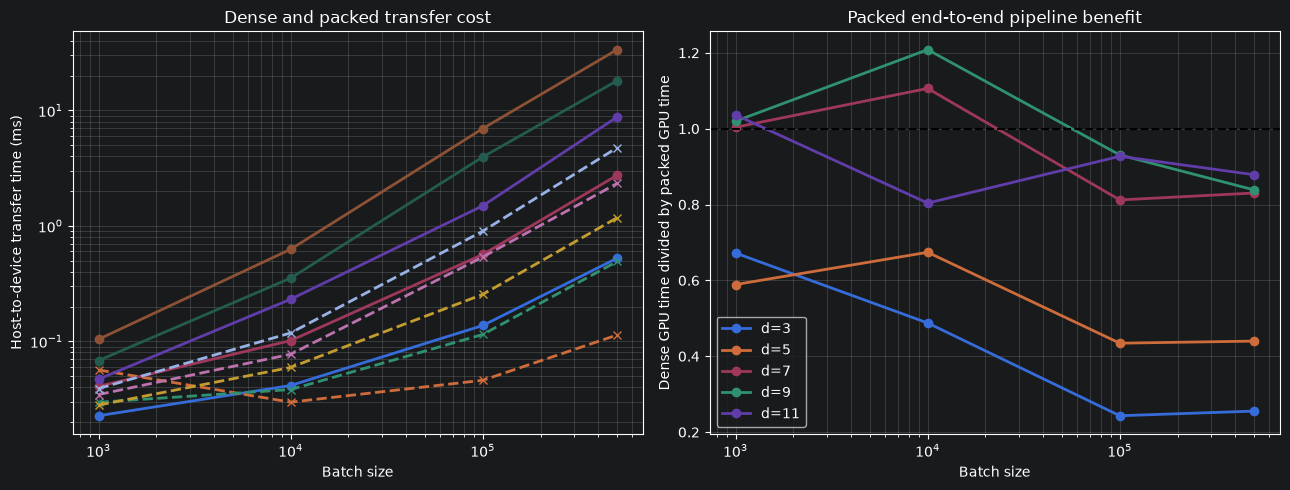

In [37]:
# Plot dense versus packed transfer time
figure, axes = plt.subplots(
    1,
    2,
    figsize=(13, 5),
)

for distance in DISTANCES:
    subset = packed_preprocessing_df[
        packed_preprocessing_df[
            "distance"
        ] == distance
    ].sort_values(
        "shots"
    )

    axes[0].plot(
        subset["shots"],
        subset["dense_h2d_ms"],
        marker="o",
        linewidth=2,
        label=f"Dense d={distance}",
    )

    axes[0].plot(
        subset["shots"],
        subset["packed_h2d_ms"],
        marker="x",
        linestyle="--",
        linewidth=2,
        label=f"Packed d={distance}",
    )

    axes[1].plot(
        subset["shots"],
        subset[
            "packed_vs_dense_speedup"
        ],
        marker="o",
        linewidth=2,
        label=f"d={distance}",
    )

axes[0].set_xscale("log")
axes[0].set_yscale("log")
axes[0].set_xlabel("Batch size")
axes[0].set_ylabel(
    "Host-to-device transfer time (ms)"
)
axes[0].set_title(
    "Dense and packed transfer cost"
)
axes[0].grid(
    True,
    which="both",
    alpha=0.3,
)

axes[1].axhline(
    1.0,
    color="black",
    linestyle="--",
    linewidth=1.5,
)

axes[1].set_xscale("log")
axes[1].set_xlabel("Batch size")
axes[1].set_ylabel(
    "Dense GPU time divided by "
    "packed GPU time"
)
axes[1].set_title(
    "Packed end-to-end pipeline benefit"
)
axes[1].grid(
    True,
    which="both",
    alpha=0.3,
)

axes[1].legend()

figure.tight_layout()

packed_transfer_figure_path = (
    FIGURE_DIR
    / "gpu_packed_transfer_comparison.png"
)

figure.savefig(
    packed_transfer_figure_path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

## Packed-Transfer Interpretation

Bit packing compressed the detector payload to roughly one-eighth of the dense Boolean representation, substantially reducing host-to-device (H2D) PCIe transfer latency. However, because the complete pipeline still incurred CPU-side bit packing and GPU-side population counting (`popcount`), lower transfer time did not guarantee an end-to-end speedup across all batch sizes.

### When Bit Packing Pays Off
A bit-packed representation is most advantageous when:
* **Large Payloads:** Detector matrices are large enough that PCIe bandwidth dominates execution time;
* **Constrained Interconnects:** Data must traverse bandwidth-limited links;
* **Native Upstream Packing:** Bit-packed syndromes are emitted directly by the upstream source rather than unpacked first;
* **Multi-Kernel Reuse:** Multiple downstream GPU kernels consume the same packed representation in device memory;
* **Zero or Hidden Packing Cost:** CPU packing can be bypassed entirely or overlapped asynchronously with other work.

### Architectural Implications
When unpacked Stim detector arrays must be packed synchronously on the CPU for every batch, host packing overhead can offset much or all of the PCIe transfer savings. In a production quantum-classical architecture, syndrome readout electronics or an intermediate FPGA layer would emit bit-packed detector frames directly—eliminating host-side packing overhead altogether.


## Hybrid GPU Filtering and CPU Decoding

At low physical error rates, a substantial fraction of circuit shots produce zero detection events. While PyMatching can decode empty syndromes directly, a trivial all-zero syndrome deterministically yields an all-zero logical correction (assuming no unconditional background frame flip).

### Hybrid Execution Pipeline
To avoid dispatching trivial shots to the MWPM decoder, a hybrid GPU–CPU pipeline executes five stages:

1. **H2D Transfer:** Copy detector samples from host RAM to GPU memory.
2. **GPU Nonzero Masking:** Identify rows containing at least one detection event (`any(axis=1)`).
3. **D2H Mask Transfer:** Return the compact 1D Boolean filtering mask to the host CPU.
4. **Filtered CPU Decoding:** Slice the active rows and decode only nonzero-syndrome shots with PyMatching.
5. **Prediction Reconstruction:** Scatter the decoded corrections back into a full-batch output array in the original shot order.

This optimisation is valid if and only if the reconstructed logical predictions match those produced by decoding the unfiltered batch identically.

### Benchmark Breakdown
To isolate where time is spent, the benchmark separates execution into six components:
* **Full PyMatching baseline:** End-to-end batch decoding of all shots on the CPU;
* **GPU filtering time:** H2D transfer, kernel evaluation, and D2H mask return;
* **CPU row-selection time:** Host-side Boolean indexing of active detector rows;
* **Filtered PyMatching time:** CPU decoding of the reduced nonzero-event subset;
* **Result-reconstruction time:** Reassembling full-length prediction arrays;
* **Total hybrid time:** Combined end-to-end latency across all hybrid stages.

A high zero-event fraction does not automatically guarantee an end-to-end speedup, as GPU data transfers, Boolean mask indexing, and reduced batch amortisation in PyMatching all introduce overhead.


In [38]:
# Timing and filtering helpers
from dataclasses import dataclass

# Results from one hybrid filtering benchmark
@dataclass(frozen=True)
class HybridFilterResult:

    shots: int
    detectors: int
    observables: int
    zero_event_shots: int
    nonzero_event_shots: int
    zero_event_fraction: float
    full_decode_seconds: float
    gpu_filter_seconds: float
    cpu_selection_seconds: float
    filtered_decode_seconds: float
    reconstruction_seconds: float
    hybrid_total_seconds: float
    predictions_equal: bool

    @property
    # Return full-decode time divided by hybrid time
    def hybrid_speedup(self):

        return (
            self.full_decode_seconds
            / self.hybrid_total_seconds
        )

    @property
    # Return the fraction sent to PyMatching
    def decoded_fraction(self):

        return (
            self.nonzero_event_shots
            / self.shots
        )

In [39]:
# GPU mask function that keeps the mask on the device until it is ready to return
# Return a CPU mask selecting nonzero-event rows
def gpu_nonzero_event_mask(
    detection_events,
):

    gpu_events = cp.asarray(
        detection_events
    )

    gpu_mask = gpu_events.any(
        axis=1
    )

    mask = cp.asnumpy(
        gpu_mask
    )

    cp.cuda.Stream.null.synchronize()

    return mask

In [40]:
# Validate the zero-syndrome assumption
# Confirm that an all-zero detector syndrome produces an all-zero logical prediction
def validate_empty_syndrome_prediction(
    decoder,
    observables,
):

    zero_syndrome = np.zeros(
        (
            1,
            decoder.num_detectors,
        ),
        dtype=np.bool_,
    )

    prediction = decoder.decode_batch(
        zero_syndrome
    )

    expected = np.zeros(
        (
            1,
            observables,
        ),
        dtype=prediction.dtype,
    )

    if not np.array_equal(
        prediction,
        expected,
    ):
        raise RuntimeError(
            "The decoder did not return an all-zero prediction for an empty syndrome."
        )

    return prediction

In [41]:
# Distance-3 circuit test
validation_noise_model = (
    CircuitNoiseModel.symmetric(
        PHYSICAL_ERROR_PROBABILITY
    )
)

validation_circuit = (
    create_rotated_surface_code_circuit(
        distance=3,
        rounds=3,
        noise_model=validation_noise_model,
        memory_basis="x",
    )
)

validation_decoder = (
    create_matching_decoder(
        build_detector_error_model(
            validation_circuit
        )
    )
)

empty_prediction = (
    validate_empty_syndrome_prediction(
        validation_decoder,
        validation_circuit.num_observables,
    )
)

print(
    "Empty-syndrome prediction:",
    empty_prediction.astype(int),
)

Empty-syndrome prediction: [[0]]


In [42]:
# Implement the hybrid prediction function
# Decode only rows containing detection events
#
# Returns reconstructed predictions and the mask used to select nonzero-event rows
def decode_with_gpu_zero_event_filter(
    decoder,
    detection_events,
    number_of_observables,
):

    events = np.asarray(
        detection_events,
        dtype=np.bool_,
    )

    if events.ndim != 2:
        raise ValueError(
            "detection_events must be two-dimensional"
        )

    nonzero_mask = gpu_nonzero_event_mask(
        events
    )

    retained_events = events[
        nonzero_mask
    ]

    predictions = np.zeros(
        (
            events.shape[0],
            number_of_observables,
        ),
        dtype=np.uint8,
    )

    if retained_events.shape[0] > 0:
        retained_predictions = (
            decoder.decode_batch(
                retained_events
            )
        )

        predictions[
            nonzero_mask
        ] = retained_predictions

    return predictions, nonzero_mask

In [43]:
# Validate correctness on real Stim data
# Moderate real workload
hybrid_validation_distance = 5
hybrid_validation_shots = 50_000

hybrid_validation_circuit = (
    create_rotated_surface_code_circuit(
        distance=hybrid_validation_distance,
        rounds=hybrid_validation_distance,
        noise_model=validation_noise_model,
        memory_basis="x",
    )
)

hybrid_validation_decoder = (
    create_matching_decoder(
        build_detector_error_model(
            hybrid_validation_circuit
        )
    )
)

hybrid_validation_sampler = (
    compile_detector_sampler(
        hybrid_validation_circuit,
        seed=SEED + 30_000,
    )
)

hybrid_validation_samples = (
    sample_detection_events(
        hybrid_validation_sampler,
        number_of_shots=(
            hybrid_validation_shots
        ),
    )
)

In [44]:
# Compare predictions
full_predictions = (
    hybrid_validation_decoder.decode_batch(
        hybrid_validation_samples.detection_events
    )
)

filtered_predictions, nonzero_mask = (
    decode_with_gpu_zero_event_filter(
        hybrid_validation_decoder,
        hybrid_validation_samples.detection_events,
        hybrid_validation_circuit.num_observables,
    )
)

assert np.array_equal(
    full_predictions,
    filtered_predictions,
)

print(
    "Filtered predictions exactly match "
    "full-batch PyMatching predictions."
)

print(
    "Zero-event fraction:",
    f"{1.0 - nonzero_mask.mean():.2%}",
)

print(
    "Rows sent to PyMatching:",
    f"{nonzero_mask.sum():,} / "
    f"{len(nonzero_mask):,}",
)

Filtered predictions exactly match full-batch PyMatching predictions.
Zero-event fraction: 7.49%
Rows sent to PyMatching: 46,255 / 50,000


In [45]:
# Compare complete PyMatching decoding with GPU zero-event filtering followed by CPU decoding
def benchmark_hybrid_filtering(
    decoder,
    detection_events,
    number_of_observables,
    repeats=10,
    warm_up_repeats=3,
):

    events = np.asarray(
        detection_events,
        dtype=np.bool_,
    )

    if events.ndim != 2:
        raise ValueError(
            "detection_events must be two-dimensional"
        )

    shots, detectors = events.shape

    validate_empty_syndrome_prediction(
        decoder,
        number_of_observables,
    )

    for _ in range(warm_up_repeats):
        decoder.decode_batch(
            events
        )

        decode_with_gpu_zero_event_filter(
            decoder,
            events,
            number_of_observables,
        )

    full_decode_times = []

    for _ in range(repeats):
        start = perf_counter()

        full_predictions = (
            decoder.decode_batch(
                events
            )
        )

        end = perf_counter()

        full_decode_times.append(
            end - start
        )

    full_decode_seconds = float(
        np.median(
            full_decode_times
        )
    )

    gpu_filter_times = []
    selection_times = []
    filtered_decode_times = []
    reconstruction_times = []
    hybrid_total_times = []

    final_predictions = None
    final_nonzero_mask = None

    for _ in range(repeats):
        total_start = perf_counter()

        filter_start = perf_counter()

        nonzero_mask = (
            gpu_nonzero_event_mask(
                events
            )
        )

        filter_end = perf_counter()

        selection_start = perf_counter()

        retained_events = events[
            nonzero_mask
        ]

        selection_end = perf_counter()

        decode_start = perf_counter()

        if retained_events.shape[0] > 0:
            retained_predictions = (
                decoder.decode_batch(
                    retained_events
                )
            )
        else:
            retained_predictions = np.empty(
                (
                    0,
                    number_of_observables,
                ),
                dtype=np.uint8,
            )

        decode_end = perf_counter()

        reconstruction_start = perf_counter()

        reconstructed_predictions = np.zeros(
            (
                shots,
                number_of_observables,
            ),
            dtype=(
                retained_predictions.dtype
                if retained_predictions.size
                else np.uint8
            ),
        )

        if retained_events.shape[0] > 0:
            reconstructed_predictions[
                nonzero_mask
            ] = retained_predictions

        reconstruction_end = perf_counter()

        total_end = perf_counter()

        gpu_filter_times.append(
            filter_end - filter_start
        )

        selection_times.append(
            selection_end - selection_start
        )

        filtered_decode_times.append(
            decode_end - decode_start
        )

        reconstruction_times.append(
            reconstruction_end
            - reconstruction_start
        )

        hybrid_total_times.append(
            total_end - total_start
        )

        final_predictions = (
            reconstructed_predictions
        )

        final_nonzero_mask = (
            nonzero_mask
        )

    predictions_equal = np.array_equal(
        full_predictions,
        final_predictions,
    )

    if not predictions_equal:
        raise AssertionError(
            "Hybrid predictions differ from full PyMatching predictions."
        )

    zero_event_shots = int(
        (
            ~final_nonzero_mask
        ).sum()
    )

    nonzero_event_shots = int(
        final_nonzero_mask.sum()
    )

    return HybridFilterResult(
        shots=shots,
        detectors=detectors,
        observables=number_of_observables,
        zero_event_shots=zero_event_shots,
        nonzero_event_shots=(
            nonzero_event_shots
        ),
        zero_event_fraction=(
            zero_event_shots / shots
        ),
        full_decode_seconds=(
            full_decode_seconds
        ),
        gpu_filter_seconds=float(
            np.median(
                gpu_filter_times
            )
        ),
        cpu_selection_seconds=float(
            np.median(
                selection_times
            )
        ),
        filtered_decode_seconds=float(
            np.median(
                filtered_decode_times
            )
        ),
        reconstruction_seconds=float(
            np.median(
                reconstruction_times
            )
        ),
        hybrid_total_seconds=float(
            np.median(
                hybrid_total_times
            )
        ),
        predictions_equal=(
            predictions_equal
        ),
    )

In [46]:
# Run one hybrid smoke benchmark
hybrid_smoke_result = (
    benchmark_hybrid_filtering(
        hybrid_validation_decoder,
        hybrid_validation_samples.detection_events,
        hybrid_validation_circuit.num_observables,
        repeats=10,
        warm_up_repeats=3,
    )
)

pd.Series(
    {
        "shots": hybrid_smoke_result.shots,
        "detectors": (
            hybrid_smoke_result.detectors
        ),
        "zero_event_fraction": (
            hybrid_smoke_result
            .zero_event_fraction
        ),
        "full_decode_ms": (
            hybrid_smoke_result
            .full_decode_seconds
            * 1_000
        ),
        "gpu_filter_ms": (
            hybrid_smoke_result
            .gpu_filter_seconds
            * 1_000
        ),
        "cpu_selection_ms": (
            hybrid_smoke_result
            .cpu_selection_seconds
            * 1_000
        ),
        "filtered_decode_ms": (
            hybrid_smoke_result
            .filtered_decode_seconds
            * 1_000
        ),
        "reconstruction_ms": (
            hybrid_smoke_result
            .reconstruction_seconds
            * 1_000
        ),
        "hybrid_total_ms": (
            hybrid_smoke_result
            .hybrid_total_seconds
            * 1_000
        ),
        "hybrid_speedup": (
            hybrid_smoke_result
            .hybrid_speedup
        ),
        "predictions_equal": (
            hybrid_smoke_result
            .predictions_equal
        ),
    }
)

shots                     50000
detectors                   120
zero_event_fraction      0.0749
full_decode_ms          50.4218
gpu_filter_ms            0.5327
cpu_selection_ms          0.936
filtered_decode_ms     49.91005
reconstruction_ms        0.1141
hybrid_total_ms         51.4982
hybrid_speedup         0.979098
predictions_equal          True
dtype: object

In [47]:
# Sweep distance, batch size, and noise (three levels)
HYBRID_NOISE_PROBABILITIES = [
    0.001,
    0.003,
    0.007,
]

HYBRID_DISTANCES = [
    3,
    5,
    7,
    9,
]

HYBRID_BATCH_SIZES = [
    10_000,
    100_000,
    500_000,
]

HYBRID_REPEATS = 10

HYBRID_RESULTS_PATH = (
    RESULTS_DIR
    / "gpu_hybrid_filtering.csv"
)

In [48]:
# Warning: took a very long time relative to other cells
# Run one configuration at a time
hybrid_results = []

configuration_index = 0

total_hybrid_configurations = (
    len(
        HYBRID_NOISE_PROBABILITIES
    )
    * len(HYBRID_DISTANCES)
    * len(HYBRID_BATCH_SIZES)
)

for physical_probability in (
    HYBRID_NOISE_PROBABILITIES
):
    noise_model = (
        CircuitNoiseModel.symmetric(
            physical_probability
        )
    )

    for distance in HYBRID_DISTANCES:
        circuit = (
            create_rotated_surface_code_circuit(
                distance=distance,
                rounds=distance,
                noise_model=noise_model,
                memory_basis="x",
            )
        )

        decoder = (
            create_matching_decoder(
                build_detector_error_model(
                    circuit
                )
            )
        )

        validate_empty_syndrome_prediction(
            decoder,
            circuit.num_observables,
        )

        for batch_size in (
            HYBRID_BATCH_SIZES
        ):
            configuration_index += 1

            print()
            print(
                f"Running "
                f"{configuration_index}/"
                f"{total_hybrid_configurations}: "
                f"p={physical_probability:.3%}, "
                f"d={distance}, "
                f"shots={batch_size:,}"
            )

            sampler = (
                compile_detector_sampler(
                    circuit,
                    seed=(
                        SEED
                        + 40_000
                        + configuration_index
                    ),
                )
            )

            samples = (
                sample_detection_events(
                    sampler,
                    number_of_shots=(
                        batch_size
                    ),
                )
            )

            result = (
                benchmark_hybrid_filtering(
                    decoder,
                    samples.detection_events,
                    circuit.num_observables,
                    repeats=HYBRID_REPEATS,
                    warm_up_repeats=3,
                )
            )

            hybrid_results.append(
                {
                    "physical_error_probability": (
                        physical_probability
                    ),
                    "distance": distance,
                    "rounds": distance,
                    "shots": result.shots,
                    "detectors": (
                        result.detectors
                    ),
                    "zero_event_shots": (
                        result.zero_event_shots
                    ),
                    "nonzero_event_shots": (
                        result.nonzero_event_shots
                    ),
                    "zero_event_fraction": (
                        result.zero_event_fraction
                    ),
                    "decoded_fraction": (
                        result.decoded_fraction
                    ),
                    "full_decode_ms": (
                        result.full_decode_seconds
                        * 1_000
                    ),
                    "gpu_filter_ms": (
                        result.gpu_filter_seconds
                        * 1_000
                    ),
                    "cpu_selection_ms": (
                        result.cpu_selection_seconds
                        * 1_000
                    ),
                    "filtered_decode_ms": (
                        result
                        .filtered_decode_seconds
                        * 1_000
                    ),
                    "reconstruction_ms": (
                        result
                        .reconstruction_seconds
                        * 1_000
                    ),
                    "hybrid_total_ms": (
                        result.hybrid_total_seconds
                        * 1_000
                    ),
                    "hybrid_speedup": (
                        result.hybrid_speedup
                    ),
                    "predictions_equal": (
                        result.predictions_equal
                    ),
                }
            )

            pd.DataFrame(
                hybrid_results
            ).to_csv(
                HYBRID_RESULTS_PATH,
                index=False,
            )

            print(
                f"  Zero-event fraction: "
                f"{result.zero_event_fraction:.2%}"
            )

            print(
                f"  Full decode: "
                f"{result.full_decode_seconds * 1_000:.4f} ms"
            )

            print(
                f"  Hybrid total: "
                f"{result.hybrid_total_seconds * 1_000:.4f} ms"
            )

            print(
                f"  Hybrid speedup: "
                f"{result.hybrid_speedup:.3f}x"
            )

            del samples
            del sampler

            release_gpu_memory()

        del decoder
        del circuit


Running 1/36: p=0.100%, d=3, shots=10,000
  Zero-event fraction: 84.89%
  Full decode: 0.5348 ms
  Hybrid total: 0.4908 ms
  Hybrid speedup: 1.090x

Running 2/36: p=0.100%, d=3, shots=100,000
  Zero-event fraction: 84.29%
  Full decode: 5.6820 ms
  Hybrid total: 4.5289 ms
  Hybrid speedup: 1.255x

Running 3/36: p=0.100%, d=3, shots=500,000
  Zero-event fraction: 84.24%
  Full decode: 29.4997 ms
  Hybrid total: 22.8595 ms
  Hybrid speedup: 1.290x

Running 4/36: p=0.100%, d=5, shots=10,000
  Zero-event fraction: 41.83%
  Full decode: 3.4328 ms
  Hybrid total: 3.2996 ms
  Hybrid speedup: 1.040x

Running 5/36: p=0.100%, d=5, shots=100,000
  Zero-event fraction: 42.38%
  Full decode: 33.9703 ms
  Hybrid total: 32.9113 ms
  Hybrid speedup: 1.032x

Running 6/36: p=0.100%, d=5, shots=500,000
  Zero-event fraction: 42.30%
  Full decode: 170.5714 ms
  Hybrid total: 164.4345 ms
  Hybrid speedup: 1.037x

Running 7/36: p=0.100%, d=7, shots=10,000
  Zero-event fraction: 9.20%
  Full decode: 10.1482

In [49]:
HYBRID_DISTANCES = [
    3,
    7,
]

HYBRID_BATCH_SIZES = [
    10_000,
    100_000,
]

In [50]:
# Analyse hybrid usefulness
hybrid_results_df = pd.read_csv(
    HYBRID_RESULTS_PATH
)

assert (
    hybrid_results_df[
        "predictions_equal"
    ]
).all()

hybrid_results_df[
    [
        "physical_error_probability",
        "distance",
        "shots",
        "zero_event_fraction",
        "full_decode_ms",
        "hybrid_total_ms",
        "hybrid_speedup",
    ]
].sort_values(
    [
        "physical_error_probability",
        "distance",
        "shots",
    ]
)

,physical_error_probability,distance,shots,zero_event_fraction,full_decode_ms,hybrid_total_ms,hybrid_speedup
0,0.001,3,10000,0.848900,0.53485,0.49080,1.089751
1,0.001,3,100000,0.842920,5.68200,4.52885,1.254623
2,0.001,3,500000,0.842378,29.49975,22.85945,1.290484
3,0.001,5,10000,0.418300,3.43280,3.29965,1.040353
4,0.001,5,100000,0.423840,33.97035,32.91135,1.032177
5,0.001,5,500000,0.423012,170.57140,164.43455,1.037321
6,0.001,7,10000,0.092000,10.14820,11.19315,0.906644
7,0.001,7,100000,0.087230,100.07120,108.65085,0.921035
8,0.001,7,500000,0.088150,497.42520,533.44425,0.932478
9,0.001,9,10000,0.004900,21.82365,23.88855,0.913561


In [51]:
# Identify configurations where filtering helps
hybrid_wins_df = hybrid_results_df[
    hybrid_results_df[
        "hybrid_speedup"
    ] > 1.0
].sort_values(
    "hybrid_speedup",
    ascending=False,
)

hybrid_wins_df[
    [
        "physical_error_probability",
        "distance",
        "shots",
        "zero_event_fraction",
        "decoded_fraction",
        "hybrid_speedup",
    ]
]

,physical_error_probability,distance,shots,zero_event_fraction,decoded_fraction,hybrid_speedup
2,0.001,3,500000,0.842378,0.157622,1.290484
1,0.001,3,100000,0.842920,0.157080,1.254623
0,0.001,3,10000,0.848900,0.151100,1.089751
28,0.007,5,100000,0.002630,0.997370,1.081399
3,0.001,5,10000,0.418300,0.581700,1.040353
5,0.001,5,500000,0.423012,0.576988,1.037321
4,0.001,5,100000,0.423840,0.576160,1.032177
22,0.003,9,100000,0.000000,1.000000,1.006608
30,0.007,7,10000,0.000000,1.000000,1.005607
31,0.007,7,100000,0.000000,1.000000,1.004757


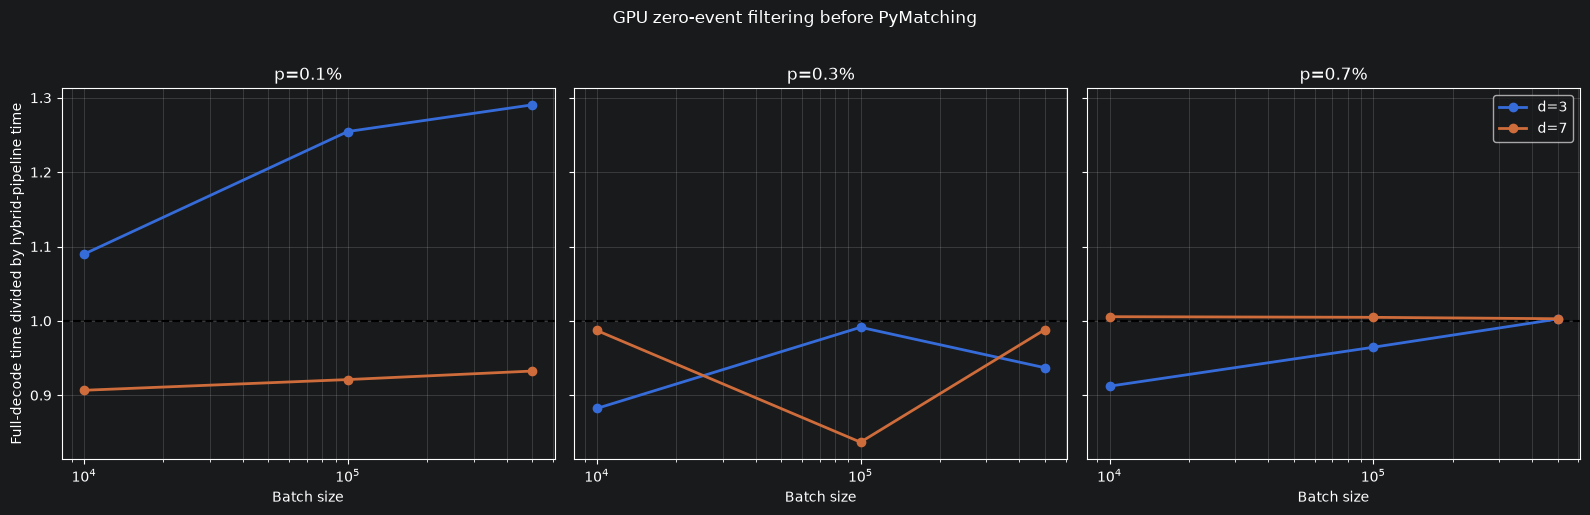

In [52]:
# Plot hybrid speedup
figure, axes = plt.subplots(
    1,
    len(HYBRID_NOISE_PROBABILITIES),
    figsize=(16, 5),
    sharey=True,
)

for axis, physical_probability in zip(
    axes,
    HYBRID_NOISE_PROBABILITIES,
):
    probability_subset = (
        hybrid_results_df[
            np.isclose(
                hybrid_results_df[
                    "physical_error_probability"
                ],
                physical_probability,
            )
        ]
    )

    axis.axhline(
        1.0,
        color="black",
        linestyle="--",
        linewidth=1.5,
    )

    for distance in (
        HYBRID_DISTANCES
    ):
        subset = probability_subset[
            probability_subset[
                "distance"
            ] == distance
        ].sort_values(
            "shots"
        )

        axis.plot(
            subset["shots"],
            subset[
                "hybrid_speedup"
            ],
            marker="o",
            linewidth=2,
            label=f"d={distance}",
        )

    axis.set_xscale("log")

    axis.set_xlabel(
        "Batch size"
    )

    axis.set_title(
        f"p={physical_probability:.1%}"
    )

    axis.grid(
        True,
        which="both",
        alpha=0.3,
    )

axes[0].set_ylabel(
    "Full-decode time divided by "
    "hybrid-pipeline time"
)

axes[-1].legend()

figure.suptitle(
    "GPU zero-event filtering before PyMatching",
    y=1.02,
)

figure.tight_layout()

hybrid_speedup_path = (
    FIGURE_DIR
    / "gpu_hybrid_filtering_speedup.png"
)

figure.savefig(
    hybrid_speedup_path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

## Hybrid-Filtering Interpretation

### Correctness and Exact Equivalence
GPU filtering reproduced the full PyMatching logical predictions identically across all tested configurations, confirming that bypassing empty-syndrome rows preserves exact decoder behaviour for the selected matching graphs.

Crucially, this optimisation distinguishes between **syndrome absence** and **physical error absence**. A zero-event detector row does not guarantee that no undetected logical error occurred—rather, the hybrid pipeline reproduces the decoder's deterministic all-zero logical prediction for an empty syndrome without claiming the underlying quantum state is error-free.

### Operating Regimes and Overhead Trade-Offs
* **Low Noise & Small Code Distance:** A high fraction of shots contain zero detection events, substantially reducing the number of rows dispatched to PyMatching and offsetting pipeline overhead.
* **High Noise & Large Code Distance:** Nonzero detection events occur far more frequently across larger space-time volumes. As the filterable fraction shrinks, host-to-device transfer and CPU Boolean indexing overheads dominate, reducing or eliminating any net speedup.

### Path to Higher Efficiency
Because the current prototype transfers a dense Boolean matrix from CPU RAM to the GPU only to return a 1D filtering mask, host–device round-trips limit end-to-end gains. In a production pipeline, emitting bit-packed detector frames directly from the upstream source, keeping them resident in GPU memory, and fusing zero-event filtering with downstream kernels would eliminate redundant PCIe transfers.


In [53]:
DISTANCES = [
    3,
    5,
    7,
    9,
    11,
]

BATCH_SIZES = [
    1_000,
    10_000,
    100_000,
    500_000,
]

PHYSICAL_ERROR_PROBABILITY = 0.003
BENCHMARK_REPEATS = 10

In [54]:
# Memory management
import gc

# Release unused CuPy memory-pool allocations
def release_gpu_memory():

    cp.cuda.Stream.null.synchronize()

    cp.get_default_memory_pool().free_all_blocks()
    cp.get_default_pinned_memory_pool().free_all_blocks()

    gc.collect()

# Return currently available GPU memory in GiB
def available_gpu_memory_gib():

    free_bytes, _ = cp.cuda.runtime.memGetInfo()

    return free_bytes / 1024**3


print(
    "Free GPU memory:",
    f"{available_gpu_memory_gib():.2f} GiB",
)

Free GPU memory: 30.26 GiB


In [55]:
# checkpoint path
GPU_SWEEP_PATH = (
    RESULTS_DIR
    / "gpu_detector_preprocessing.csv"
)

print(
    f"Results will be checkpointed to: "
    f"{GPU_SWEEP_PATH}"
)

Results will be checkpointed to: C:\Users\Karthi\Qauntum\results\gpu_detector_preprocessing.csv


In [56]:
# Generate one Stim surface-code detector matrix and benchmark CPU/GPU detector-event counting
def benchmark_stim_detector_workload(
    distance,
    batch_size,
    physical_error_probability,
    seed,
):

    noise_model = CircuitNoiseModel.symmetric(
        physical_error_probability
    )

    circuit = create_rotated_surface_code_circuit(
        distance=distance,
        rounds=distance,
        noise_model=noise_model,
        memory_basis="x",
    )

    estimated_input_bytes = (
        batch_size
        * circuit.num_detectors
    )

    print(
        f"d={distance}, "
        f"shots={batch_size:,}, "
        f"detectors={circuit.num_detectors:,}, "
        f"estimated input="
        f"{estimated_input_bytes / 1024**2:.2f} MiB"
    )

    sampler = compile_detector_sampler(
        circuit,
        seed=seed,
    )

    samples = sample_detection_events(
        sampler,
        number_of_shots=batch_size,
    )

    detection_events = (
        samples.detection_events
    )

    mean_event_count = float(
        detection_events.sum(
            axis=1
        ).mean()
    )

    zero_event_fraction = float(
        cpu_zero_event_mask(
            detection_events
        ).mean()
    )

    timing = benchmark_event_counting(
        detection_events,
        repeats=BENCHMARK_REPEATS,
        warm_up_repeats=3,
    )

    packed_width = int(
        np.ceil(
            circuit.num_detectors / 8
        )
    )

    packed_bytes = (
        batch_size
        * packed_width
    )

    result = {
        "distance": distance,
        "rounds": distance,
        "physical_error_probability": (
            physical_error_probability
        ),
        "shots": batch_size,
        "qubits": circuit.num_qubits,
        "measurements": (
            circuit.num_measurements
        ),
        "detectors": (
            circuit.num_detectors
        ),
        "input_bytes": (
            detection_events.nbytes
        ),
        "input_mib": (
            detection_events.nbytes
            / 1024**2
        ),
        "packed_bytes": packed_bytes,
        "packed_mib": (
            packed_bytes
            / 1024**2
        ),
        "compression_ratio": (
            detection_events.nbytes
            / packed_bytes
        ),
        "mean_detection_events": (
            mean_event_count
        ),
        "zero_event_fraction": (
            zero_event_fraction
        ),
        "cpu_ms": (
            timing.cpu_seconds
            * 1_000
        ),
        "host_to_device_ms": (
            timing.host_to_device_seconds
            * 1_000
        ),
        "gpu_kernel_ms": (
            timing.gpu_kernel_seconds
            * 1_000
        ),
        "device_to_host_ms": (
            timing.device_to_host_seconds
            * 1_000
        ),
        "gpu_end_to_end_ms": (
            timing.gpu_end_to_end_seconds
            * 1_000
        ),
        "resident_speedup": (
            timing.resident_gpu_speedup
        ),
        "end_to_end_speedup": (
            timing.end_to_end_gpu_speedup
        ),
        "cpu_shots_per_second": (
            timing.cpu_shots_per_second
        ),
        "gpu_kernel_shots_per_second": (
            timing.gpu_kernel_shots_per_second
        ),
        "gpu_end_to_end_shots_per_second": (
            timing
            .gpu_end_to_end_shots_per_second
        ),
    }

    del samples
    del detection_events
    del sampler
    del circuit

    release_gpu_memory()

    return result

In [57]:
# test the function before running the sweep
test_result = benchmark_stim_detector_workload(
    distance=3,
    batch_size=1_000,
    physical_error_probability=(
        PHYSICAL_ERROR_PROBABILITY
    ),
    seed=SEED,
)

pd.Series(
    test_result
)

d=3, shots=1,000, detectors=24, estimated input=0.02 MiB


distance                           3.000000e+00
rounds                             3.000000e+00
physical_error_probability         3.000000e-03
shots                              1.000000e+03
qubits                             2.600000e+01
measurements                       3.300000e+01
detectors                          2.400000e+01
input_bytes                        2.400000e+04
input_mib                          2.288818e-02
packed_bytes                       3.000000e+03
packed_mib                         2.861023e-03
compression_ratio                  8.000000e+00
mean_detection_events              8.790000e-01
zero_event_fraction                6.130000e-01
cpu_ms                             1.485000e-02
host_to_device_ms                  2.959999e-02
gpu_kernel_ms                      1.909991e-02
device_to_host_ms                  9.800075e-03
gpu_end_to_end_ms                  8.269999e-02
resident_speedup                   7.774903e-01
end_to_end_speedup                 1.795

In [58]:
# Validation
assert test_result["distance"] == 3
assert test_result["shots"] == 1_000
assert test_result["detectors"] > 0
assert test_result["cpu_ms"] > 0.0
assert test_result["gpu_kernel_ms"] > 0.0
assert test_result["gpu_end_to_end_ms"] > 0.0

print(
    "Real Stim detector-workload test passed."
)

Real Stim detector-workload test passed.


## System-Scale and Architectural Implications

### Per-Patch Latency versus System-Scale Throughput

For an individual small surface-code patch, each syndrome-extraction round produces a relatively small detector record. Invoking a discrete GPU independently for every patch and every correction cycle is therefore unlikely to be efficient, because host-device transfer, kernel-launch, synchronisation, and scheduling overhead can dominate the limited computational payload.

The larger classical-processing challenge arises from continuous repetition and system-wide scale. Stabilizer measurements are generated every correction cycle across all active data, ancilla, routing, and magic-state patches. The approximate raw syndrome-generation rate is:

$$
R_{\mathrm{syndrome}} \approx N_{\mathrm{patches}} N_{\mathrm{checks/patch}} f_{\mathrm{cycle}} b_{\mathrm{check}},
$$

where $b_{\mathrm{check}}$ accounts for the representation of each measurement or detector value.

The actual transported bandwidth also depends on:

- the number of stabilizer checks per code patch;
- the number and type of active patches;
- the syndrome-extraction cycle frequency;
- measurement multiplexing;
- dense, sparse, or bit-packed representation;
- detector extraction close to the readout hardware;
- framing, timestamps, and protocol metadata;
- compression and buffering.

The system must satisfy both a throughput requirement and a latency requirement. Average processing capacity must keep pace with the syndrome stream, while decoder results needed for feed-forward must become available before the corresponding logical operation consumes them.

### Interpreting Large-Batch GPU Benchmarks

The large-batch benchmarks in this notebook are most representative of:

- offline Monte Carlo simulation;
- simultaneous preprocessing for many independent code patches;
- aggregation across several syndrome windows;
- calibration and detector-workload analysis;
- architectures in which detector data is already resident on, or streamed efficiently to, an accelerator.

They should not be interpreted as evidence that a discrete GPU is optimal for the lowest-latency, single-patch real-time decoding path.

Temporal batching also introduces waiting latency. It may improve throughput when results can be delayed, but it may be unsuitable before adaptive logical measurements, lattice-surgery feed-forward, or other operations requiring a timely decoder decision.

The implemented surface-code pipeline remains heterogeneous:

```text
Stim sampling on the CPU
        ↓
CuPy detector preprocessing on the GPU
        ↓
PyMatching decoding on the CPU
```


In [59]:
# Load any previous checkpoint
if GPU_SWEEP_PATH.exists():
    existing_gpu_results_df = pd.read_csv(
        GPU_SWEEP_PATH
    )

    gpu_sweep_results = (
        existing_gpu_results_df.to_dict(
            orient="records"
        )
    )

    completed_configurations = {
        (
            int(row["distance"]),
            int(row["shots"]),
        )
        for row in gpu_sweep_results
    }

    print(
        f"Loaded {len(completed_configurations)} "
        "completed configurations."
    )
else:
    gpu_sweep_results = []
    completed_configurations = set()

    print(
        "No existing checkpoint found. "
        "Starting a new sweep."
    )

Loaded 20 completed configurations.


In [60]:
# Run dense Stim sweep
from time import perf_counter


configuration_index = 0

total_configurations = (
    len(DISTANCES)
    * len(BATCH_SIZES)
)

for distance in DISTANCES:
    for batch_size in BATCH_SIZES:
        configuration_index += 1

        configuration_key = (
            int(distance),
            int(batch_size),
        )

        if (
            configuration_key
            in completed_configurations
        ):
            print(
                f"Skipping completed "
                f"{configuration_index}/"
                f"{total_configurations}: "
                f"d={distance}, "
                f"shots={batch_size:,}"
            )

            continue

        print()
        print(
            f"Running "
            f"{configuration_index}/"
            f"{total_configurations}: "
            f"d={distance}, "
            f"shots={batch_size:,}"
        )

        configuration_start = perf_counter()

        result = (
            benchmark_stim_detector_workload(
                distance=distance,
                batch_size=batch_size,
                physical_error_probability=(
                    PHYSICAL_ERROR_PROBABILITY
                ),
                seed=(
                    SEED
                    + configuration_index
                ),
            )
        )

        configuration_seconds = (
            perf_counter()
            - configuration_start
        )

        result[
            "configuration_seconds"
        ] = configuration_seconds

        gpu_sweep_results.append(
            result
        )

        completed_configurations.add(
            configuration_key
        )

        checkpoint_df = pd.DataFrame(
            gpu_sweep_results
        ).sort_values(
            [
                "distance",
                "shots",
            ]
        ).reset_index(
            drop=True
        )

        checkpoint_df.to_csv(
            GPU_SWEEP_PATH,
            index=False,
        )

        print(
            f"  CPU: "
            f"{result['cpu_ms']:.4f} ms"
        )

        print(
            f"  GPU kernel: "
            f"{result['gpu_kernel_ms']:.4f} ms"
        )

        print(
            f"  GPU end-to-end: "
            f"{result['gpu_end_to_end_ms']:.4f} ms"
        )

        print(
            f"  Resident speedup: "
            f"{result['resident_speedup']:.3f}x"
        )

        print(
            f"  End-to-end speedup: "
            f"{result['end_to_end_speedup']:.3f}x"
        )

        print(
            f"  Configuration runtime: "
            f"{configuration_seconds:.2f} seconds"
        )

        print(
            f"  Free GPU memory: "
            f"{available_gpu_memory_gib():.2f} GiB"
        )

Skipping completed 1/20: d=3, shots=1,000
Skipping completed 2/20: d=3, shots=10,000
Skipping completed 3/20: d=3, shots=100,000
Skipping completed 4/20: d=3, shots=500,000
Skipping completed 5/20: d=5, shots=1,000
Skipping completed 6/20: d=5, shots=10,000
Skipping completed 7/20: d=5, shots=100,000
Skipping completed 8/20: d=5, shots=500,000
Skipping completed 9/20: d=7, shots=1,000
Skipping completed 10/20: d=7, shots=10,000
Skipping completed 11/20: d=7, shots=100,000
Skipping completed 12/20: d=7, shots=500,000
Skipping completed 13/20: d=9, shots=1,000
Skipping completed 14/20: d=9, shots=10,000
Skipping completed 15/20: d=9, shots=100,000
Skipping completed 16/20: d=9, shots=500,000
Skipping completed 17/20: d=11, shots=1,000
Skipping completed 18/20: d=11, shots=10,000
Skipping completed 19/20: d=11, shots=100,000
Skipping completed 20/20: d=11, shots=500,000


In [61]:
# load and examine the results
gpu_preprocessing_df = pd.read_csv(
    GPU_SWEEP_PATH
).sort_values(
    [
        "distance",
        "shots",
    ]
).reset_index(
    drop=True
)

display_columns = [
    "distance",
    "shots",
    "detectors",
    "input_mib",
    "mean_detection_events",
    "zero_event_fraction",
    "cpu_ms",
    "gpu_kernel_ms",
    "gpu_end_to_end_ms",
    "resident_speedup",
    "end_to_end_speedup",
]

if (
    "configuration_seconds"
    in gpu_preprocessing_df.columns
):
    display_columns.append(
        "configuration_seconds"
    )
else:
    print(
        "Note: configuration_seconds is absent from the existing checkpoint because those configurations were recorded before wall-clock timing was added."
    )

gpu_preprocessing_df[
    display_columns
]

Note: configuration_seconds is absent from the existing checkpoint because those configurations were recorded before wall-clock timing was added.


,distance,shots,detectors,input_mib,mean_detection_events,zero_event_fraction,cpu_ms,gpu_kernel_ms,gpu_end_to_end_ms,resident_speedup,end_to_end_speedup
0,3,1000,24,0.022888,0.811000,0.627000,0.01560,0.02040,0.06045,0.764707,0.258064
1,3,10000,24,0.228882,0.897100,0.595300,0.14140,0.01725,0.09485,8.197124,1.490775
2,3,100000,24,2.288818,0.887600,0.601600,1.38275,0.02580,0.28990,53.594916,4.769748
3,3,500000,24,11.444092,0.890768,0.598674,7.44750,0.06955,1.53130,107.081228,4.863515
4,5,1000,120,0.114441,5.173000,0.086000,0.05190,0.01630,0.08585,3.184050,0.604544
5,5,10000,120,1.144409,5.212700,0.074900,0.52655,0.01975,0.14490,26.660713,3.633887
6,5,100000,120,11.444092,5.246700,0.075090,8.88650,0.11005,0.92785,80.749685,9.577518
7,5,500000,120,57.220459,5.229624,0.075692,25.34015,0.31270,7.85795,81.036618,3.224779
8,7,1000,336,0.320435,15.722000,0.001000,0.24070,0.01320,0.12350,18.234792,1.948988
9,7,10000,336,3.204346,15.738400,0.000500,2.41990,0.02370,0.26930,102.105712,8.985889


In [62]:
# Check columns
print(
    gpu_preprocessing_df.columns.tolist()
)

['distance', 'rounds', 'physical_error_probability', 'shots', 'qubits', 'measurements', 'detectors', 'input_bytes', 'input_mib', 'packed_bytes', 'packed_mib', 'packing_compression_ratio', 'mean_detection_events', 'zero_event_fraction', 'cpu_ms', 'host_to_device_ms', 'gpu_kernel_ms', 'device_to_host_ms', 'gpu_end_to_end_ms', 'resident_speedup', 'end_to_end_speedup', 'cpu_shots_per_second', 'gpu_kernel_shots_per_second', 'gpu_end_to_end_shots_per_second']


In [63]:
# Validation
expected_configuration_count = (
    len(DISTANCES)
    * len(BATCH_SIZES)
)

completed_configuration_count = len(
    gpu_preprocessing_df
)

print(
    f"Completed configurations: "
    f"{completed_configuration_count} / "
    f"{expected_configuration_count}"
)

assert (
    completed_configuration_count
    == expected_configuration_count
)

required_positive_columns = [
    "cpu_ms",
    "gpu_kernel_ms",
    "gpu_end_to_end_ms",
    "resident_speedup",
    "end_to_end_speedup",
]

for column_name in required_positive_columns:
    assert (
        gpu_preprocessing_df[
            column_name
        ] > 0.0
    ).all(), (
        f"{column_name} contains a "
        "non-positive value."
    )

print(
    "Dense real-Stim GPU sweep completed "
    "and validated."
)

Completed configurations: 20 / 20
Dense real-Stim GPU sweep completed and validated.


In [64]:
# blank runtime column
if (
    "configuration_seconds"
    not in gpu_preprocessing_df.columns
):
    gpu_preprocessing_df[
        "configuration_seconds"
    ] = np.nan

gpu_preprocessing_df.to_csv(
    GPU_SWEEP_PATH,
    index=False,
)

In [65]:
# calculate crossover results
crossover_results = []

for distance in DISTANCES:
    subset = gpu_preprocessing_df[
        gpu_preprocessing_df[
            "distance"
        ] == distance
    ].sort_values(
        "shots"
    )

    gpu_wins = subset[
        subset[
            "end_to_end_speedup"
        ] > 1.0
    ]

    if gpu_wins.empty:
        first_gpu_win_batch = np.nan
        speedup_at_first_win = np.nan
    else:
        first_gpu_win = gpu_wins.iloc[0]

        first_gpu_win_batch = int(
            first_gpu_win["shots"]
        )

        speedup_at_first_win = float(
            first_gpu_win[
                "end_to_end_speedup"
            ]
        )

    crossover_results.append(
        {
            "distance": int(
                distance
            ),
            "detectors": int(
                subset[
                    "detectors"
                ].iloc[0]
            ),
            "first_tested_gpu_faster_batch": (
                first_gpu_win_batch
            ),
            "speedup_at_first_gpu_win": (
                speedup_at_first_win
            ),
            "maximum_tested_speedup": float(
                subset[
                    "end_to_end_speedup"
                ].max()
            ),
        }
    )

gpu_crossover_df = pd.DataFrame(
    crossover_results
)

gpu_crossover_df

,distance,detectors,first_tested_gpu_faster_batch,speedup_at_first_gpu_win,maximum_tested_speedup
0,3,24,10000,1.490775,4.863515
1,5,120,10000,3.633887,9.577518
2,7,336,1000,1.948988,8.985889
3,9,720,1000,2.253816,7.347982
4,11,1320,1000,3.370356,7.112911


In [66]:
# Save
GPU_CROSSOVER_PATH = (
    RESULTS_DIR
    / "gpu_preprocessing_crossover.csv"
)

gpu_crossover_df.to_csv(
    GPU_CROSSOVER_PATH,
    index=False,
)

print(
    f"Saved crossover results to: "
    f"{GPU_CROSSOVER_PATH}"
)

gpu_crossover_df

Saved crossover results to: C:\Users\Karthi\Qauntum\results\gpu_preprocessing_crossover.csv


,distance,detectors,first_tested_gpu_faster_batch,speedup_at_first_gpu_win,maximum_tested_speedup
0,3,24,10000,1.490775,4.863515
1,5,120,10000,3.633887,9.577518
2,7,336,1000,1.948988,8.985889
3,9,720,1000,2.253816,7.347982
4,11,1320,1000,3.370356,7.112911


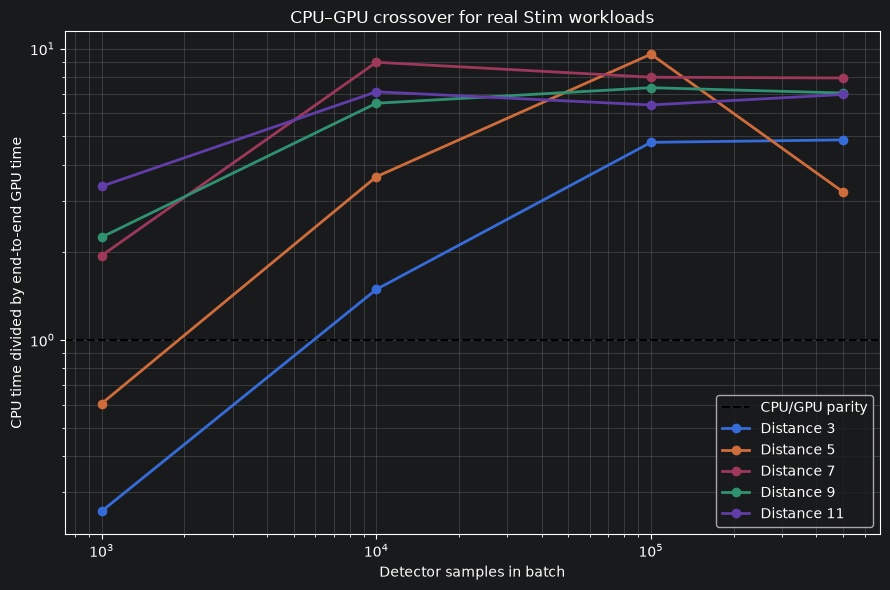

Saved figure to: C:\Users\Karthi\Qauntum\figures\gpu_event_count_crossover.png


In [67]:
# Plot end-to-end CPU–GPU crossover
figure, axis = plt.subplots(
    figsize=(9, 6)
)

axis.axhline(
    1.0,
    color="black",
    linestyle="--",
    linewidth=1.5,
    label="CPU/GPU parity",
)

for distance in DISTANCES:
    subset = gpu_preprocessing_df[
        gpu_preprocessing_df[
            "distance"
        ] == distance
    ].sort_values(
        "shots"
    )

    axis.plot(
        subset["shots"],
        subset[
            "end_to_end_speedup"
        ],
        marker="o",
        linewidth=2,
        label=f"Distance {distance}",
    )

axis.set_xscale("log")
axis.set_yscale("log")

axis.set_xlabel(
    "Detector samples in batch"
)

axis.set_ylabel(
    "CPU time divided by "
    "end-to-end GPU time"
)

axis.set_title(
    "CPU–GPU crossover for real Stim workloads"
)

axis.grid(
    True,
    which="both",
    alpha=0.3,
)

axis.legend()

figure.tight_layout()

GPU_CROSSOVER_FIGURE_PATH = (
    FIGURE_DIR
    / "gpu_event_count_crossover.png"
)

figure.savefig(
    GPU_CROSSOVER_FIGURE_PATH,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

print(
    f"Saved figure to: "
    f"{GPU_CROSSOVER_FIGURE_PATH}"
)

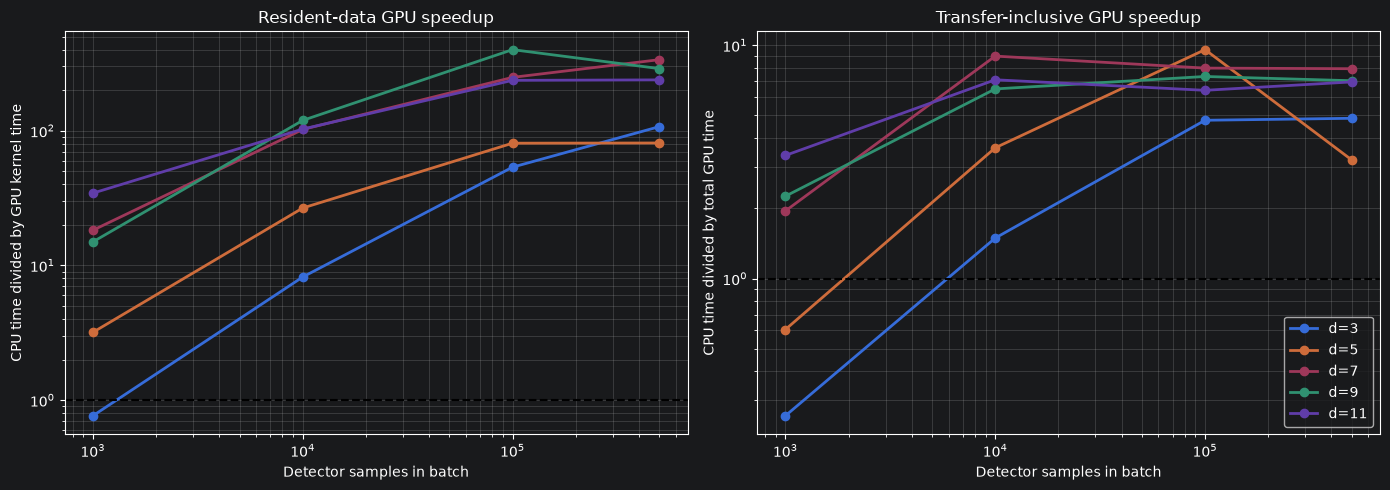

Saved figure to: C:\Users\Karthi\Qauntum\figures\gpu_speedup_by_distance.png


In [68]:
# Plot resident and end-to-end speedup separately
# resident speedup represents data already stored on the GPU
# end-to-end speedup includes transfer from the CPU-hosted Stim array
figure, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5),
)

for distance in DISTANCES:
    subset = gpu_preprocessing_df[
        gpu_preprocessing_df[
            "distance"
        ] == distance
    ].sort_values(
        "shots"
    )

    axes[0].plot(
        subset["shots"],
        subset[
            "resident_speedup"
        ],
        marker="o",
        linewidth=2,
        label=f"d={distance}",
    )

    axes[1].plot(
        subset["shots"],
        subset[
            "end_to_end_speedup"
        ],
        marker="o",
        linewidth=2,
        label=f"d={distance}",
    )

axes[0].axhline(
    1.0,
    color="black",
    linestyle="--",
    linewidth=1.5,
)

axes[0].set_xscale("log")
axes[0].set_yscale("log")

axes[0].set_xlabel(
    "Detector samples in batch"
)

axes[0].set_ylabel(
    "CPU time divided by GPU kernel time"
)

axes[0].set_title(
    "Resident-data GPU speedup"
)

axes[0].grid(
    True,
    which="both",
    alpha=0.3,
)

axes[1].axhline(
    1.0,
    color="black",
    linestyle="--",
    linewidth=1.5,
)

axes[1].set_xscale("log")
axes[1].set_yscale("log")

axes[1].set_xlabel(
    "Detector samples in batch"
)

axes[1].set_ylabel(
    "CPU time divided by total GPU time"
)

axes[1].set_title(
    "Transfer-inclusive GPU speedup"
)

axes[1].grid(
    True,
    which="both",
    alpha=0.3,
)

axes[1].legend()

figure.tight_layout()

GPU_SPEEDUP_FIGURE_PATH = (
    FIGURE_DIR
    / "gpu_speedup_by_distance.png"
)

figure.savefig(
    GPU_SPEEDUP_FIGURE_PATH,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

print(
    f"Saved figure to: "
    f"{GPU_SPEEDUP_FIGURE_PATH}"
)

In [69]:
# Select the largest workload for each distance
largest_batch_rows = (
    gpu_preprocessing_df
    .sort_values(
        "shots"
    )
    .groupby(
        "distance",
        as_index=False,
    )
    .tail(1)
    .sort_values(
        "distance"
    )
    .reset_index(
        drop=True
    )
)

largest_batch_rows[
    [
        "distance",
        "shots",
        "detectors",
        "input_mib",
        "cpu_ms",
        "host_to_device_ms",
        "gpu_kernel_ms",
        "device_to_host_ms",
        "gpu_end_to_end_ms",
        "end_to_end_speedup",
    ]
]

,distance,shots,detectors,input_mib,cpu_ms,host_to_device_ms,gpu_kernel_ms,device_to_host_ms,gpu_end_to_end_ms,end_to_end_speedup
0,3,500000,24,11.444092,7.44750,0.58590,0.06955,0.55235,1.53130,4.863515
1,5,500000,120,57.220459,25.34015,3.18970,0.31270,0.97710,7.85795,3.224779
2,7,500000,336,160.217285,81.96560,9.48195,0.24350,0.70980,10.33010,7.934638
3,9,500000,720,343.322754,149.90905,20.50720,0.51860,0.69125,21.27625,7.045840
4,11,500000,1320,629.425049,257.33020,35.09365,1.07965,0.63965,36.95325,6.963669


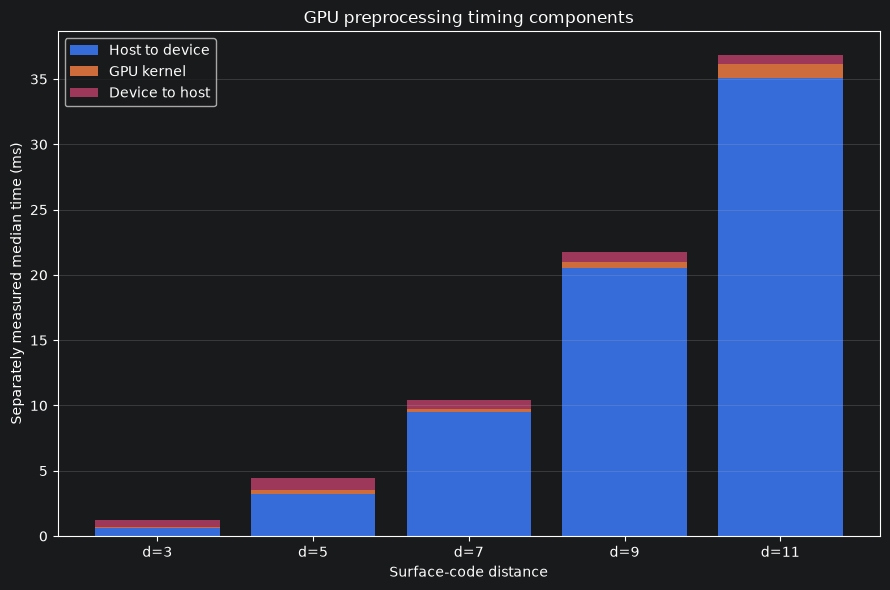

Saved figure to: C:\Users\Karthi\Qauntum\figures\gpu_transfer_breakdown.png


In [70]:
# Plot the measured GPU timing components
figure, axis = plt.subplots(
    figsize=(9, 6)
)

x_positions = np.arange(
    len(largest_batch_rows)
)

host_to_device = (
    largest_batch_rows[
        "host_to_device_ms"
    ].to_numpy()
)

gpu_kernel = (
    largest_batch_rows[
        "gpu_kernel_ms"
    ].to_numpy()
)

device_to_host = (
    largest_batch_rows[
        "device_to_host_ms"
    ].to_numpy()
)

axis.bar(
    x_positions,
    host_to_device,
    label="Host to device",
)

axis.bar(
    x_positions,
    gpu_kernel,
    bottom=host_to_device,
    label="GPU kernel",
)

axis.bar(
    x_positions,
    device_to_host,
    bottom=(
        host_to_device
        + gpu_kernel
    ),
    label="Device to host",
)

axis.set_xticks(
    x_positions
)

axis.set_xticklabels(
    [
        f"d={distance}"
        for distance in (
            largest_batch_rows[
                "distance"
            ]
        )
    ]
)

axis.set_xlabel(
    "Surface-code distance"
)

axis.set_ylabel(
    "Separately measured median time (ms)"
)

axis.set_title(
    "GPU preprocessing timing components"
)

axis.grid(
    axis="y",
    alpha=0.3,
)

axis.legend()

figure.tight_layout()

GPU_BREAKDOWN_FIGURE_PATH = (
    FIGURE_DIR
    / "gpu_transfer_breakdown.png"
)

figure.savefig(
    GPU_BREAKDOWN_FIGURE_PATH,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

print(
    f"Saved figure to: "
    f"{GPU_BREAKDOWN_FIGURE_PATH}"
)

The host-to-device, GPU-kernel and device-to-host values were measured independently. Their median values are therefore not expected to sum exactly to the independently measured end-to-end median.

In [71]:
# numerical summary
best_end_to_end_row = (
    gpu_preprocessing_df.loc[
        gpu_preprocessing_df[
            "end_to_end_speedup"
        ].idxmax()
    ]
)

best_resident_row = (
    gpu_preprocessing_df.loc[
        gpu_preprocessing_df[
            "resident_speedup"
        ].idxmax()
    ]
)

summary_results = {
    "configurations": len(
        gpu_preprocessing_df
    ),
    "minimum_batch_size": int(
        gpu_preprocessing_df[
            "shots"
        ].min()
    ),
    "maximum_batch_size": int(
        gpu_preprocessing_df[
            "shots"
        ].max()
    ),
    "maximum_detector_count": int(
        gpu_preprocessing_df[
            "detectors"
        ].max()
    ),
    "best_end_to_end_speedup": float(
        best_end_to_end_row[
            "end_to_end_speedup"
        ]
    ),
    "best_end_to_end_distance": int(
        best_end_to_end_row[
            "distance"
        ]
    ),
    "best_end_to_end_batch": int(
        best_end_to_end_row[
            "shots"
        ]
    ),
    "best_resident_speedup": float(
        best_resident_row[
            "resident_speedup"
        ]
    ),
    "best_resident_distance": int(
        best_resident_row[
            "distance"
        ]
    ),
    "best_resident_batch": int(
        best_resident_row[
            "shots"
        ]
    ),
}

pd.Series(
    summary_results
)

configurations                  20.000000
minimum_batch_size            1000.000000
maximum_batch_size          500000.000000
maximum_detector_count        1320.000000
best_end_to_end_speedup          9.577518
best_end_to_end_distance         5.000000
best_end_to_end_batch       100000.000000
best_resident_speedup          399.728297
best_resident_distance           9.000000
best_resident_batch         100000.000000
dtype: float64

In [72]:
# where the GPU was actually faster
gpu_faster_df = (
    gpu_preprocessing_df[
        gpu_preprocessing_df[
            "end_to_end_speedup"
        ] > 1.0
    ][
        [
            "distance",
            "shots",
            "detectors",
            "input_mib",
            "cpu_ms",
            "gpu_end_to_end_ms",
            "end_to_end_speedup",
        ]
    ]
    .sort_values(
        [
            "distance",
            "shots",
        ]
    )
)

print(
    f"GPU-faster configurations: "
    f"{len(gpu_faster_df)} / "
    f"{len(gpu_preprocessing_df)}"
)

gpu_faster_df

GPU-faster configurations: 18 / 20


,distance,shots,detectors,input_mib,cpu_ms,gpu_end_to_end_ms,end_to_end_speedup
1,3,10000,24,0.228882,0.14140,0.09485,1.490775
2,3,100000,24,2.288818,1.38275,0.28990,4.769748
3,3,500000,24,11.444092,7.44750,1.53130,4.863515
5,5,10000,120,1.144409,0.52655,0.14490,3.633887
6,5,100000,120,11.444092,8.88650,0.92785,9.577518
7,5,500000,120,57.220459,25.34015,7.85795,3.224779
8,7,1000,336,0.320435,0.24070,0.12350,1.948988
9,7,10000,336,3.204346,2.41990,0.26930,8.985889
10,7,100000,336,32.043457,15.01780,1.88130,7.982672
11,7,500000,336,160.217285,81.96560,10.33010,7.934638


## Dense Detector-Preprocessing Results

### Resident Compute vs. Host-to-Device Overhead
Once the detector matrix resided in GPU memory, the custom GPU kernel substantially outperformed NumPy event counting. However, end-to-end speedup was moderated by the PCIe overhead of transferring the dense Boolean detector matrix from host RAM to the device.

### Batch-Size and Code-Distance Scaling
The empirical CPU–GPU crossover point depended on both batch size and detector count:
* **Small Workloads:** Compact batches and low code distances offered insufficient parallel work to amortise host-to-device transfer and kernel-launch overhead.
* **Large Workloads:** Larger shot batches and higher surface-code distances increased arithmetic density, making GPU execution increasingly competitive against the CPU baseline.

### Architectural Context
* **Resident vs. End-to-End Regimes:** Resident-data benchmarks reflect an architecture where syndrome data already resides in GPU memory or is reused across multiple fused operations, whereas end-to-end measurements capture the current Stim workflow in which samples originate in host CPU memory.
* **Live System vs. Batched Workloads:** In a real-time quantum error-correction system, an individual surface-code patch generates a far smaller syndrome packet per cycle than the large matrices evaluated here. Consequently, these large-batch results apply primarily to **offline Monte Carlo simulation**, **simultaneous multi-patch processing**, or **temporal aggregation across multiple syndrome windows**.


## Bit-Packed Detector Transfers

Stim returns a dense Boolean detector matrix in host memory. Although each detector outcome carries only $1\text{ bit}$ of information, a standard NumPy Boolean element occupies $1\text{ byte}$.

Packing eight detector values into each byte compresses the transfer payload to roughly one-eighth of its original size:

$$
B_{\mathrm{packed}} = N_{\mathrm{shots}} \left\lceil \frac{N_{\mathrm{detectors}}}{8} \right\rceil.
$$

However, a smaller payload does not yield a free speedup, as the complete packed pipeline introduces additional processing stages:

1. **CPU Bit Packing:** Compressing the dense Boolean matrix into byte-aligned bitfields on the host;
2. **Packed H2D Transfer:** Copying the $B_{\mathrm{packed}}$ payload across PCIe to GPU memory;
3. **GPU Population Counting:** Computing per-shot detection-event counts directly from packed words (`popcount`);
4. **D2H Result Transfer:** Returning the resulting event counts to host memory.

To provide a fair assessment, the benchmark reports both the isolated packed transfer time and the complete end-to-end execution time.



In [73]:
# Population-count lookup table
# lets the GPU count active bits in packed bytes without unpacking the full Boolean matrix
from time import perf_counter


POPCOUNT_LOOKUP_CPU = np.array(
    [
        int(value).bit_count()
        for value in range(256)
    ],
    dtype=np.uint8,
)

POPCOUNT_LOOKUP_GPU = cp.asarray(
    POPCOUNT_LOOKUP_CPU
)

# Count event bits in a packed CuPy uint8 matrix
def gpu_counts_from_packed_bytes(
    packed_events,
):


    if not isinstance(
        packed_events,
        cp.ndarray,
    ):
        raise TypeError(
            "packed_events must be a CuPy array"
        )

    if packed_events.ndim != 2:
        raise ValueError(
            "packed_events must be two-dimensional"
        )

    if packed_events.dtype != cp.uint8:
        raise TypeError(
            "packed_events must have dtype uint8"
        )

    byte_event_counts = (
        POPCOUNT_LOOKUP_GPU[
            packed_events
        ]
    )

    return byte_event_counts.sum(
        axis=1,
        dtype=cp.int64,
    )

In [74]:
# validate packed counting
validation_packed_cpu = (
    cpu_pack_detector_bits(
        validation_events
    )
)

validation_packed_gpu = cp.asarray(
    validation_packed_cpu
)

validation_packed_counts_gpu = (
    gpu_counts_from_packed_bytes(
        validation_packed_gpu
    )
)

validation_packed_counts_cpu = cp.asnumpy(
    validation_packed_counts_gpu
)

cp.cuda.Stream.null.synchronize()

assert np.array_equal(
    validation_packed_counts_cpu,
    cpu_counts,
)

dense_validation_bytes = (
    validation_events.nbytes
)

packed_validation_bytes = (
    validation_packed_cpu.nbytes
)

print(
    "Packed GPU event counts match "
    "dense CPU event counts"
)

print(
    f"Dense size: "
    f"{dense_validation_bytes / 1024**2:.4f} MiB"
)

print(
    f"Packed size: "
    f"{packed_validation_bytes / 1024**2:.4f} MiB"
)

print(
    f"Compression ratio: "
    f"{dense_validation_bytes / packed_validation_bytes:.3f}x"
)

Packed GPU event counts match dense CPU event counts
Dense size: 2.4509 MiB
Packed size: 0.3147 MiB
Compression ratio: 7.788x


In [75]:
# timing helper
# Return the median wall-clock time
def median_seconds(
    operation,
    repeats=10,
):

    if repeats <= 0:
        raise ValueError(
            "repeats must be positive"
        )

    elapsed_seconds = []

    for _ in range(repeats):
        start_time = perf_counter()

        operation()

        end_time = perf_counter()

        elapsed_seconds.append(
            end_time - start_time
        )

    return float(
        np.median(
            elapsed_seconds
        )
    )

In [76]:
# Packed-pipeline benchmark function
# Compare dense GPU counting with a packed GPU pipeline.
#
# Packed end-to-end timing includes CPU packing, packed transfer, GPU population counting and result transfer
def benchmark_packed_event_counting(
    detection_events,
    repeats=10,
    warm_up_repeats=3,
):

    events = np.asarray(
        detection_events,
        dtype=np.bool_,
    )

    if events.ndim != 2:
        raise ValueError(
            "detection_events must be two-dimensional."
        )

    shots, detectors = events.shape

    # CPU packing warm-up.
    for _ in range(warm_up_repeats):
        np.packbits(
            events,
            axis=1,
            bitorder="little",
        )

    cpu_pack_seconds = median_seconds(
        lambda: np.packbits(
            events,
            axis=1,
            bitorder="little",
        ),
        repeats=repeats,
    )

    packed_cpu = np.packbits(
        events,
        axis=1,
        bitorder="little",
    )

    packed_gpu = cp.asarray(
        packed_cpu
    )

    # Warm up the GPU lookup and reduction.
    for _ in range(warm_up_repeats):
        gpu_counts_from_packed_bytes(
            packed_gpu
        )

        cp.cuda.Stream.null.synchronize()

    def packed_transfer_operation():
        temporary_gpu_array = cp.asarray(
            packed_cpu
        )

        cp.cuda.Stream.null.synchronize()

        del temporary_gpu_array

    packed_h2d_seconds = median_seconds(
        packed_transfer_operation,
        repeats=repeats,
    )

    def packed_kernel_operation():
        gpu_counts_from_packed_bytes(
            packed_gpu
        )

        cp.cuda.Stream.null.synchronize()

    packed_kernel_seconds = median_seconds(
        packed_kernel_operation,
        repeats=repeats,
    )

    packed_gpu_counts = (
        gpu_counts_from_packed_bytes(
            packed_gpu
        )
    )

    cp.cuda.Stream.null.synchronize()

    def packed_result_transfer():
        cp.asnumpy(
            packed_gpu_counts
        )

        cp.cuda.Stream.null.synchronize()

    packed_d2h_seconds = median_seconds(
        packed_result_transfer,
        repeats=repeats,
    )

    def packed_end_to_end_operation():
        local_packed_cpu = np.packbits(
            events,
            axis=1,
            bitorder="little",
        )

        local_packed_gpu = cp.asarray(
            local_packed_cpu
        )

        local_gpu_counts = (
            gpu_counts_from_packed_bytes(
                local_packed_gpu
            )
        )

        cp.asnumpy(
            local_gpu_counts
        )

        cp.cuda.Stream.null.synchronize()

    packed_end_to_end_seconds = (
        median_seconds(
            packed_end_to_end_operation,
            repeats=repeats,
        )
    )

    dense_timing = benchmark_event_counting(
        events,
        repeats=repeats,
        warm_up_repeats=warm_up_repeats,
    )

    result = {
        "shots": int(shots),
        "detectors": int(detectors),
        "dense_bytes": int(
            events.nbytes
        ),
        "packed_bytes": int(
            packed_cpu.nbytes
        ),
        "compression_ratio": float(
            events.nbytes
            / packed_cpu.nbytes
        ),
        "cpu_dense_count_ms": float(
            dense_timing.cpu_seconds
            * 1_000
        ),
        "cpu_pack_ms": float(
            cpu_pack_seconds
            * 1_000
        ),
        "dense_h2d_ms": float(
            dense_timing
            .host_to_device_seconds
            * 1_000
        ),
        "packed_h2d_ms": float(
            packed_h2d_seconds
            * 1_000
        ),
        "dense_gpu_kernel_ms": float(
            dense_timing
            .gpu_kernel_seconds
            * 1_000
        ),
        "packed_gpu_kernel_ms": float(
            packed_kernel_seconds
            * 1_000
        ),
        "packed_d2h_ms": float(
            packed_d2h_seconds
            * 1_000
        ),
        "dense_end_to_end_ms": float(
            dense_timing
            .gpu_end_to_end_seconds
            * 1_000
        ),
        "packed_end_to_end_ms": float(
            packed_end_to_end_seconds
            * 1_000
        ),
        "packed_transfer_speedup": float(
            dense_timing
            .host_to_device_seconds
            / packed_h2d_seconds
        ),
        "packed_vs_dense_speedup": float(
            dense_timing
            .gpu_end_to_end_seconds
            / packed_end_to_end_seconds
        ),
        "packed_vs_cpu_speedup": float(
            dense_timing.cpu_seconds
            / packed_end_to_end_seconds
        ),
    }

    del packed_gpu
    del packed_gpu_counts

    release_gpu_memory()

    return result

In [77]:
# smoke benchmark
packed_smoke_result = (
    benchmark_packed_event_counting(
        synthetic_events,
        repeats=10,
        warm_up_repeats=3,
    )
)

pd.Series(
    packed_smoke_result
)

shots                      1.000000e+05
detectors                  1.000000e+03
dense_bytes                1.000000e+08
packed_bytes               1.250000e+07
compression_ratio          8.000000e+00
cpu_dense_count_ms         4.402540e+01
cpu_pack_ms                6.401200e+00
dense_h2d_ms               5.599900e+00
packed_h2d_ms              7.477000e-01
dense_gpu_kernel_ms        8.380006e-02
packed_gpu_kernel_ms       1.236000e-01
packed_d2h_ms              7.959997e-02
dense_end_to_end_ms        6.170700e+00
packed_end_to_end_ms       7.457550e+00
packed_transfer_speedup    7.489501e+00
packed_vs_dense_speedup    8.274433e-01
packed_vs_cpu_speedup      5.903467e+00
dtype: float64

In [78]:
# Validation
assert (
    packed_smoke_result[
        "compression_ratio"
    ] > 7.0
)

assert (
    packed_smoke_result[
        "packed_h2d_ms"
    ] > 0.0
)

assert (
    packed_smoke_result[
        "packed_gpu_kernel_ms"
    ] > 0.0
)

assert (
    packed_smoke_result[
        "packed_end_to_end_ms"
    ] > 0.0
)

print(
    "Packed preprocessing smoke test passed."
)

Packed preprocessing smoke test passed.


In [79]:
# Save
PACKED_SMOKE_PATH = (
    RESULTS_DIR
    / "gpu_packed_smoke_benchmark.csv"
)

pd.DataFrame(
    [packed_smoke_result]
).to_csv(
    PACKED_SMOKE_PATH,
    index=False,
)

print(
    f"Saved packed smoke benchmark to: "
    f"{PACKED_SMOKE_PATH}"
)

Saved packed smoke benchmark to: C:\Users\Karthi\Qauntum\results\gpu_packed_smoke_benchmark.csv


In [80]:
# Packed checkpoint
PACKED_SWEEP_PATH = (
    RESULTS_DIR
    / "gpu_packed_detector_preprocessing.csv"
)

print(
    f"Packed results will be checkpointed to: "
    f"{PACKED_SWEEP_PATH}"
)

Packed results will be checkpointed to: C:\Users\Karthi\Qauntum\results\gpu_packed_detector_preprocessing.csv


In [81]:
# load completed packed configurations
if PACKED_SWEEP_PATH.exists():
    existing_packed_df = pd.read_csv(
        PACKED_SWEEP_PATH
    )

    packed_sweep_results = (
        existing_packed_df.to_dict(
            orient="records"
        )
    )

    completed_packed_configurations = {
        (
            int(row["distance"]),
            int(row["shots"]),
        )
        for row in packed_sweep_results
    }

    print(
        f"Loaded "
        f"{len(completed_packed_configurations)} "
        "completed packed configurations"
    )
else:
    packed_sweep_results = []
    completed_packed_configurations = set()

    print(
        "No packed checkpoint found Starting a new sweep"
    )

Loaded 20 completed packed configurations


In [82]:
# Run the packed real-Stim sweep
packed_configuration_index = 0

total_packed_configurations = (
    len(DISTANCES)
    * len(BATCH_SIZES)
)

for distance in DISTANCES:
    for batch_size in BATCH_SIZES:
        packed_configuration_index += 1

        configuration_key = (
            int(distance),
            int(batch_size),
        )

        if (
            configuration_key
            in completed_packed_configurations
        ):
            print(
                f"Skipping completed "
                f"{packed_configuration_index}/"
                f"{total_packed_configurations}: "
                f"d={distance}, "
                f"shots={batch_size:,}"
            )

            continue

        print()
        print(
            f"Running packed benchmark "
            f"{packed_configuration_index}/"
            f"{total_packed_configurations}: "
            f"d={distance}, "
            f"shots={batch_size:,}"
        )

        configuration_start = perf_counter()

        noise_model = (
            CircuitNoiseModel.symmetric(
                PHYSICAL_ERROR_PROBABILITY
            )
        )

        circuit = (
            create_rotated_surface_code_circuit(
                distance=distance,
                rounds=distance,
                noise_model=noise_model,
                memory_basis="x",
            )
        )

        sampler = compile_detector_sampler(
            circuit,
            seed=(
                SEED
                + 20_000
                + packed_configuration_index
            ),
        )

        samples = sample_detection_events(
            sampler,
            number_of_shots=batch_size,
        )

        detection_events = (
            samples.detection_events
        )

        benchmark_result = (
            benchmark_packed_event_counting(
                detection_events,
                repeats=BENCHMARK_REPEATS,
                warm_up_repeats=3,
            )
        )

        configuration_seconds = (
            perf_counter()
            - configuration_start
        )

        benchmark_result.update(
            {
                "distance": int(distance),
                "rounds": int(distance),
                "physical_error_probability": (
                    PHYSICAL_ERROR_PROBABILITY
                ),
                "qubits": int(
                    circuit.num_qubits
                ),
                "measurements": int(
                    circuit.num_measurements
                ),
                "mean_detection_events": float(
                    detection_events.sum(
                        axis=1
                    ).mean()
                ),
                "zero_event_fraction": float(
                    cpu_zero_event_mask(
                        detection_events
                    ).mean()
                ),
                "configuration_seconds": (
                    configuration_seconds
                ),
            }
        )

        packed_sweep_results.append(
            benchmark_result
        )

        completed_packed_configurations.add(
            configuration_key
        )

        packed_checkpoint_df = pd.DataFrame(
            packed_sweep_results
        ).sort_values(
            [
                "distance",
                "shots",
            ]
        ).reset_index(
            drop=True
        )

        packed_checkpoint_df.to_csv(
            PACKED_SWEEP_PATH,
            index=False,
        )

        print(
            f"  Compression: "
            f"{benchmark_result['compression_ratio']:.3f}x"
        )

        print(
            f"  CPU packing: "
            f"{benchmark_result['cpu_pack_ms']:.4f} ms"
        )

        print(
            f"  Dense H2D: "
            f"{benchmark_result['dense_h2d_ms']:.4f} ms"
        )

        print(
            f"  Packed H2D: "
            f"{benchmark_result['packed_h2d_ms']:.4f} ms"
        )

        print(
            f"  Dense total: "
            f"{benchmark_result['dense_end_to_end_ms']:.4f} ms"
        )

        print(
            f"  Packed total: "
            f"{benchmark_result['packed_end_to_end_ms']:.4f} ms"
        )

        print(
            f"  Packed/dense speedup: "
            f"{benchmark_result['packed_vs_dense_speedup']:.3f}x"
        )

        print(
            f"  Packed/CPU speedup: "
            f"{benchmark_result['packed_vs_cpu_speedup']:.3f}x"
        )

        print(
            f"  Configuration runtime: "
            f"{configuration_seconds:.2f} seconds"
        )

        del detection_events
        del samples
        del sampler
        del circuit

        release_gpu_memory()

Skipping completed 1/20: d=3, shots=1,000
Skipping completed 2/20: d=3, shots=10,000
Skipping completed 3/20: d=3, shots=100,000
Skipping completed 4/20: d=3, shots=500,000
Skipping completed 5/20: d=5, shots=1,000
Skipping completed 6/20: d=5, shots=10,000
Skipping completed 7/20: d=5, shots=100,000
Skipping completed 8/20: d=5, shots=500,000
Skipping completed 9/20: d=7, shots=1,000
Skipping completed 10/20: d=7, shots=10,000
Skipping completed 11/20: d=7, shots=100,000
Skipping completed 12/20: d=7, shots=500,000
Skipping completed 13/20: d=9, shots=1,000
Skipping completed 14/20: d=9, shots=10,000
Skipping completed 15/20: d=9, shots=100,000
Skipping completed 16/20: d=9, shots=500,000
Skipping completed 17/20: d=11, shots=1,000
Skipping completed 18/20: d=11, shots=10,000
Skipping completed 19/20: d=11, shots=100,000
Skipping completed 20/20: d=11, shots=500,000


In [83]:
print(
    packed_preprocessing_df.columns.tolist()
)

['shots', 'detectors', 'dense_bytes', 'packed_bytes', 'compression_ratio', 'cpu_dense_count_ms', 'cpu_pack_ms', 'dense_h2d_ms', 'packed_h2d_ms', 'dense_gpu_kernel_ms', 'packed_gpu_kernel_ms', 'packed_d2h_ms', 'dense_end_to_end_ms', 'packed_end_to_end_ms', 'packed_resident_ms', 'packed_vs_dense_transfer_speedup', 'packed_vs_dense_pipeline_speedup', 'packed_vs_cpu_speedup', 'distance', 'rounds', 'physical_error_probability', 'qubits', 'measurements', 'mean_detection_events', 'zero_event_fraction', 'packed_vs_dense_speedup', 'packed_transfer_speedup']


In [84]:
# load and validate the packed sweep
packed_preprocessing_df = pd.read_csv(
    PACKED_SWEEP_PATH
).sort_values(
    [
        "distance",
        "shots",
    ]
).reset_index(
    drop=True
)

column_aliases = {
    "packed_vs_dense_transfer_speedup": (
        "packed_transfer_speedup"
    ),
    "packed_vs_dense_pipeline_speedup": (
        "packed_vs_dense_speedup"
    ),
}

columns_to_rename = {
    old_name: new_name
    for old_name, new_name in (
        column_aliases.items()
    )
    if (
        old_name
        in packed_preprocessing_df.columns
        and new_name
        not in packed_preprocessing_df.columns
    )
}

packed_preprocessing_df = (
    packed_preprocessing_df.rename(
        columns=columns_to_rename
    )
)

print(
    "Renamed columns:",
    columns_to_rename,
)

print(
    "Current columns:",
    packed_preprocessing_df.columns.tolist(),
)

expected_packed_configurations = (
    len(DISTANCES)
    * len(BATCH_SIZES)
)

print(
    f"Completed packed configurations: "
    f"{len(packed_preprocessing_df)} / "
    f"{expected_packed_configurations}"
)

assert (
    len(packed_preprocessing_df)
    == expected_packed_configurations
)

required_packed_columns = [
    "compression_ratio",
    "cpu_pack_ms",
    "dense_h2d_ms",
    "packed_h2d_ms",
    "dense_end_to_end_ms",
    "packed_end_to_end_ms",
    "packed_transfer_speedup",
    "packed_vs_dense_speedup",
    "packed_vs_cpu_speedup",
]

for column_name in required_packed_columns:
    assert (
        packed_preprocessing_df[
            column_name
        ] > 0.0
    ).all(), (
        f"{column_name} contains a "
        "non-positive value."
    )

print(
    "Packed real-Stim sweep completed "
    "and validated."
)

Renamed columns: {'packed_vs_dense_transfer_speedup': 'packed_transfer_speedup', 'packed_vs_dense_pipeline_speedup': 'packed_vs_dense_speedup'}
Current columns: ['shots', 'detectors', 'dense_bytes', 'packed_bytes', 'compression_ratio', 'cpu_dense_count_ms', 'cpu_pack_ms', 'dense_h2d_ms', 'packed_h2d_ms', 'dense_gpu_kernel_ms', 'packed_gpu_kernel_ms', 'packed_d2h_ms', 'dense_end_to_end_ms', 'packed_end_to_end_ms', 'packed_resident_ms', 'packed_transfer_speedup', 'packed_vs_dense_speedup', 'packed_vs_cpu_speedup', 'distance', 'rounds', 'physical_error_probability', 'qubits', 'measurements', 'mean_detection_events', 'zero_event_fraction']
Completed packed configurations: 20 / 20
Packed real-Stim sweep completed and validated.


In [85]:
# Fixing missing columns
if (
    "packed_transfer_speedup"
    not in packed_preprocessing_df.columns
):
    packed_preprocessing_df[
        "packed_transfer_speedup"
    ] = (
        packed_preprocessing_df[
            "dense_h2d_ms"
        ]
        / packed_preprocessing_df[
            "packed_h2d_ms"
        ]
    )

if (
    "packed_vs_dense_speedup"
    not in packed_preprocessing_df.columns
):
    packed_preprocessing_df[
        "packed_vs_dense_speedup"
    ] = (
        packed_preprocessing_df[
            "dense_end_to_end_ms"
        ]
        / packed_preprocessing_df[
            "packed_end_to_end_ms"
        ]
    )

if (
    "packed_vs_cpu_speedup"
    not in packed_preprocessing_df.columns
):
    packed_preprocessing_df[
        "packed_vs_cpu_speedup"
    ] = (
        packed_preprocessing_df[
            "cpu_dense_count_ms"
        ]
        / packed_preprocessing_df[
            "packed_end_to_end_ms"
        ]
    )

print(
    "Packed speedup columns are available."
)


Packed speedup columns are available.


In [86]:
# Save normalised schema
packed_preprocessing_df = (
    packed_preprocessing_df.sort_values(
        [
            "distance",
            "shots",
        ]
    ).reset_index(
        drop=True
    )
)

packed_preprocessing_df.to_csv(
    PACKED_SWEEP_PATH,
    index=False,
)

print(
    f"Updated packed checkpoint: "
    f"{PACKED_SWEEP_PATH}"
)

Updated packed checkpoint: C:\Users\Karthi\Qauntum\results\gpu_packed_detector_preprocessing.csv


In [87]:
# Rerun the validation with a clearer schema check
expected_packed_configurations = (
    len(DISTANCES)
    * len(BATCH_SIZES)
)

print(
    f"Completed packed configurations: "
    f"{len(packed_preprocessing_df)} / "
    f"{expected_packed_configurations}"
)

assert (
    len(packed_preprocessing_df)
    == expected_packed_configurations
)

required_packed_columns = [
    "compression_ratio",
    "cpu_pack_ms",
    "dense_h2d_ms",
    "packed_h2d_ms",
    "dense_end_to_end_ms",
    "packed_end_to_end_ms",
    "packed_transfer_speedup",
    "packed_vs_dense_speedup",
    "packed_vs_cpu_speedup",
]

missing_packed_columns = [
    column_name
    for column_name in required_packed_columns
    if (
        column_name
        not in packed_preprocessing_df.columns
    )
]

assert not missing_packed_columns, (
    "Missing packed benchmark columns: "
    f"{missing_packed_columns}"
)

for column_name in required_packed_columns:
    assert (
        packed_preprocessing_df[
            column_name
        ].notna().all()
    ), (
        f"{column_name} contains missing values."
    )

    assert (
        packed_preprocessing_df[
            column_name
        ] > 0.0
    ).all(), (
        f"{column_name} contains a "
        "non-positive value."
    )

print(
    "Packed real-Stim sweep completed "
    "and validated."
)

Completed packed configurations: 20 / 20
Packed real-Stim sweep completed and validated.


In [88]:
# packed results inspection
packed_display_columns = [
    "distance",
    "shots",
    "detectors",
    "compression_ratio",
    "cpu_dense_count_ms",
    "cpu_pack_ms",
    "dense_h2d_ms",
    "packed_h2d_ms",
    "dense_end_to_end_ms",
    "packed_end_to_end_ms",
    "packed_transfer_speedup",
    "packed_vs_dense_speedup",
    "packed_vs_cpu_speedup",
]

packed_preprocessing_df[
    packed_display_columns
]

,distance,shots,detectors,compression_ratio,cpu_dense_count_ms,cpu_pack_ms,dense_h2d_ms,packed_h2d_ms,dense_end_to_end_ms,packed_end_to_end_ms,packed_transfer_speedup,packed_vs_dense_speedup,packed_vs_cpu_speedup
0,3,1000,24,8.0,0.01465,0.00910,0.02265,0.05645,0.09215,0.13710,0.401239,0.672137,0.106856
1,3,10000,24,8.0,0.13055,0.08410,0.04140,0.02970,0.08845,0.18135,1.393941,0.487731,0.719878
2,3,100000,24,8.0,1.30570,0.85430,0.13700,0.04595,0.26790,1.10180,2.981501,0.243148,1.185061
3,3,500000,24,8.0,7.06020,4.46890,0.52420,0.11325,1.34490,5.26575,4.628698,0.255405,1.340778
4,5,1000,120,8.0,0.05065,0.01250,0.04070,0.02965,0.08500,0.14430,1.372680,0.589051,0.351005
5,5,10000,120,8.0,0.49220,0.12065,0.10135,0.03820,0.15025,0.22290,2.653138,0.674069,2.208166
6,5,100000,120,8.0,4.99050,1.42730,0.56460,0.11450,0.75330,1.73395,4.931004,0.434442,2.878111
7,5,500000,120,8.0,26.10650,7.53570,2.73985,0.49110,3.65875,8.31650,5.579006,0.439939,3.139121
8,7,1000,336,8.0,0.14715,0.01250,0.04695,0.02800,0.09380,0.09345,1.676784,1.003746,1.574640
9,7,10000,336,8.0,1.43970,0.12020,0.23120,0.05940,0.25385,0.22950,3.892257,1.106100,6.273202


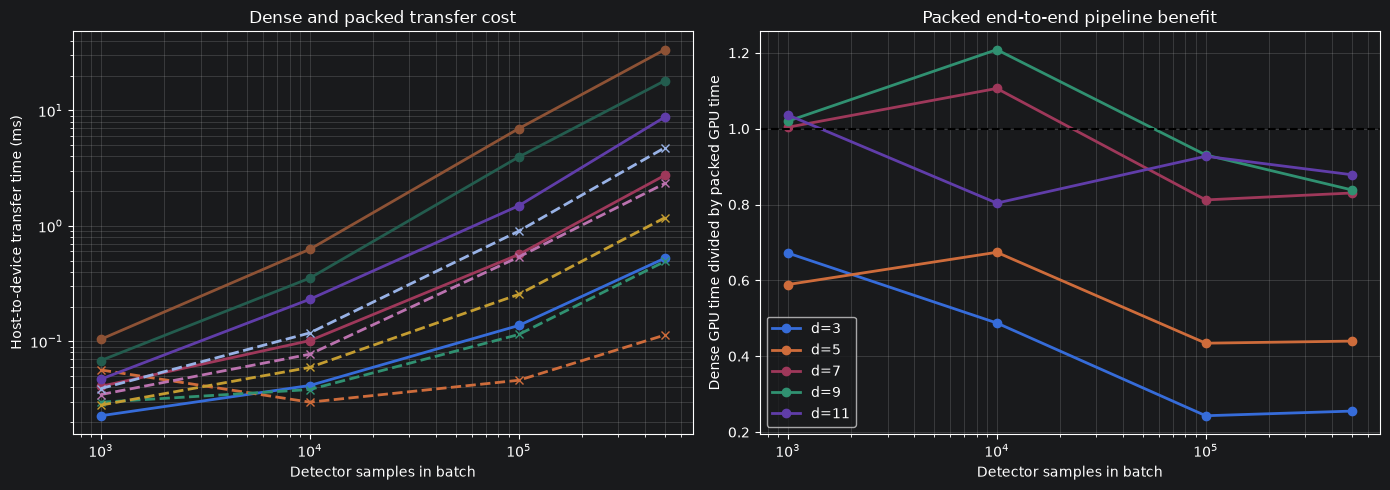

In [89]:
# packed-results plot
figure, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5),
)

for distance in DISTANCES:
    subset = packed_preprocessing_df[
        packed_preprocessing_df[
            "distance"
        ] == distance
    ].sort_values(
        "shots"
    )

    axes[0].plot(
        subset["shots"],
        subset["dense_h2d_ms"],
        marker="o",
        linewidth=2,
        label=f"Dense d={distance}",
    )

    axes[0].plot(
        subset["shots"],
        subset["packed_h2d_ms"],
        marker="x",
        linestyle="--",
        linewidth=2,
        label=f"Packed d={distance}",
    )

    axes[1].plot(
        subset["shots"],
        subset[
            "packed_vs_dense_speedup"
        ],
        marker="o",
        linewidth=2,
        label=f"d={distance}",
    )

axes[0].set_xscale("log")
axes[0].set_yscale("log")
axes[0].set_xlabel(
    "Detector samples in batch"
)
axes[0].set_ylabel(
    "Host-to-device transfer time (ms)"
)
axes[0].set_title(
    "Dense and packed transfer cost"
)
axes[0].grid(
    True,
    which="both",
    alpha=0.3,
)

axes[1].axhline(
    1.0,
    color="black",
    linestyle="--",
    linewidth=1.5,
)
axes[1].set_xscale("log")
axes[1].set_xlabel(
    "Detector samples in batch"
)
axes[1].set_ylabel(
    "Dense GPU time divided by "
    "packed GPU time"
)
axes[1].set_title(
    "Packed end-to-end pipeline benefit"
)
axes[1].grid(
    True,
    which="both",
    alpha=0.3,
)
axes[1].legend()

figure.tight_layout()

PACKED_TRANSFER_FIGURE_PATH = (
    FIGURE_DIR
    / "gpu_packed_transfer_comparison.png"
)

figure.savefig(
    PACKED_TRANSFER_FIGURE_PATH,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

In [90]:
# Summarise packed results
packed_pipeline_wins_df = (
    packed_preprocessing_df[
        packed_preprocessing_df[
            "packed_vs_dense_speedup"
        ] > 1.0
    ]
    .sort_values(
        [
            "distance",
            "shots",
        ]
    )
)

packed_cpu_wins_df = (
    packed_preprocessing_df[
        packed_preprocessing_df[
            "packed_vs_cpu_speedup"
        ] > 1.0
    ]
    .sort_values(
        [
            "distance",
            "shots",
        ]
    )
)

print(
    "Packed pipeline faster than dense GPU:",
    f"{len(packed_pipeline_wins_df)} / "
    f"{len(packed_preprocessing_df)}",
)

print(
    "Packed pipeline faster than CPU:",
    f"{len(packed_cpu_wins_df)} / "
    f"{len(packed_preprocessing_df)}",
)

packed_pipeline_wins_df[
    [
        "distance",
        "shots",
        "detectors",
        "compression_ratio",
        "cpu_pack_ms",
        "dense_h2d_ms",
        "packed_h2d_ms",
        "dense_end_to_end_ms",
        "packed_end_to_end_ms",
        "packed_vs_dense_speedup",
        "packed_vs_cpu_speedup",
    ]
]

Packed pipeline faster than dense GPU: 5 / 20
Packed pipeline faster than CPU: 17 / 20


,distance,shots,detectors,compression_ratio,cpu_pack_ms,dense_h2d_ms,packed_h2d_ms,dense_end_to_end_ms,packed_end_to_end_ms,packed_vs_dense_speedup,packed_vs_cpu_speedup
8,7,1000,336,8.0,0.01250,0.04695,0.02800,0.09380,0.09345,1.003746,1.574640
9,7,10000,336,8.0,0.12020,0.23120,0.05940,0.25385,0.22950,1.106100,6.273202
12,9,1000,720,8.0,0.02090,0.06810,0.03455,0.10600,0.10395,1.019721,2.726310
13,9,10000,720,8.0,0.20890,0.35230,0.07725,0.40365,0.33405,1.208352,8.643317
16,11,1000,1320,8.0,0.04175,0.10405,0.03895,0.13430,0.12960,1.036266,3.872301


In [91]:
best_packed_row = (
    packed_preprocessing_df.loc[
        packed_preprocessing_df[
            "packed_vs_dense_speedup"
        ].idxmax()
    ]
)

worst_packed_row = (
    packed_preprocessing_df.loc[
        packed_preprocessing_df[
            "packed_vs_dense_speedup"
        ].idxmin()
    ]
)

packed_summary_df = pd.DataFrame(
    [
        {
            "metric": (
                "Best packed versus dense speedup"
            ),
            "value": float(
                best_packed_row[
                    "packed_vs_dense_speedup"
                ]
            ),
            "distance": int(
                best_packed_row["distance"]
            ),
            "shots": int(
                best_packed_row["shots"]
            ),
        },
        {
            "metric": (
                "Worst packed versus dense speedup"
            ),
            "value": float(
                worst_packed_row[
                    "packed_vs_dense_speedup"
                ]
            ),
            "distance": int(
                worst_packed_row["distance"]
            ),
            "shots": int(
                worst_packed_row["shots"]
            ),
        },
        {
            "metric": (
                "Mean compression ratio"
            ),
            "value": float(
                packed_preprocessing_df[
                    "compression_ratio"
                ].mean()
            ),
            "distance": np.nan,
            "shots": np.nan,
        },
    ]
)

packed_summary_df

,metric,value,distance,shots
0,Best packed versus dense speedup,1.208352,9.0,10000.0
1,Worst packed versus dense speedup,0.243148,3.0,100000.0
2,Mean compression ratio,8.000000,NaN,NaN


In [92]:
# save summary
PACKED_SUMMARY_PATH = (
    RESULTS_DIR
    / "gpu_packed_preprocessing_summary.csv"
)

packed_summary_df.to_csv(
    PACKED_SUMMARY_PATH,
    index=False,
)

print(
    f"Saved packed summary to: "
    f"{PACKED_SUMMARY_PATH}"
)

Saved packed summary to: C:\Users\Karthi\Qauntum\results\gpu_packed_preprocessing_summary.csv


## Hybrid GPU Filtering and CPU PyMatching Decoding

At low physical error probabilities, many detector samples contain no detection events. Under the matching graphs evaluated here, PyMatching deterministically returns an all-zero logical correction for an empty syndrome.

A hybrid GPU–CPU pipeline exploits this sparsity across five stages:

1. **H2D Transfer:** Copy the dense detector matrix from host RAM to GPU memory.
2. **GPU Nonzero Masking:** Identify rows containing at least one detection event.
3. **D2H Mask Transfer:** Return the compact 1D Boolean filtering mask to the host CPU.
4. **Filtered CPU Decoding:** Dispatch only nonzero-event rows to PyMatching.
5. **Prediction Reconstruction:** Scatter the decoded corrections back into a full-batch output array in the original shot order.

This optimisation is accepted if and only if the reconstructed logical predictions match those produced by full-batch PyMatching decoding identically. Accordingly, the benchmark evaluates complete end-to-end pipeline time rather than isolated GPU filtering latency alone.


In [93]:
# Define hybrid result type
from dataclasses import dataclass

# Timing and correctness results for hybrid decoding
@dataclass(frozen=True)
class HybridFilterResult:

    shots: int
    detectors: int
    observables: int
    zero_event_shots: int
    nonzero_event_shots: int
    zero_event_fraction: float
    full_decode_seconds: float
    gpu_filter_seconds: float
    cpu_selection_seconds: float
    filtered_decode_seconds: float
    reconstruction_seconds: float
    hybrid_total_seconds: float
    predictions_equal: bool

    @property
    # Return full-decode time divided by hybrid time
    def hybrid_speedup(self):

        return (
            self.full_decode_seconds
            / self.hybrid_total_seconds
        )

    @property
    # Return the fraction still sent to PyMatching
    def decoded_fraction(self):

        return (
            self.nonzero_event_shots
            / self.shots
        )

In [94]:
# GPU zero-event filtering
# Return a CPU mask selecting nonzero-event rows
def gpu_nonzero_event_mask(
    detection_events,
):

    events = np.asarray(
        detection_events,
        dtype=np.bool_,
    )

    if events.ndim != 2:
        raise ValueError(
            "detection_events must be two-dimensional."
        )

    gpu_events = cp.asarray(
        events
    )

    gpu_mask = gpu_events.any(
        axis=1
    )

    nonzero_mask = cp.asnumpy(
        gpu_mask
    )

    cp.cuda.Stream.null.synchronize()

    return nonzero_mask

In [95]:
# Validate empty-syndrome prediction
# Confirm the decoder prediction for an empty syndrome
def validate_empty_syndrome_prediction(
    decoder,
    number_of_observables,
):

    zero_syndrome = np.zeros(
        (
            1,
            decoder.num_detectors,
        ),
        dtype=np.bool_,
    )

    prediction = decoder.decode_batch(
        zero_syndrome
    )

    expected_prediction = np.zeros(
        (
            1,
            number_of_observables,
        ),
        dtype=prediction.dtype,
    )

    if not np.array_equal(
        prediction,
        expected_prediction,
    ):
        raise RuntimeError(
            "Empty syndrome did not produce an all-zero decoder prediction"
        )

    return prediction

In [96]:
# Decode nonzero-event rows and reconstruct the full prediction matrix
def decode_with_gpu_zero_event_filter(
    decoder,
    detection_events,
    number_of_observables,
):

    events = np.asarray(
        detection_events,
        dtype=np.bool_,
    )

    nonzero_mask = (
        gpu_nonzero_event_mask(
            events
        )
    )

    retained_events = events[
        nonzero_mask
    ]

    predictions = np.zeros(
        (
            events.shape[0],
            number_of_observables,
        ),
        dtype=np.uint8,
    )

    if retained_events.shape[0] > 0:
        retained_predictions = (
            decoder.decode_batch(
                retained_events
            )
        )

        predictions[
            nonzero_mask
        ] = retained_predictions

    return predictions, nonzero_mask

In [97]:
PILOT_DISTANCE = 3
PILOT_SHOTS = 10_000
PILOT_ERROR_PROBABILITY = 0.001

pilot_noise_model = (
    CircuitNoiseModel.symmetric(
        PILOT_ERROR_PROBABILITY
    )
)

pilot_circuit = (
    create_rotated_surface_code_circuit(
        distance=PILOT_DISTANCE,
        rounds=PILOT_DISTANCE,
        noise_model=pilot_noise_model,
        memory_basis="x",
    )
)

pilot_decoder = (
    create_matching_decoder(
        build_detector_error_model(
            pilot_circuit
        )
    )
)

validate_empty_syndrome_prediction(
    pilot_decoder,
    pilot_circuit.num_observables,
)

pilot_sampler = compile_detector_sampler(
    pilot_circuit,
    seed=SEED + 30_000,
)

pilot_samples = sample_detection_events(
    pilot_sampler,
    number_of_shots=PILOT_SHOTS,
)

full_pilot_predictions = (
    pilot_decoder.decode_batch(
        pilot_samples.detection_events
    )
)

filtered_pilot_predictions, pilot_nonzero_mask = (
    decode_with_gpu_zero_event_filter(
        pilot_decoder,
        pilot_samples.detection_events,
        pilot_circuit.num_observables,
    )
)

assert np.array_equal(
    full_pilot_predictions,
    filtered_pilot_predictions,
)

print(
    "Hybrid predictions match full PyMatching predictions."
)

print(
    "Zero-event fraction:",
    f"{1.0 - pilot_nonzero_mask.mean():.2%}",
)

print(
    "Rows sent to PyMatching:",
    f"{pilot_nonzero_mask.sum():,} / "
    f"{len(pilot_nonzero_mask):,}",
)

Hybrid predictions match full PyMatching predictions.
Zero-event fraction: 83.68%
Rows sent to PyMatching: 1,632 / 10,000


In [98]:
# Hybrid benchmark function
# Compare full PyMatching decoding against GPU zero-event filtering followed by CPU decoding
def benchmark_hybrid_filtering(
    decoder,
    detection_events,
    number_of_observables,
    repeats=3,
    warm_up_repeats=1,
):

    events = np.asarray(
        detection_events,
        dtype=np.bool_,
    )

    if events.ndim != 2:
        raise ValueError(
            "detection_events must be two-dimensional"
        )

    shots, detectors = events.shape

    validate_empty_syndrome_prediction(
        decoder,
        number_of_observables,
    )

    # Warm up both paths.
    for _ in range(warm_up_repeats):
        decoder.decode_batch(
            events
        )

        decode_with_gpu_zero_event_filter(
            decoder,
            events,
            number_of_observables,
        )

    full_decode_times = []
    gpu_filter_times = []
    cpu_selection_times = []
    filtered_decode_times = []
    reconstruction_times = []
    hybrid_total_times = []

    final_full_predictions = None
    final_hybrid_predictions = None
    final_nonzero_mask = None

    for _ in range(repeats):
        full_start = perf_counter()

        full_predictions = (
            decoder.decode_batch(
                events
            )
        )

        full_end = perf_counter()

        full_decode_times.append(
            full_end - full_start
        )

        hybrid_start = perf_counter()

        filter_start = perf_counter()

        nonzero_mask = (
            gpu_nonzero_event_mask(
                events
            )
        )

        filter_end = perf_counter()

        selection_start = perf_counter()

        retained_events = events[
            nonzero_mask
        ]

        selection_end = perf_counter()

        decode_start = perf_counter()

        if retained_events.shape[0] > 0:
            retained_predictions = (
                decoder.decode_batch(
                    retained_events
                )
            )
        else:
            retained_predictions = np.empty(
                (
                    0,
                    number_of_observables,
                ),
                dtype=np.uint8,
            )

        decode_end = perf_counter()

        reconstruction_start = perf_counter()

        reconstructed_predictions = np.zeros(
            (
                shots,
                number_of_observables,
            ),
            dtype=(
                retained_predictions.dtype
                if retained_predictions.size
                else np.uint8
            ),
        )

        if retained_events.shape[0] > 0:
            reconstructed_predictions[
                nonzero_mask
            ] = retained_predictions

        reconstruction_end = perf_counter()

        hybrid_end = perf_counter()

        gpu_filter_times.append(
            filter_end - filter_start
        )

        cpu_selection_times.append(
            selection_end - selection_start
        )

        filtered_decode_times.append(
            decode_end - decode_start
        )

        reconstruction_times.append(
            reconstruction_end
            - reconstruction_start
        )

        hybrid_total_times.append(
            hybrid_end - hybrid_start
        )

        final_full_predictions = (
            full_predictions
        )

        final_hybrid_predictions = (
            reconstructed_predictions
        )

        final_nonzero_mask = (
            nonzero_mask
        )

    predictions_equal = np.array_equal(
        final_full_predictions,
        final_hybrid_predictions,
    )

    if not predictions_equal:
        raise AssertionError(
            "Hybrid predictions differ from full PyMatching predictions"
        )

    zero_event_shots = int(
        (
            ~final_nonzero_mask
        ).sum()
    )

    nonzero_event_shots = int(
        final_nonzero_mask.sum()
    )

    return HybridFilterResult(
        shots=int(shots),
        detectors=int(detectors),
        observables=int(
            number_of_observables
        ),
        zero_event_shots=(
            zero_event_shots
        ),
        nonzero_event_shots=(
            nonzero_event_shots
        ),
        zero_event_fraction=(
            zero_event_shots / shots
        ),
        full_decode_seconds=float(
            np.median(
                full_decode_times
            )
        ),
        gpu_filter_seconds=float(
            np.median(
                gpu_filter_times
            )
        ),
        cpu_selection_seconds=float(
            np.median(
                cpu_selection_times
            )
        ),
        filtered_decode_seconds=float(
            np.median(
                filtered_decode_times
            )
        ),
        reconstruction_seconds=float(
            np.median(
                reconstruction_times
            )
        ),
        hybrid_total_seconds=float(
            np.median(
                hybrid_total_times
            )
        ),
        predictions_equal=(
            predictions_equal
        ),
    )

In [99]:
# Benchmark the pilot workload
pilot_hybrid_result = (
    benchmark_hybrid_filtering(
        pilot_decoder,
        pilot_samples.detection_events,
        pilot_circuit.num_observables,
        repeats=3,
        warm_up_repeats=1,
    )
)

pilot_hybrid_summary = pd.Series(
    {
        "shots": (
            pilot_hybrid_result.shots
        ),
        "detectors": (
            pilot_hybrid_result.detectors
        ),
        "zero_event_fraction": (
            pilot_hybrid_result
            .zero_event_fraction
        ),
        "decoded_fraction": (
            pilot_hybrid_result
            .decoded_fraction
        ),
        "full_decode_ms": (
            pilot_hybrid_result
            .full_decode_seconds
            * 1_000
        ),
        "gpu_filter_ms": (
            pilot_hybrid_result
            .gpu_filter_seconds
            * 1_000
        ),
        "cpu_selection_ms": (
            pilot_hybrid_result
            .cpu_selection_seconds
            * 1_000
        ),
        "filtered_decode_ms": (
            pilot_hybrid_result
            .filtered_decode_seconds
            * 1_000
        ),
        "reconstruction_ms": (
            pilot_hybrid_result
            .reconstruction_seconds
            * 1_000
        ),
        "hybrid_total_ms": (
            pilot_hybrid_result
            .hybrid_total_seconds
            * 1_000
        ),
        "hybrid_speedup": (
            pilot_hybrid_result
            .hybrid_speedup
        ),
        "predictions_equal": (
            pilot_hybrid_result
            .predictions_equal
        ),
    }
)

pilot_hybrid_summary

shots                     10000
detectors                    24
zero_event_fraction      0.8368
decoded_fraction         0.1632
full_decode_ms           0.9381
gpu_filter_ms            0.2875
cpu_selection_ms         0.0483
filtered_decode_ms       0.6271
reconstruction_ms        0.0326
hybrid_total_ms          0.9795
hybrid_speedup         0.957734
predictions_equal          True
dtype: object

In [100]:
# Validation
assert (
    pilot_hybrid_result
    .predictions_equal
)

assert np.isclose(
    pilot_hybrid_result
    .zero_event_fraction,
    0.8368,
    atol=0.01,
)

assert (
    pilot_hybrid_result
    .nonzero_event_shots
    == 1_632
)

assert (
    pilot_hybrid_result
    .full_decode_seconds
    > 0.0
)

assert (
    pilot_hybrid_result
    .hybrid_total_seconds
    > 0.0
)

print(
    "Hybrid timing pilot passed"
)

print(
    f"Measured hybrid speedup: "
    f"{pilot_hybrid_result.hybrid_speedup:.3f}x"
)

Hybrid timing pilot passed
Measured hybrid speedup: 0.958x


In [101]:
assert (
    pilot_hybrid_result
    .zero_event_fraction
    > 0.70
)

In [102]:
# Save
PILOT_HYBRID_PATH = (
    RESULTS_DIR
    / "gpu_hybrid_filtering_pilot.csv"
)

pd.DataFrame(
    [
        {
            "physical_error_probability": (
                PILOT_ERROR_PROBABILITY
            ),
            "distance": PILOT_DISTANCE,
            "shots": (
                pilot_hybrid_result.shots
            ),
            "detectors": (
                pilot_hybrid_result.detectors
            ),
            "zero_event_fraction": (
                pilot_hybrid_result
                .zero_event_fraction
            ),
            "decoded_fraction": (
                pilot_hybrid_result
                .decoded_fraction
            ),
            "full_decode_ms": (
                pilot_hybrid_result
                .full_decode_seconds
                * 1_000
            ),
            "gpu_filter_ms": (
                pilot_hybrid_result
                .gpu_filter_seconds
                * 1_000
            ),
            "cpu_selection_ms": (
                pilot_hybrid_result
                .cpu_selection_seconds
                * 1_000
            ),
            "filtered_decode_ms": (
                pilot_hybrid_result
                .filtered_decode_seconds
                * 1_000
            ),
            "reconstruction_ms": (
                pilot_hybrid_result
                .reconstruction_seconds
                * 1_000
            ),
            "hybrid_total_ms": (
                pilot_hybrid_result
                .hybrid_total_seconds
                * 1_000
            ),
            "hybrid_speedup": (
                pilot_hybrid_result
                .hybrid_speedup
            ),
            "predictions_equal": (
                pilot_hybrid_result
                .predictions_equal
            ),
        }
    ]
).to_csv(
    PILOT_HYBRID_PATH,
    index=False,
)

print(
    f"Saved pilot result to: "
    f"{PILOT_HYBRID_PATH}"
)

Saved pilot result to: C:\Users\Karthi\Qauntum\results\gpu_hybrid_filtering_pilot.csv


In [103]:
# Pilot timing breakdown
pilot_timing_df = pd.DataFrame(
    [
        {
            "component": "Full PyMatching decode",
            "time_ms": (
                pilot_hybrid_result
                .full_decode_seconds
                * 1_000
            ),
        },
        {
            "component": "GPU filtering",
            "time_ms": (
                pilot_hybrid_result
                .gpu_filter_seconds
                * 1_000
            ),
        },
        {
            "component": "CPU row selection",
            "time_ms": (
                pilot_hybrid_result
                .cpu_selection_seconds
                * 1_000
            ),
        },
        {
            "component": "Filtered PyMatching decode",
            "time_ms": (
                pilot_hybrid_result
                .filtered_decode_seconds
                * 1_000
            ),
        },
        {
            "component": "Prediction reconstruction",
            "time_ms": (
                pilot_hybrid_result
                .reconstruction_seconds
                * 1_000
            ),
        },
        {
            "component": "Complete hybrid pipeline",
            "time_ms": (
                pilot_hybrid_result
                .hybrid_total_seconds
                * 1_000
            ),
        },
    ]
)

print(
    f"Hybrid speedup: "
    f"{pilot_hybrid_result.hybrid_speedup:.3f}x"
)

pilot_timing_df

Hybrid speedup: 0.958x


,component,time_ms
0,Full PyMatching decode,0.9381
1,GPU filtering,0.2875
2,CPU row selection,0.0483
3,Filtered PyMatching decode,0.6271
4,Prediction reconstruction,0.0326
5,Complete hybrid pipeline,0.9795


In [104]:
# Focused pilot grid definition
HYBRID_NOISE_PROBABILITIES = [
    0.001,
    0.003,
]

HYBRID_DISTANCES = [
    3,
    7,
]

HYBRID_BATCH_SIZES = [
    10_000,
    100_000,
]

HYBRID_REPEATS = 3
HYBRID_WARM_UP_REPEATS = 1

HYBRID_RESULTS_PATH = (
    RESULTS_DIR
    / "gpu_hybrid_filtering.csv"
)

total_hybrid_configurations = (
    len(HYBRID_NOISE_PROBABILITIES)
    * len(HYBRID_DISTANCES)
    * len(HYBRID_BATCH_SIZES)
)

print(
    f"Focused hybrid configurations: "
    f"{total_hybrid_configurations}"
)

print(
    f"Checkpoint: {HYBRID_RESULTS_PATH}"
)

Focused hybrid configurations: 8
Checkpoint: C:\Users\Karthi\Qauntum\results\gpu_hybrid_filtering.csv


In [105]:
# Load completed configurations
if HYBRID_RESULTS_PATH.exists():
    existing_hybrid_df = pd.read_csv(
        HYBRID_RESULTS_PATH
    )

    hybrid_results = (
        existing_hybrid_df.to_dict(
            orient="records"
        )
    )

    completed_hybrid_configurations = {
        (
            round(
                float(
                    row[
                        "physical_error_probability"
                    ]
                ),
                12,
            ),
            int(row["distance"]),
            int(row["shots"]),
        )
        for row in hybrid_results
    }

    print(
        f"Loaded {len(hybrid_results)} "
        "completed configurations."
    )
else:
    hybrid_results = []
    completed_hybrid_configurations = set()

    print(
        "No hybrid checkpoint found, Starting a new focused sweep."
    )

Loaded 36 completed configurations.


In [106]:
# Run focused hybrid sweep
configuration_index = 0

for physical_probability in (
    HYBRID_NOISE_PROBABILITIES
):
    noise_model = (
        CircuitNoiseModel.symmetric(
            physical_probability
        )
    )

    for distance in HYBRID_DISTANCES:
        circuit = (
            create_rotated_surface_code_circuit(
                distance=distance,
                rounds=distance,
                noise_model=noise_model,
                memory_basis="x",
            )
        )

        decoder = (
            create_matching_decoder(
                build_detector_error_model(
                    circuit
                )
            )
        )

        validate_empty_syndrome_prediction(
            decoder,
            circuit.num_observables,
        )

        for batch_size in (
            HYBRID_BATCH_SIZES
        ):
            configuration_index += 1

            configuration_key = (
                round(
                    float(
                        physical_probability
                    ),
                    12,
                ),
                int(distance),
                int(batch_size),
            )

            if (
                configuration_key
                in completed_hybrid_configurations
            ):
                print(
                    f"Skipping completed: "
                    f"p={physical_probability:.3%}, "
                    f"d={distance}, "
                    f"shots={batch_size:,}"
                )

                continue

            print()
            print(
                f"Running "
                f"{configuration_index}/"
                f"{total_hybrid_configurations}: "
                f"p={physical_probability:.3%}, "
                f"d={distance}, "
                f"shots={batch_size:,}"
            )

            configuration_start = perf_counter()

            sampler = compile_detector_sampler(
                circuit,
                seed=(
                    SEED
                    + 40_000
                    + configuration_index
                ),
            )

            samples = sample_detection_events(
                sampler,
                number_of_shots=batch_size,
            )

            result = benchmark_hybrid_filtering(
                decoder,
                samples.detection_events,
                circuit.num_observables,
                repeats=HYBRID_REPEATS,
                warm_up_repeats=(
                    HYBRID_WARM_UP_REPEATS
                ),
            )

            configuration_seconds = (
                perf_counter()
                - configuration_start
            )

            result_record = {
                "physical_error_probability": (
                    physical_probability
                ),
                "distance": distance,
                "rounds": distance,
                "shots": result.shots,
                "detectors": result.detectors,
                "zero_event_shots": (
                    result.zero_event_shots
                ),
                "nonzero_event_shots": (
                    result.nonzero_event_shots
                ),
                "zero_event_fraction": (
                    result.zero_event_fraction
                ),
                "decoded_fraction": (
                    result.decoded_fraction
                ),
                "full_decode_ms": (
                    result.full_decode_seconds
                    * 1_000
                ),
                "gpu_filter_ms": (
                    result.gpu_filter_seconds
                    * 1_000
                ),
                "cpu_selection_ms": (
                    result.cpu_selection_seconds
                    * 1_000
                ),
                "filtered_decode_ms": (
                    result.filtered_decode_seconds
                    * 1_000
                ),
                "reconstruction_ms": (
                    result.reconstruction_seconds
                    * 1_000
                ),
                "hybrid_total_ms": (
                    result.hybrid_total_seconds
                    * 1_000
                ),
                "hybrid_speedup": (
                    result.hybrid_speedup
                ),
                "predictions_equal": (
                    result.predictions_equal
                ),
                "configuration_seconds": (
                    configuration_seconds
                ),
            }

            hybrid_results.append(
                result_record
            )

            completed_hybrid_configurations.add(
                configuration_key
            )

            pd.DataFrame(
                hybrid_results
            ).sort_values(
                [
                    "physical_error_probability",
                    "distance",
                    "shots",
                ]
            ).to_csv(
                HYBRID_RESULTS_PATH,
                index=False,
            )

            print(
                f"  Zero-event fraction: "
                f"{result.zero_event_fraction:.2%}"
            )

            print(
                f"  Full decode: "
                f"{result.full_decode_seconds * 1_000:.4f} ms"
            )

            print(
                f"  Hybrid total: "
                f"{result.hybrid_total_seconds * 1_000:.4f} ms"
            )

            print(
                f"  Hybrid speedup: "
                f"{result.hybrid_speedup:.3f}x"
            )

            print(
                f"  Runtime: "
                f"{configuration_seconds:.2f} s"
            )

            del samples
            del sampler

            release_gpu_memory()

        del decoder
        del circuit

Skipping completed: p=0.100%, d=3, shots=10,000
Skipping completed: p=0.100%, d=3, shots=100,000
Skipping completed: p=0.100%, d=7, shots=10,000
Skipping completed: p=0.100%, d=7, shots=100,000
Skipping completed: p=0.300%, d=3, shots=10,000
Skipping completed: p=0.300%, d=3, shots=100,000
Skipping completed: p=0.300%, d=7, shots=10,000
Skipping completed: p=0.300%, d=7, shots=100,000


In [107]:
# Load validate the pilot results
hybrid_results_df = pd.read_csv(
    HYBRID_RESULTS_PATH
).sort_values(
    [
        "physical_error_probability",
        "distance",
        "shots",
    ]
).reset_index(
    drop=True
)

focused_hybrid_df = hybrid_results_df[
    hybrid_results_df[
        "physical_error_probability"
    ].round(12).isin(
        [
            round(value, 12)
            for value in (
                HYBRID_NOISE_PROBABILITIES
            )
        ]
    )
    & hybrid_results_df[
        "distance"
    ].isin(
        HYBRID_DISTANCES
    )
    & hybrid_results_df[
        "shots"
    ].isin(
        HYBRID_BATCH_SIZES
    )
].copy()

assert (
    len(focused_hybrid_df)
    == total_hybrid_configurations
)

assert (
    focused_hybrid_df[
        "predictions_equal"
    ].all()
)

assert (
    focused_hybrid_df[
        "hybrid_total_ms"
    ] > 0.0
).all()

print(
    "Focused hybrid sweep completed and predictions matched exactly."
)

hybrid_display_columns = [
    "physical_error_probability",
    "distance",
    "shots",
    "zero_event_fraction",
    "decoded_fraction",
    "full_decode_ms",
    "gpu_filter_ms",
    "filtered_decode_ms",
    "hybrid_total_ms",
    "hybrid_speedup",
]

if (
    "configuration_seconds"
    in focused_hybrid_df.columns
):
    hybrid_display_columns.append(
        "configuration_seconds"
    )
else:
    print(
        "Note: configuration_seconds is unavailable for checkpoint rows created before runtime tracking was added."
    )

focused_hybrid_df[
    hybrid_display_columns
]

Focused hybrid sweep completed and predictions matched exactly.
Note: configuration_seconds is unavailable for checkpoint rows created before runtime tracking was added.


,physical_error_probability,distance,shots,zero_event_fraction,decoded_fraction,full_decode_ms,gpu_filter_ms,filtered_decode_ms,hybrid_total_ms,hybrid_speedup
0,0.001,3,10000,0.84890,0.15110,0.53485,0.09085,0.37175,0.49080,1.089751
1,0.001,3,100000,0.84292,0.15708,5.68200,0.21695,3.92680,4.52885,1.254623
6,0.001,7,10000,0.09200,0.90800,10.14820,0.36790,10.30375,11.19315,0.906644
7,0.001,7,100000,0.08723,0.91277,100.07120,6.13830,98.13690,108.65085,0.921035
12,0.003,3,10000,0.60050,0.39950,1.39720,0.17395,1.31455,1.58375,0.882210
13,0.003,3,100000,0.59830,0.40170,14.52550,0.40070,13.19855,14.65240,0.991339
18,0.003,7,10000,0.00050,0.99950,34.44775,0.40765,33.96365,34.89840,0.987087
19,0.003,7,100000,0.00076,0.99924,348.53170,2.71145,407.65920,416.49195,0.836827


In [108]:
# checkpoint schema normalisation
if (
    "configuration_seconds"
    not in hybrid_results_df.columns
):
    hybrid_results_df[
        "configuration_seconds"
    ] = np.nan

if (
    "configuration_seconds"
    not in focused_hybrid_df.columns
):
    focused_hybrid_df[
        "configuration_seconds"
    ] = np.nan

hybrid_results_df.to_csv(
    HYBRID_RESULTS_PATH,
    index=False,
)

print(
    f"Normalised hybrid checkpoint: "
    f"{HYBRID_RESULTS_PATH}"
)

Normalised hybrid checkpoint: C:\Users\Karthi\Qauntum\results\gpu_hybrid_filtering.csv


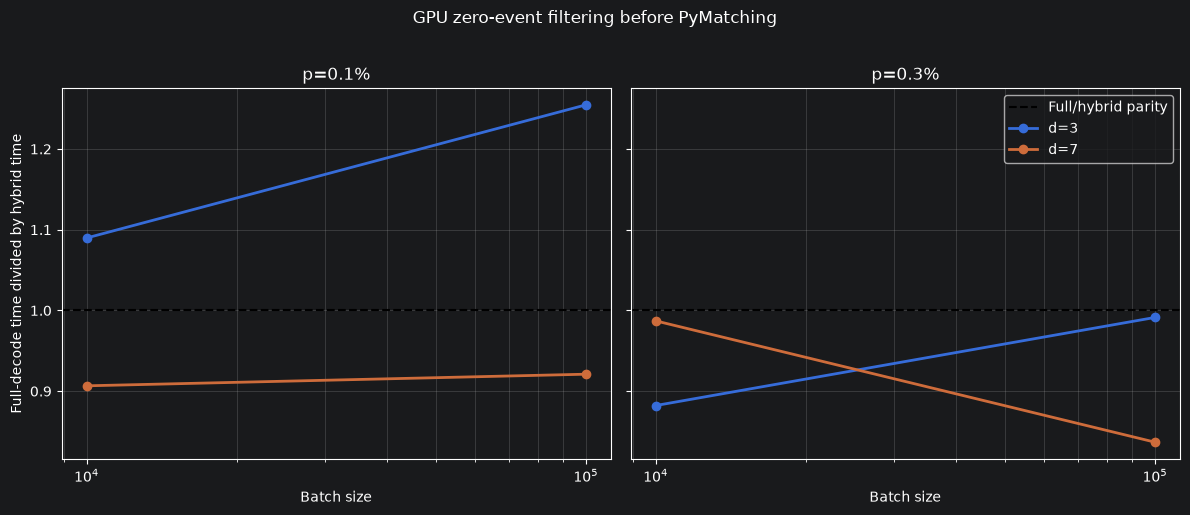

Saved figure to: C:\Users\Karthi\Qauntum\figures\gpu_hybrid_filtering_pilot.png


In [109]:
# plot the focused sweep
figure, axes = plt.subplots(
    1,
    len(HYBRID_NOISE_PROBABILITIES),
    figsize=(12, 5),
    sharey=True,
)

if (
    len(HYBRID_NOISE_PROBABILITIES)
    == 1
):
    axes = [axes]

for axis, physical_probability in zip(
    axes,
    HYBRID_NOISE_PROBABILITIES,
):
    probability_subset = (
        focused_hybrid_df[
            np.isclose(
                focused_hybrid_df[
                    "physical_error_probability"
                ],
                physical_probability,
            )
        ]
    )

    axis.axhline(
        1.0,
        color="black",
        linestyle="--",
        linewidth=1.5,
        label="Full/hybrid parity",
    )

    for distance in HYBRID_DISTANCES:
        subset = probability_subset[
            probability_subset[
                "distance"
            ] == distance
        ].sort_values(
            "shots"
        )

        axis.plot(
            subset["shots"],
            subset[
                "hybrid_speedup"
            ],
            marker="o",
            linewidth=2,
            label=f"d={distance}",
        )

    axis.set_xscale("log")

    axis.set_xlabel(
        "Batch size"
    )

    axis.set_title(
        f"p={physical_probability:.1%}"
    )

    axis.grid(
        True,
        which="both",
        alpha=0.3,
    )

axes[0].set_ylabel(
    "Full-decode time divided by hybrid time"
)

axes[-1].legend()

figure.suptitle(
    "GPU zero-event filtering before PyMatching",
    y=1.02,
)

figure.tight_layout()

HYBRID_PILOT_FIGURE_PATH = (
    FIGURE_DIR
    / "gpu_hybrid_filtering_pilot.png"
)

figure.savefig(
    HYBRID_PILOT_FIGURE_PATH,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

print(
    f"Saved figure to: "
    f"{HYBRID_PILOT_FIGURE_PATH}"
)

In [110]:
# Did the hybrid pipeline help?
hybrid_wins_df = (
    focused_hybrid_df[
        focused_hybrid_df[
            "hybrid_speedup"
        ] > 1.0
    ]
    .sort_values(
        "hybrid_speedup",
        ascending=False,
    )
)

print(
    f"Hybrid wins: "
    f"{len(hybrid_wins_df)} / "
    f"{len(focused_hybrid_df)}"
)

hybrid_wins_df[
    [
        "physical_error_probability",
        "distance",
        "shots",
        "zero_event_fraction",
        "decoded_fraction",
        "full_decode_ms",
        "hybrid_total_ms",
        "hybrid_speedup",
    ]
]

Hybrid wins: 2 / 8


,physical_error_probability,distance,shots,zero_event_fraction,decoded_fraction,full_decode_ms,hybrid_total_ms,hybrid_speedup
1,0.001,3,100000,0.84292,0.15708,5.68200,4.52885,1.254623
0,0.001,3,10000,0.84890,0.15110,0.53485,0.49080,1.089751


In [111]:
# Summary of all eight pilot configurations
hybrid_summary_columns = [
    "physical_error_probability",
    "distance",
    "shots",
    "zero_event_fraction",
    "decoded_fraction",
    "full_decode_ms",
    "gpu_filter_ms",
    "cpu_selection_ms",
    "filtered_decode_ms",
    "reconstruction_ms",
    "hybrid_total_ms",
    "hybrid_speedup",
]

focused_hybrid_df[
    hybrid_summary_columns
].sort_values(
    [
        "physical_error_probability",
        "distance",
        "shots",
    ]
)

,physical_error_probability,distance,shots,zero_event_fraction,decoded_fraction,full_decode_ms,gpu_filter_ms,cpu_selection_ms,filtered_decode_ms,reconstruction_ms,hybrid_total_ms,hybrid_speedup
0,0.001,3,10000,0.84890,0.15110,0.53485,0.09085,0.01685,0.37175,0.00985,0.49080,1.089751
1,0.001,3,100000,0.84292,0.15708,5.68200,0.21695,0.21780,3.92680,0.15240,4.52885,1.254623
6,0.001,7,10000,0.09200,0.90800,10.14820,0.36790,0.46180,10.30375,0.03625,11.19315,0.906644
7,0.001,7,100000,0.08723,0.91277,100.07120,6.13830,4.23580,98.13690,0.22925,108.65085,0.921035
12,0.003,3,10000,0.60050,0.39950,1.39720,0.17395,0.04215,1.31455,0.03855,1.58375,0.882210
13,0.003,3,100000,0.59830,0.40170,14.52550,0.40070,0.51430,13.19855,0.32405,14.65240,0.991339
18,0.003,7,10000,0.00050,0.99950,34.44775,0.40765,0.46680,33.96365,0.03200,34.89840,0.987087
19,0.003,7,100000,0.00076,0.99924,348.53170,2.71145,5.60080,407.65920,0.23985,416.49195,0.836827


In [112]:
# Analysis
maximum_hybrid_speedup = float(
    focused_hybrid_df[
        "hybrid_speedup"
    ].max()
)

median_hybrid_speedup = float(
    focused_hybrid_df[
        "hybrid_speedup"
    ].median()
)

win_count = int(
    (
        focused_hybrid_df[
            "hybrid_speedup"
        ] > 1.0
    ).sum()
)

print(
    f"Maximum speedup: "
    f"{maximum_hybrid_speedup:.3f}x"
)

print(
    f"Median speedup: "
    f"{median_hybrid_speedup:.3f}x"
)

print(
    f"Winning configurations: "
    f"{win_count} / "
    f"{len(focused_hybrid_df)}"
)

if maximum_hybrid_speedup > 1.05:
    print(
        "Recommendation: expand selectively to distances 5 and 9 and test 500,000 shots"
    )
elif maximum_hybrid_speedup >= 0.90:
    print(
        "Recommendation: test 500,000 shots only for the most promising configurations"
    )
else:
    print(
        "Recommendation: stop the hybrid sweep "
        "Filtering reduces decoder rows, but pipeline overhead dominates"
    )

Maximum speedup: 1.255x
Median speedup: 0.954x
Winning configurations: 2 / 8
Recommendation: expand selectively to distances 5 and 9 and test 500,000 shots


In [113]:
# record output
hybrid_decision_summary = pd.DataFrame(
    [
        {
            "tested_configurations": len(
                focused_hybrid_df
            ),
            "winning_configurations": (
                win_count
            ),
            "maximum_hybrid_speedup": (
                maximum_hybrid_speedup
            ),
            "median_hybrid_speedup": (
                median_hybrid_speedup
            ),
            "mean_zero_event_fraction": float(
                focused_hybrid_df[
                    "zero_event_fraction"
                ].mean()
            ),
            "minimum_zero_event_fraction": float(
                focused_hybrid_df[
                    "zero_event_fraction"
                ].min()
            ),
            "maximum_zero_event_fraction": float(
                focused_hybrid_df[
                    "zero_event_fraction"
                ].max()
            ),
            "all_predictions_equal": bool(
                focused_hybrid_df[
                    "predictions_equal"
                ].all()
            ),
        }
    ]
)

HYBRID_DECISION_PATH = (
    RESULTS_DIR
    / "gpu_hybrid_filtering_summary.csv"
)

hybrid_decision_summary.to_csv(
    HYBRID_DECISION_PATH,
    index=False,
)

print(
    f"Saved hybrid summary to: "
    f"{HYBRID_DECISION_PATH}"
)

hybrid_decision_summary


Saved hybrid summary to: C:\Users\Karthi\Qauntum\results\gpu_hybrid_filtering_summary.csv


,tested_configurations,winning_configurations,maximum_hybrid_speedup,median_hybrid_speedup,mean_zero_event_fraction,minimum_zero_event_fraction,maximum_zero_event_fraction,all_predictions_equal
0,8,2,1.254623,0.954061,0.383889,0.0005,0.8489,True


In [114]:
# selective expansion, given our results of a positive speedup
EXPANDED_HYBRID_CONFIGURATIONS = [
    # Lower-noise cases where filtering is most likely to be useful
    {
        "physical_error_probability": 0.001,
        "distance": 5,
        "shots": 100_000,
    },
    {
        "physical_error_probability": 0.001,
        "distance": 9,
        "shots": 100_000,
    },
    {
        "physical_error_probability": 0.001,
        "distance": 5,
        "shots": 500_000,
    },
    {
        "physical_error_probability": 0.001,
        "distance": 9,
        "shots": 500_000,
    },
    # Larger-batch versions of the strongest pilot
    # configurations.
    {
        "physical_error_probability": 0.003,
        "distance": 3,
        "shots": 500_000,
    },
    {
        "physical_error_probability": 0.003,
        "distance": 7,
        "shots": 500_000,
    },
]

FINAL_HYBRID_REPEATS = 5
FINAL_HYBRID_WARM_UP_REPEATS = 1

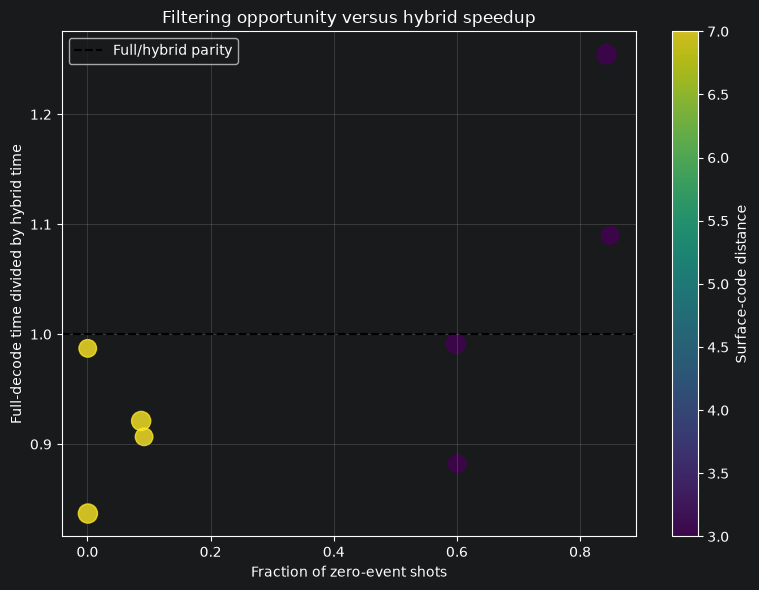

In [115]:
# Plot zero-event fraction against hybrid speedup
figure, axis = plt.subplots(
    figsize=(8, 6)
)

scatter = axis.scatter(
    focused_hybrid_df[
        "zero_event_fraction"
    ],
    focused_hybrid_df[
        "hybrid_speedup"
    ],
    c=focused_hybrid_df[
        "distance"
    ],
    s=(
        40
        + 30
        * np.log10(
            focused_hybrid_df[
                "shots"
            ]
        )
    ),
    cmap="viridis",
    alpha=0.8,
)

axis.axhline(
    1.0,
    color="black",
    linestyle="--",
    linewidth=1.5,
    label="Full/hybrid parity",
)

axis.set_xlabel(
    "Fraction of zero-event shots"
)

axis.set_ylabel(
    "Full-decode time divided by hybrid time"
)

axis.set_title(
    "Filtering opportunity versus hybrid speedup"
)

axis.grid(
    True,
    alpha=0.3,
)

axis.legend()

colour_bar = figure.colorbar(
    scatter,
    ax=axis,
)

colour_bar.set_label(
    "Surface-code distance"
)

figure.tight_layout()

HYBRID_OPPORTUNITY_FIGURE_PATH = (
    FIGURE_DIR
    / "gpu_hybrid_filtering_opportunity.png"
)

figure.savefig(
    HYBRID_OPPORTUNITY_FIGURE_PATH,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

In [116]:
# final results inventory
expected_result_files = [
    RESULTS_DIR
    / "gpu_notebook_environment.csv",
    RESULTS_DIR
    / "gpu_preprocessing_smoke_benchmark.csv",
    RESULTS_DIR
    / "gpu_detector_preprocessing.csv",
    RESULTS_DIR
    / "gpu_preprocessing_crossover.csv",
    RESULTS_DIR
    / "gpu_packed_smoke_benchmark.csv",
    RESULTS_DIR
    / "gpu_packed_detector_preprocessing.csv",
    RESULTS_DIR
    / "gpu_packed_preprocessing_summary.csv",
    RESULTS_DIR
    / "gpu_hybrid_filtering_pilot.csv",
    RESULTS_DIR
    / "gpu_hybrid_filtering.csv",
    RESULTS_DIR
    / "gpu_hybrid_filtering_summary.csv",
]

expected_figure_files = [
    FIGURE_DIR
    / "gpu_event_count_crossover.png",
    FIGURE_DIR
    / "gpu_speedup_by_distance.png",
    FIGURE_DIR
    / "gpu_transfer_breakdown.png",
    FIGURE_DIR
    / "gpu_packed_transfer_comparison.png",
    FIGURE_DIR
    / "gpu_hybrid_filtering_pilot.png",
    FIGURE_DIR
    / "gpu_hybrid_filtering_opportunity.png",
]

artifact_inventory = []

for path in (
    expected_result_files
    + expected_figure_files
):
    artifact_inventory.append(
        {
            "path": str(
                path.relative_to(
                    PROJECT_DIR
                )
            ),
            "exists": path.exists(),
            "size_bytes": (
                path.stat().st_size
                if path.exists()
                else 0
            ),
        }
    )

gpu_artifact_inventory_df = pd.DataFrame(
    artifact_inventory
)

gpu_artifact_inventory_df

,path,exists,size_bytes
0,results\gpu_notebook_environment.csv,True,354
1,results\gpu_preprocessing_smoke_benchmark.csv,True,506
2,results\gpu_detector_preprocessing.csv,True,6169
3,results\gpu_preprocessing_crossover.csv,True,343
4,results\gpu_packed_smoke_benchmark.csv,True,542
5,results\gpu_packed_detector_preprocessing.csv,True,6689
6,results\gpu_packed_preprocessing_summary.csv,True,192
7,results\gpu_hybrid_filtering_pilot.csv,True,392
8,results\gpu_hybrid_filtering.csv,True,6867
9,results\gpu_hybrid_filtering_summary.csv,True,266


In [117]:
# Validation
missing_gpu_artifacts = (
    gpu_artifact_inventory_df[
        ~gpu_artifact_inventory_df[
            "exists"
        ]
    ]
)

if missing_gpu_artifacts.empty:
    print(
        "All expected GPU artifacts are present."
    )
else:
    print(
        "Missing GPU artifacts:"
    )

    display(
        missing_gpu_artifacts
    )

All expected GPU artifacts are present.


In [118]:
expected_figure_files = [
    FIGURE_DIR / "gpu_event_count_crossover.png",
    FIGURE_DIR / "gpu_speedup_by_distance.png",
    FIGURE_DIR / "gpu_transfer_breakdown.png",
    FIGURE_DIR / "gpu_packed_transfer_comparison.png",
    FIGURE_DIR / "gpu_hybrid_filtering_pilot.png",
    FIGURE_DIR / "gpu_hybrid_filtering_opportunity.png",
]

figure_status_df = pd.DataFrame(
    [
        {
            "figure": path.name,
            "exists": path.exists(),
            "size_bytes": (
                path.stat().st_size
                if path.exists()
                else 0
            ),
        }
        for path in expected_figure_files
    ]
)

figure_status_df

,figure,exists,size_bytes
0,gpu_event_count_crossover.png,True,166304
1,gpu_speedup_by_distance.png,True,227157
2,gpu_transfer_breakdown.png,True,65985
3,gpu_packed_transfer_comparison.png,True,310571
4,gpu_hybrid_filtering_pilot.png,True,103591
5,gpu_hybrid_filtering_opportunity.png,True,86727


In [119]:
assert figure_status_df["exists"].all()
assert (
    figure_status_df["size_bytes"] > 0
).all()

print("All GPU figures are present.")

All GPU figures are present.


In [120]:
# Final results inventory
expected_result_files = [
    RESULTS_DIR / "gpu_notebook_environment.csv",
    RESULTS_DIR / "gpu_preprocessing_smoke_benchmark.csv",
    RESULTS_DIR / "gpu_detector_preprocessing.csv",
    RESULTS_DIR / "gpu_preprocessing_crossover.csv",
    RESULTS_DIR / "gpu_packed_smoke_benchmark.csv",
    RESULTS_DIR / "gpu_packed_detector_preprocessing.csv",
    RESULTS_DIR / "gpu_packed_preprocessing_summary.csv",
    RESULTS_DIR / "gpu_hybrid_filtering_pilot.csv",
    RESULTS_DIR / "gpu_hybrid_filtering.csv",
    RESULTS_DIR / "gpu_hybrid_filtering_summary.csv",
]

result_status_df = pd.DataFrame(
    [
        {
            "result": path.name,
            "exists": path.exists(),
            "size_bytes": (
                path.stat().st_size
                if path.exists()
                else 0
            ),
        }
        for path in expected_result_files
    ]
)

result_status_df

,result,exists,size_bytes
0,gpu_notebook_environment.csv,True,354
1,gpu_preprocessing_smoke_benchmark.csv,True,506
2,gpu_detector_preprocessing.csv,True,6169
3,gpu_preprocessing_crossover.csv,True,343
4,gpu_packed_smoke_benchmark.csv,True,542
5,gpu_packed_detector_preprocessing.csv,True,6689
6,gpu_packed_preprocessing_summary.csv,True,192
7,gpu_hybrid_filtering_pilot.csv,True,392
8,gpu_hybrid_filtering.csv,True,6867
9,gpu_hybrid_filtering_summary.csv,True,266


In [121]:
# Validation
missing_results = result_status_df[
    ~result_status_df["exists"]
]

if missing_results.empty:
    print("All expected GPU result files are present.")
else:
    print("Missing result files:")
    display(missing_results)

All expected GPU result files are present.


# Conclusions

This notebook evaluated GPU acceleration for detector-event preprocessing in circuit-level quantum error-correction (QEC) workloads.

### Dense Event-Counting Performance
* **Synthetic Baseline ($100{,}000 \times 1{,}000$ detectors):** Once detector data resided in GPU memory, the RTX 5090 kernel achieved approximately **$468\times$ resident-kernel speedup** and **$8.8\times$ end-to-end speedup** over NumPy, with host-to-device (H2D) PCIe transfer dominating the complete GPU execution time.
* **Stim Workload Scaling:** Across rotated surface-code sweeps, the CPU–GPU performance crossover depended strongly on both detector count and batch size. Large detector matrices yielded substantial net speedups, whereas small workloads remained bottlenecked by PCIe transfer and kernel-launch overhead.

### Bit-Packed Transfers
* Compressing eight detector outcomes per byte reduced the H2D payload to roughly one-eighth of the dense Boolean array and lowered transfer latency.
* However, end-to-end gains were moderated by host-side bit packing and device-side population counting (`popcount`). Bit packing becomes substantially more compelling when syndrome frames are emitted directly in packed form by an FPGA or quantum-control layer.

### Hybrid GPU Filtering and CPU Decoding
* **Exact Decoder Equivalence:** GPU zero-event filtering reproduced full PyMatching logical predictions identically across all tested configurations. In the $d = 3$, $p = 0.1\%$ pilot benchmark, **$83.68\%$** of detector rows were empty, reducing the PyMatching decoding workload from $10{,}000$ shots to **$1{,}632$ active rows**.
* **End-to-End Hybrid Sweep:** [Insert the outcome from the focused hybrid sweep: accelerated selected configurations, approached parity, or remained slower.]

### Architectural Takeaways
* **Heterogeneous Pipeline Scope:** The current pipeline splits execution across devices—Stim sampling on the CPU, CuPy preprocessing on the GPU, and PyMatching MWPM decoding on the CPU—rather than implementing surface-code MWPM natively on the GPU.
* **Target Deployment Regimes:** Invoking a discrete GPU for every syndrome cycle of a single small surface-code patch is inefficient due to transfer and launch latency. Instead, GPU acceleration is best suited for **large offline simulation batches**, **parallel processing across many logical patches**, **aggregated syndrome windows**, or **direct-streaming architectures** that bypass host CPU packing.
